> **Legacy Archive Note:** This 81-cell monolithic notebook is preserved intact as the pre-refactor reference implementation and historical output record. All core data loading, subgraph sampling, 14-feature engineering, purged splitting, tuning, calibration, and plotting logic now lives in `src/aml_graph/` (driven by `configs/*.yaml` and `Makefile`), and the root presentation notebook `AML_Graph_Structure_Transfer.ipynb` loads saved outputs without re-implementing pipeline code.

# Structural Graph Features for Anti-Money-Laundering Detection — IBM AML HI-Small vs Elliptic2

**Author:** Ilia Jakhaia

**Research question:** Can structural features of directed transaction subgraphs distinguish suspicious from licit activity, and does a model trained on one domain (synthetic bank transfers, IBM AML HI-Small) transfer to another (real Bitcoin cluster graphs, Elliptic2)?

**Approach**
1. Build labelled subgraphs: IBM positives from 370 documented laundering attempts, negatives from size- and window-matched BFS samples (1:20); Elliptic2 uses its 121,810 labelled connected components.
2. Describe every subgraph with 14 interpretable directed-graph features (size, density, degree concentration, sources/sinks/pass-through, longest chain, cycles, reciprocity).
3. Evaluate Logistic Regression, Random Forest, Histogram Gradient Boosting, ExtraTrees and a size-only baseline within and across datasets, using leakage-aware splits (chronological + transaction-overlap purge for IBM, stratified + cluster purge for Elliptic2).
4. Choose hyperparameters, probability calibration and decision thresholds on source **validation** data only; report outer-test AP with 95% bootstrap CIs.
5. Run robustness experiments: common-BFS construction for both classes, account-disjoint retraining, feature ablation, permutation importance, domain-shift diagnostics, transaction-activity features and per-typology recall.

**Data:** downloaded automatically by the data cell (IBM AML HI-Small: `HI-Small_Trans.csv`, `HI-Small_Patterns.txt`; Elliptic2: `connected_components.csv`, `nodes.csv`, `edges.csv`). See README for sources and citations.

> Labels are dataset annotations, not proof of crime. This is a research/educational analysis, not a deployable AML system.

## 2. Imports, reproducibility, directories, and logging

**Description:** Prepare Python dependencies and where project files will be stored. This setup must run before later cells because they use variables such as `IBM_DIR`, `OUT`, `SEED`, and `LOG`.

**Important code explained:**

- `import numpy as np` provides arrays and numerical operations; `import pandas as pd` provides tables (DataFrames); `import networkx as nx` provides graph objects and algorithms; `import matplotlib.pyplot as plt` handles plots.
- `SEED = 42` defines a reproducible seed. `rng = np.random.default_rng(SEED)` creates the random-number generator used by negative sampling.
- `Path.cwd()` is the current working directory. Expressions such as `PROJECT / "data" / "ibm"` assemble platform-independent paths.
- `mkdir(parents=True, exist_ok=True)` creates folders when needed and does not fail if they already exist.
- `LOG = {...}` stores facts as a nested dictionary. The `note(section, key, value, why="")` function both saves a result and prints it in a readable format.
- The version printout is useful when debugging software-compatibility problems.

**Inputs / outputs:** No dataset is processed here. It creates directories, initializes variables, and prints package versions.

In [1]:
import os, sys, re, json, time, pickle, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import sklearn
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
SEED = 42
rng = np.random.default_rng(SEED)

PROJECT = Path.cwd()
IBM_DIR = PROJECT / "data" / "ibm"
ELL_DIR = PROJECT / "data" / "elliptic2"
OUT     = PROJECT / "outputs"
for d in (IBM_DIR, ELL_DIR, OUT):
    d.mkdir(parents=True, exist_ok=True)

LOG = {"collection": {}, "ibm": {}, "elliptic2": {}, "subgraphs": {}}   # facts for the write-up

def note(section, key, value, why=""):
    LOG[section][key] = value
    print(f"{key:45s} {value}" + (f"   <- {why}" if why else ""))

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| networkx", nx.__version__, "| sklearn", sklearn.__version__)
print("Project folder:", PROJECT)

Python 3.14.6 | pandas 3.0.3 | networkx 3.6.1 | sklearn 1.9.1
Project folder: <PROJECT_DIR>


## 3. Locate and download five dataset files

**Description:** Define the two datasets' file locations and download any missing inputs from their configured Hugging Face repository URLs. Later processing expects these files to exist locally.

**Important code explained:**

- `HF = "https://huggingface.co/datasets/{repo}/resolve/main/{name}"` is a URL template. `.format(repo=..., name=...)` fills the placeholders.
- `SOURCES` is a Python **dictionary** that associates each filename with its remote repository and local folder.
- `for name, (repo, folder) in SOURCES.items():` loops over the dictionary and unpacks each tuple.
- `path.exists()` avoids downloading files that are already present.
- `urllib.request.urlretrieve(url, path)` downloads a missing file.
- `path.stat().st_size / 1e6` converts file bytes to approximate **decimal megabytes**.
- `LOG["collection"]` stores the resolved URL and file size for the report.

**Expected files:** IBM: `HI-Small_Trans.csv`, `HI-Small_Patterns.txt`. Elliptic2: `connected_components.csv`, `nodes.csv`, `edges.csv`.

**Methodological caution:** The `/resolve/main/` URLs reference a mutable repository branch. For rigorous reproducibility, record a revision/commit and checksums. `path.exists()` verifies presence, **not** file correctness.

In [2]:
HF = "https://huggingface.co/datasets/{repo}/resolve/main/{name}"
SOURCES = {
    "HI-Small_Trans.csv":       ("OsamaMIT/IBM-AML-HI",          IBM_DIR),  # ~476 MB
    "HI-Small_Patterns.txt":    ("OsamaMIT/IBM-AML-HI",          IBM_DIR),  # ~0.3 MB
    "connected_components.csv": ("mendozzzz/elliptic2-data-set", ELL_DIR),  # ~1.6 MB
    "nodes.csv":                ("mendozzzz/elliptic2-data-set", ELL_DIR),  # ~7.5 MB
    "edges.csv":                ("mendozzzz/elliptic2-data-set", ELL_DIR),  # ~11 MB
}
LOG["collection"]["date"] = time.strftime("%Y-%m-%d")
for name, (repo, folder) in SOURCES.items():
    path, url = folder / name, HF.format(repo=repo, name=name)
    if path.exists():
        how = "already downloaded"
    else:
        t0 = time.time()
        print(f"downloading {name} ...", flush=True)
        urllib.request.urlretrieve(url, path)
        how = f"downloaded in {time.time() - t0:.0f}s"
    mb = round(path.stat().st_size / 1e6, 1)
    LOG["collection"][name] = {"url": url, "size_mb": mb}
    print(f"{name:28s} {mb:8.1f} MB   {how}")

HI-Small_Trans.csv              475.7 MB   already downloaded
HI-Small_Patterns.txt             0.3 MB   already downloaded
connected_components.csv          1.6 MB   already downloaded
nodes.csv                         7.5 MB   already downloaded
edges.csv                        11.4 MB   already downloaded


## 4. Load and audit raw IBM transaction data

**Description:** Read transaction-level banking data into a pandas DataFrame and examine its schema, size, label imbalance, duplicates, and payment characteristics before cleaning.

**Important code explained:**

- `COLS` contains the standardized 11 field names, including timestamp, sending bank/account, receiving bank/account, amounts, currencies, payment format, and `is_laundering`.
- `TEXT` identifies columns that must remain strings. Account numbers are identifiers, not quantities; preserving text helps avoid unwanted numeric transformations.
- `pd.read_csv(..., header=0, names=COLS, dtype=...)` loads the CSV, consumes its header row, replaces the column names, and controls selected data types.
- `len(ibm)` counts rows; `ibm.isna().sum()` counts missing values by column.
- `ibm["is_laundering"].sum()` counts labeled laundering transactions **if** labels are encoded as zero/one.
- `ibm.duplicated().sum()` counts exact duplicate records.
- `value_counts()` summarizes the frequency of payment formats.
- `ibm.head()` previews the beginning of the DataFrame.

**Important distinction:** This is *transaction-level* label prevalence. Later, your classifier uses *subgraph-level* labels with a different positive rate.

In [3]:
COLS = ["timestamp", "from_bank", "from_acct", "to_bank", "to_acct",
        "amount_received", "receiving_currency", "amount_paid",
        "payment_currency", "payment_format", "is_laundering"]
TEXT = ["from_bank", "from_acct", "to_bank", "to_acct",
        "receiving_currency", "payment_currency", "payment_format"]

t0 = time.time()
ibm = pd.read_csv(IBM_DIR / "HI-Small_Trans.csv", header=0, names=COLS,
                  dtype={c: str for c in TEXT})   # two "Account" columns -> renamed
print(f"loaded in {time.time() - t0:.0f}s\n")

note("ibm", "raw_rows", len(ibm), "paper: ~5.08M")
note("ibm", "null_values_per_column", {k: int(v) for k, v in ibm.isna().sum().items() if v})
note("ibm", "laundering_rows", int(ibm["is_laundering"].sum()))
note("ibm", "laundering_rate_1_in", round(len(ibm) / ibm["is_laundering"].sum(), 1), "paper: ~1 in 981")
note("ibm", "exact_duplicate_rows", int(ibm.duplicated().sum()))
note("ibm", "cross_currency_rows", int((ibm.receiving_currency != ibm.payment_currency).sum()),
     "amounts not used: features are structural")
print("\nPayment formats:\n", ibm["payment_format"].value_counts().to_string())
ibm.head()

loaded in 3s

raw_rows                                      5078345   <- paper: ~5.08M
null_values_per_column                        {}
laundering_rows                               5177
laundering_rate_1_in                          980.9   <- paper: ~1 in 981
exact_duplicate_rows                          9
cross_currency_rows                           72170   <- amounts not used: features are structural

Payment formats:
 payment_format
Cheque          1864331
Credit Card     1323324
ACH              600797
Cash             490891
Reinvestment     481056
Wire             171855
Bitcoin          146091


,timestamp,from_bank,from_acct,to_bank,to_acct,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering
0,2022/09/01 00:20,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0


## 5. Clean IBM transactions and create graph-node IDs

**Description:** Remove unusable records, parse timestamps, create globally consistent account keys, and convert account identities to compact integer IDs for graph processing.

**Important code explained:**

1. `dropna(subset=[...])` removes rows with missing required fields.
2. `pd.to_datetime(..., errors="coerce")` attempts to parse the timestamp. Invalid dates become missing and are dropped. `reset_index(drop=True)` rebuilds sequential DataFrame row positions.
3. `.astype(int)` converts `is_laundering` to integer class labels.
4. `norm_bank(s)` strips whitespace and leading zeros from bank IDs (`"012"` and `"12"` become the same normalized bank ID).
5. `account_key(bank, acct)` combines normalized bank ID and uppercased account ID, such as `12_A101`. This prevents account `A101` at two banks from being merged.
6. `pd.factorize(pd.concat([ibm["src"], ibm["dst"]]))` maps unique account keys to integer node IDs. The resulting `s` and `d` columns are source and destination node numbers.
7. `groupby(["s", "d"]).size()` counts how often a directed account pair occurs. The later `nx.DiGraph` retains one edge per directed pair rather than transaction multiplicity.

**Simple example:** `Bank 12 / Account 17` and `Bank 45 / Account 17` are **two nodes** despite the shared account number.

**Caution:** Normalizing away leading zeros is justified only if the data source indeed treats them as equivalent bank identifiers.

In [4]:
before = len(ibm)
ibm = ibm.dropna(subset=["timestamp", "from_bank", "from_acct", "to_bank", "to_acct", "is_laundering"])
ibm["timestamp"] = pd.to_datetime(ibm["timestamp"], format="%Y/%m/%d %H:%M", errors="coerce")
ibm = ibm.dropna(subset=["timestamp"]).reset_index(drop=True)
ibm["is_laundering"] = ibm["is_laundering"].astype(int)
note("ibm", "rows_dropped_missing_or_bad_date", before - len(ibm))

def norm_bank(s):                      # "012" and "12" are the same bank
    s = s.astype(str).str.strip().str.lstrip("0")
    return s.where(s != "", "0")

def account_key(bank, acct):           # account numbers are unique only within a bank
    return norm_bank(bank) + "_" + acct.astype(str).str.strip().str.upper()

ibm["src"] = account_key(ibm["from_bank"], ibm["from_acct"])
ibm["dst"] = account_key(ibm["to_bank"], ibm["to_acct"])
codes, ACCOUNTS = pd.factorize(pd.concat([ibm["src"], ibm["dst"]]))
ibm["s"], ibm["d"] = codes[:len(ibm)], codes[len(ibm):]
ACC_ID = pd.Series(np.arange(len(ACCOUNTS)), index=ACCOUNTS)

note("ibm", "unique_accounts", len(ACCOUNTS))
note("ibm", "self_loop_rows", int((ibm.s == ibm.d).sum()), "excluded from graph features")
note("ibm", "time_range", [str(ibm.timestamp.min()), str(ibm.timestamp.max())])
pairs = ibm.groupby(["s", "d"]).size()
note("ibm", "distinct_directed_account_pairs", len(pairs))
note("ibm", "share_of_pairs_with_repeat_transactions", round(float((pairs > 1).mean()), 4),
     "multi-edges collapsed later")

rows_dropped_missing_or_bad_date              0
unique_accounts                               515088
self_loop_rows                                591212   <- excluded from graph features
time_range                                    ['2022-09-01 00:00:00', '2022-09-18 16:18:00']
distinct_directed_account_pairs               1015736
share_of_pairs_with_repeat_transactions       0.5529   <- multi-edges collapsed later


## 6. Parse documented laundering attempts

**Description:** Read IBM's laundering-pattern text file, recover each annotated attempt, and measure how well those attempts cover the positive transaction labels in the CSV.

**Important code explained:**

- `line.startswith("BEGIN LAUNDERING ATTEMPT")` detects a new attempt; `END LAUNDERING ATTEMPT` closes it.
- `re.search(...)` is a **regular expression** that tries to extract the attack/pattern type from the heading.
- `cur = {"pattern": ..., "rows": []}` creates a record for the active attempt.
- `line.split(",")` splits a transaction record into fields and `.strip()` removes surrounding whitespace.
- `attempts.append(cur)` saves each nonempty completed attempt.
- The list comprehension `[r for a in attempts for r in a["rows"]]` flattens all attempts into one list of transaction rows.
- The code builds comparable timestamp/account keys, then `merge(..., how="left", indicator=True)` checks which labeled laundering transactions match entries from the attempts file.
- `"_merge" == "both"` means a transaction key appears on both sides of the join.

**Caution:** This matching uses timestamp, source account, and destination account, not every original transaction field. Two payments with the same key could make matching ambiguous. The regex and comma-splitting approach also assume the file follows the expected format.

In [5]:
attempts, cur = [], None
for line in open(IBM_DIR / "HI-Small_Patterns.txt", encoding="utf-8", errors="replace"):
    line = line.strip()
    if line.startswith("BEGIN LAUNDERING ATTEMPT"):
        m = re.search(r"ATTEMPT\s*-\s*([A-Za-z\- ]+?)(?::|$)", line)
        cur = {"pattern": m.group(1).strip().upper() if m else "UNKNOWN", "rows": []}
    elif line.startswith("END LAUNDERING ATTEMPT"):
        if cur and cur["rows"]:
            attempts.append(cur)
        cur = None
    elif cur is not None and line:
        cur["rows"].append([p.strip() for p in line.split(",")][:11])

note("ibm", "laundering_attempts", len(attempts))
note("ibm", "attempts_by_pattern", pd.Series([a["pattern"] for a in attempts]).value_counts().to_dict())

# how much of the laundering is covered by documented attempts?
pat = pd.DataFrame([r for a in attempts for r in a["rows"]], columns=COLS)
pat["timestamp"] = pd.to_datetime(pat["timestamp"], format="%Y/%m/%d %H:%M", errors="coerce")
pat["src"] = account_key(pat["from_bank"], pat["from_acct"])
pat["dst"] = account_key(pat["to_bank"], pat["to_acct"])
key = ["timestamp", "src", "dst"]
m = ibm.loc[ibm.is_laundering == 1, key].merge(pat[key].drop_duplicates(), on=key,
                                               how="left", indicator=True)
note("ibm", "pattern_coverage_of_laundering_rows", round(float((m["_merge"] == "both").mean()), 4),
     "laundering outside patterns cannot be a positive")
note("ibm", "pattern_accounts_missing_from_transactions",
     int((~pd.concat([pat.src, pat.dst]).isin(ACC_ID.index)).sum()))

laundering_attempts                           370
attempts_by_pattern                           {'CYCLE': 54, 'GATHER-SCATTER': 51, 'BIPARTITE': 49, 'FAN-OUT': 48, 'SCATTER-GATHER': 44, 'STACK': 43, 'RANDOM': 41, 'FAN-IN': 40}
pattern_coverage_of_laundering_rows           0.6199   <- laundering outside patterns cannot be a positive
pattern_accounts_missing_from_transactions    0


## 7. Sanity-check all downloaded source files

**Description:** Independently inspect what is on disk: expected file presence, size, basic columns, first records, transaction counts, and laundering-pattern headings.

**Important code explained:**

- `FOLDERS` and `EXPECTED` are dictionaries listing where each dataset's files should be.
- `folder.glob("*")` lists files inside a directory.
- `p.stat().st_size` obtains file sizes.
- `pd.read_csv(ibm_csv, nrows=5)` previews only five rows rather than loading the whole CSV again.
- `sum(1 for _ in open(ibm_csv)) - 1` counts lines after the header; it assumes one CSV record per physical line.
- `display(preview)` shows a readable table in Jupyter.
- The pattern-file check counts lines beginning with `BEGIN LAUNDERING ATTEMPT`.
- The Elliptic2 loop inspects each of the three input files and summarizes the component labels.

**Practical detail:** This is a *diagnostic cell*, not an additional modeling stage. A large-file line count may be slow, and row-count-by-newline can differ from CSV record count if the data contain embedded newlines.

In [6]:
# ============================================================
# Data check - what do we have from IBM and Elliptic2?
# ============================================================
from pathlib import Path
import pandas as pd

PROJECT = Path.cwd()
FOLDERS = {"IBM": PROJECT / "data" / "ibm", "Elliptic2": PROJECT / "data" / "elliptic2"}
EXPECTED = {"IBM": ["HI-Small_Trans.csv", "HI-Small_Patterns.txt"],
            "Elliptic2": ["connected_components.csv", "nodes.csv", "edges.csv"]}

# 1) Which files exist and how big are they?
print("=" * 70, "\nFILES ON DISK\n" + "=" * 70)
for ds, folder in FOLDERS.items():
    print(f"\n{ds}  ({folder})")
    present = {p.name: p for p in folder.glob("*")} if folder.exists() else {}
    for name in EXPECTED[ds]:
        p = present.get(name)
        print(f"   {'OK     ' if p else 'MISSING'} {name:28s} {p.stat().st_size/1e6:9.1f} MB" if p
              else f"   MISSING {name}")
    extra = [n for n in present if n not in EXPECTED[ds]]
    if extra:
        print("   other files:", extra)

# 2) What is inside each file?
print("\n" + "=" * 70, "\nCONTENTS\n" + "=" * 70)
ibm_csv = FOLDERS["IBM"] / "HI-Small_Trans.csv"
if ibm_csv.exists():
    preview = pd.read_csv(ibm_csv, nrows=5)
    n_rows = sum(1 for _ in open(ibm_csv)) - 1
    print(f"\nIBM HI-Small_Trans.csv: {n_rows:,} transactions, columns:")
    print("  ", list(preview.columns))
    display(preview)

pat_txt = FOLDERS["IBM"] / "HI-Small_Patterns.txt"
if pat_txt.exists():
    lines = open(pat_txt).read().splitlines()
    begins = [l for l in lines if l.startswith("BEGIN LAUNDERING ATTEMPT")]
    types = pd.Series([l.split("-", 1)[1].split(":")[0].strip() for l in begins]).value_counts()
    print(f"\nIBM HI-Small_Patterns.txt: {len(begins):,} laundering attempts")
    print(types.to_string())
    print("first lines:\n  " + "\n  ".join(lines[:3]))

for name in EXPECTED["Elliptic2"]:
    p = FOLDERS["Elliptic2"] / name
    if p.exists():
        df = pd.read_csv(p)
        print(f"\nElliptic2 {name}: {len(df):,} rows, columns {list(df.columns)}")
        if name == "connected_components.csv":
            print("   labels:", df.iloc[:, 1].value_counts().to_dict(),
                  "  (paper: 119,047 licit / 2,763 suspicious)")
        display(df.head(3))

FILES ON DISK

IBM  (<PROJECT_DIR>/data/ibm)
   OK      HI-Small_Trans.csv               475.7 MB
   OK      HI-Small_Patterns.txt              0.3 MB

Elliptic2  (<PROJECT_DIR>/data/elliptic2)
   OK      connected_components.csv           1.6 MB
   OK      nodes.csv                          7.5 MB
   OK      edges.csv                         11.4 MB

CONTENTS

IBM HI-Small_Trans.csv: 5,078,345 transactions, columns:
   ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


,Timestamp,From Bank,Account,To Bank,Account.1,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0



IBM HI-Small_Patterns.txt: 370 laundering attempts
CYCLE             54
GATHER-SCATTER    51
BIPARTITE         49
FAN-OUT           48
SCATTER-GATHER    44
STACK             43
RANDOM            41
FAN-IN            40
first lines:
  BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 16-degree Fan-Out
  2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,2848.96,Euro,ACH,1
  2022/09/01 04:33,021174,800737690,020,80020C5B0,8630.40,Euro,8630.40,Euro,ACH,1

Elliptic2 connected_components.csv: 121,810 rows, columns ['ccId', 'ccLabel']
   labels: {'licit': 119047, 'suspicious': 2763}   (paper: 119,047 licit / 2,763 suspicious)


,ccId,ccLabel
0,0,licit
1,1,licit
2,2,licit



Elliptic2 nodes.csv: 444,521 rows, columns ['clId', 'ccId']


,clId,ccId
0,515498410,41121
1,630366534,27974
2,903790945,108020



Elliptic2 edges.csv: 367,137 rows, columns ['clId1', 'clId2', 'txId']


,clId1,clId2,txId
0,753456251,753456254,29911377
1,756183927,759736869,51855
2,623574254,622935561,27784128


## 8. Load Elliptic2 and standardize subgraph labels

**Description:** Read Elliptic2's connected-components, nodes, and edges tables. Convert labels into binary target values and investigate overlapping cluster memberships and component sizes.

**Important code explained:**

- `cc`, `nodes`, and `edges` are pandas DataFrames loaded from three separate CSV files.
- `CC_ID`, `CC_LAB`, `N_ID`, `N_CC`, `E_SRC`, and `E_DST` are aliases for column names, which keeps later code readable.
- `.str.strip().str.lower().map({"suspicious": 1, "licit": 0})` converts textual labels into `1` and `0`. Unknown labels become missing and are removed.
- `nodes.duplicated([N_ID, N_CC])` detects repeated entries of the same cluster/component pair.
- `nodes.groupby(N_ID)[N_CC].nunique()` counts how many components each cluster belongs to. If a cluster appears in more than one component, a naive random train/test split may leak structural information.
- `groupby(N_CC).size()` measures number of nodes per subgraph.

**Methodological caution:** An Elliptic2 cluster is not equivalent to an IBM bank account. Both can be represented as graph nodes, but they originate from different systems and labeling procedures.

In [7]:
cc    = pd.read_csv(ELL_DIR / "connected_components.csv")
nodes = pd.read_csv(ELL_DIR / "nodes.csv")
edges = pd.read_csv(ELL_DIR / "edges.csv")
CC_ID, CC_LAB, N_ID, N_CC, E_SRC, E_DST = "ccId", "ccLabel", "clId", "ccId", "clId1", "clId2"

cc["label"] = cc[CC_LAB].str.strip().str.lower().map({"suspicious": 1, "licit": 0})
for k, ours, paper in [("labeled_subgraphs", len(cc), 121_810),
                       ("licit", int((cc.label == 0).sum()), 119_047),
                       ("suspicious", int((cc.label == 1).sum()), 2_763)]:
    note("elliptic2", k, ours, f"paper: {paper:,} -> {'OK' if ours == paper else 'DIFFERENT'}")
note("elliptic2", "unknown_labels_dropped", int(cc.label.isna().sum()))
cc = cc.dropna(subset=["label"])

note("elliptic2", "node_rows", len(nodes))
note("elliptic2", "edge_rows", len(edges))
note("elliptic2", "duplicate_node_rows", int(nodes.duplicated([N_ID, N_CC]).sum()))
nodes = nodes.drop_duplicates([N_ID, N_CC])
shared = nodes.groupby(N_ID)[N_CC].nunique()
note("elliptic2", "clusters_in_more_than_one_subgraph", int((shared > 1).sum()),
     "leakage risk -> purged split")
note("elliptic2", "max_subgraphs_sharing_one_cluster", int(shared.max()))

sizes = nodes.groupby(N_CC).size().rename("n_nodes").to_frame().join(cc.set_index(CC_ID)["label"])
print("\nNodes per subgraph by class (paper: mean 3.65 licit / 3.79 suspicious, median 3):")
print(sizes.groupby("label")["n_nodes"].describe().round(2))

labeled_subgraphs                             121810   <- paper: 121,810 -> OK
licit                                         119047   <- paper: 119,047 -> OK
suspicious                                    2763   <- paper: 2,763 -> OK
unknown_labels_dropped                        0
node_rows                                     444521
edge_rows                                     367137
duplicate_node_rows                           0
clusters_in_more_than_one_subgraph            0   <- leakage risk -> purged split
max_subgraphs_sharing_one_cluster             1

Nodes per subgraph by class (paper: mean 3.65 licit / 3.79 suspicious, median 3):
          count  mean   std  min  25%  50%  75%    max
label                                                 
0      119047.0  3.65  3.25  2.0  2.0  3.0  4.0  296.0
1        2763.0  3.79  2.58  2.0  2.0  3.0  5.0   30.0


## 9. Assign Elliptic2 edges to their components

**Description:** Connect the nodes table to the edges table so that each graph component has its own edges. The edge CSV itself does not directly label every edge with a component ID.

**Important code explained:**

1. `a = nodes[[N_ID, N_CC]].rename(...)` creates a lookup mapping **source cluster → component `cc`**.
2. `b = nodes[[N_ID, N_CC]].rename(...)` creates a lookup mapping **destination cluster → component `cc2`**.
3. `edges.merge(a, on=E_SRC).merge(b, on=E_DST)` joins both lookups to each directed edge.
4. `edges_cc[edges_cc.cc == edges_cc.cc2]` retains an edge only when **both endpoints are in the same component**.
5. `groupby([E_SRC, E_DST, "txId"])["cc"].nunique()` checks whether the same transaction-edge identity is attached to multiple components.
6. `duplicated(["cc", E_SRC, E_DST])` counts additional parallel edges. The later graph representation collapses these into one directed pair.

**Concrete example:** If node A and node B both belong to component 17, the edge A → B is associated with component 17. If A and B belong to different components, that edge is not included in a same-component subgraph.

**Check:** This method's interpretation depends on the semantics of the provided node-component mapping. It should not be presented as evidence that every intercomponent transaction is inherently invalid.

In [8]:
# edges.csv has no subgraph id -> assign each edge to the subgraph containing BOTH endpoints
a = nodes[[N_ID, N_CC]].rename(columns={N_ID: E_SRC, N_CC: "cc"})
b = nodes[[N_ID, N_CC]].rename(columns={N_ID: E_DST, N_CC: "cc2"})
edges_cc = edges.merge(a, on=E_SRC).merge(b, on=E_DST)
edges_cc = edges_cc[edges_cc.cc == edges_cc.cc2].drop(columns="cc2")

note("elliptic2", "edges_assigned_to_a_subgraph", len(edges_cc))
note("elliptic2", "edges_in_more_than_one_subgraph",
     int((edges_cc.groupby([E_SRC, E_DST, "txId"])["cc"].nunique() > 1).sum()),
     "number of transaction edges appearing in multiple distinct components")
note("elliptic2", "original_edges_not_assigned",
     len(edges) - edges_cc.drop_duplicates([E_SRC, E_DST, "txId"]).shape[0])
note("elliptic2", "self_loop_edges", int((edges_cc[E_SRC] == edges_cc[E_DST]).sum()))
note("elliptic2", "parallel_edges_collapsed", int(edges_cc.duplicated(["cc", E_SRC, E_DST]).sum()),
     "same pair, several transactions -> one edge")
edges = edges_cc
edges.head()


edges_assigned_to_a_subgraph                  367137
edges_in_more_than_one_subgraph               0   <- number of transaction edges appearing in multiple distinct components
original_edges_not_assigned                   0
self_loop_edges                               0
parallel_edges_collapsed                      23945   <- same pair, several transactions -> one edge


,clId1,clId2,txId,cc
0,753456251,753456254,29911377,11777
1,756183927,759736869,51855,36152
2,623574254,622935561,27784128,108518
3,751464959,751464964,76668,21189
4,751464834,751464959,2592471,21189


## 10. The 14 graph features (core feature engineering)

**Description:** Convert one variable-size directed network into a fixed-length set of **14 numbers**. This is the representation every final classifier receives.

**Key Python statements:**

- `G = nx.DiGraph()` constructs a **directed simple graph**: A → B is different from B → A. Repeated transactions A → B collapse to one edge.
- `G.add_nodes_from(node_list)` adds all nodes, including isolated nodes.
- `G.add_edges_from((u, v) for ... if u != v)` adds the directed edges but excludes **self-loops**.
- `G.in_degree()` and `G.out_degree()` count incoming and outgoing neighbors.
- `nx.strongly_connected_components(G)` detects sets where every node is reachable from every other; `nx.condensation()` collapses those sets into a directed acyclic graph (DAG).
- `nx.dag_longest_path_length(...)` computes the longest directed path in that **condensed DAG**, not necessarily the longest simple path in the original network.
- `gini(i + o)` measures inequality of total degrees using a sorted numeric array and a dot product (`@`).

**Feature-by-feature meaning:**

| Output field | Interpretation |
|---|---|
| `n_nodes` | Number of accounts or clusters |
| `n_edges` | Number of unique directed relationships |
| `density` | `m / [n(n−1)]`, for `n > 1` |
| `edges_per_node` | `m / n` |
| `max_in_deg_norm` | Highest incoming degree divided by `n−1` |
| `max_out_deg_norm` | Highest outgoing degree divided by `n−1` |
| `hub_share` | Largest total degree divided by `2m` |
| `deg_gini` | Inequality of total node degrees |
| `frac_sources` | Fraction that send but never receive |
| `frac_sinks` | Fraction that receive but never send |
| `frac_passthrough` | Fraction that both send and receive |
| `longest_chain_norm` | Longest path in condensation DAG divided by `n−1` |
| `has_cycle` | Whether there is a nontrivial directed SCC |
| `reciprocity` | Fraction of edges having a reverse-direction edge |

**Worked example:** A → B → C → D has 4 nodes and 3 edges, so density = `3 / (4 × 3) = 0.25`. A is a source, D is a sink, B and C are pass-through nodes; their respective fractions are 0.25, 0.25, and 0.50. It contains no directed cycle.

**Important limitations:** Monetary amounts, repeat-transaction counts, and ordering within the observation window are lost. `has_cycle` ignores self-loops by design. The condensed longest-path measure can be zero even for an original graph containing a cycle.

In [9]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    return 0.0 if x.sum() == 0 else float((2*np.arange(1, len(x)+1) - len(x) - 1) @ x / (len(x) * x.sum()))

def graph_features(node_list, edge_pairs):
    G = nx.DiGraph()
    G.add_nodes_from(node_list)
    G.add_edges_from((u, v) for u, v in edge_pairs if u != v)   # collapse multi-edges, drop self-loops
    n, m = G.number_of_nodes(), G.number_of_edges()
    i = np.array([d for _, d in G.in_degree()], float)
    o = np.array([d for _, d in G.out_degree()], float)
    sccs = list(nx.strongly_connected_components(G))
    chain = nx.dag_longest_path_length(nx.condensation(G, sccs))
    return {
        "n_nodes": n, "n_edges": m,
        "density": m / (n*(n-1)) if n > 1 else 0.0,
        "edges_per_node": m / n,
        "max_in_deg_norm":  i.max() / (n-1) if n > 1 else 0.0,
        "max_out_deg_norm": o.max() / (n-1) if n > 1 else 0.0,
        "hub_share": (i+o).max() / (2*m) if m else 0.0,
        "deg_gini": gini(i+o),
        "frac_sources":     float(((i == 0) & (o > 0)).mean()),
        "frac_sinks":       float(((o == 0) & (i > 0)).mean()),
        "frac_passthrough": float(((i > 0) & (o > 0)).mean()),
        "longest_chain_norm": chain / (n-1) if n > 1 else 0.0,
        "has_cycle": float(any(len(c) > 1 for c in sccs)),
        "reciprocity": nx.reciprocity(G) if m else 0.0,
    }

FEATURES = list(graph_features([1, 2], [(1, 2)]).keys())
print(len(FEATURES), "features:", FEATURES)
print("test (3-node cycle):", graph_features([1, 2, 3], [(1, 2), (2, 3), (3, 1)]))

14 features: ['n_nodes', 'n_edges', 'density', 'edges_per_node', 'max_in_deg_norm', 'max_out_deg_norm', 'hub_share', 'deg_gini', 'frac_sources', 'frac_sinks', 'frac_passthrough', 'longest_chain_norm', 'has_cycle', 'reciprocity']
test (3-node cycle): {'n_nodes': 3, 'n_edges': 3, 'density': 0.5, 'edges_per_node': 1.0, 'max_in_deg_norm': np.float64(0.5), 'max_out_deg_norm': np.float64(0.5), 'hub_share': np.float64(0.3333333333333333), 'deg_gini': 0.0, 'frac_sources': 0.0, 'frac_sinks': 0.0, 'frac_passthrough': 1.0, 'longest_chain_norm': 0.0, 'has_cycle': 1.0, 'reciprocity': 0.0}


## 11. Fast IBM edge lookup and positive graph construction

**Description:** Efficiently index millions of IBM transactions, then construct **positive subgraph candidates** from the documented laundering attempts.

**Important code explained:**

- `MIN_WINDOW = 60` sets a minimum observation window of **60 minutes**.
- The `EdgeIndex` class stores source IDs (`self.s`), destination IDs (`self.d`), laundering labels (`self.y`), and transaction timestamps expressed in integer minutes (`self.t`).
- `np.argsort(..., kind="stable")` records indices in sorted source, destination, or temporal order.
- `np.searchsorted(...)` creates boundaries for quickly finding transactions associated with an account instead of repeatedly filtering the full DataFrame.
- `out_e(u)` / `in_e(u)` return transaction indices leaving or entering node `u`.
- `induced(node_set, t0, t1)` collects **all transactions whose source and destination are inside `node_set` and whose timestamps fall in `[t0, t1]`**.
- `for k, a in enumerate(attempts)` iterates through known laundering attempts while assigning stable attempt IDs.
- `ACC_ID.reindex(...).dropna().astype(int)` maps the attempt's account keys to IBM's integer node IDs.
- `max(to_min(ts.max()), t0 + MIN_WINDOW)` ensures each positive observation window lasts at least an hour.

**Illustration:** For `{A, B, C}` between 09:00 and 10:00, `induced()` retrieves A → B and B → C inside the window, but not A → D (outside the node set), nor B → C at 11:00 (outside the time window).

**Potential challenge:** The induced graph can include nonlaundering transactions among the same accounts. This enriches context but means positive graphs are not just the annotated transaction edges. A candidate with fewer than two mapped nodes is skipped.

In [10]:
MIN_WINDOW = 60   # minutes; same minimum for positives and negatives

class EdgeIndex:   # fast lookup of each account's transactions
    def __init__(self, df, n):
        self.s, self.d, self.y = df.s.to_numpy(), df.d.to_numpy(), df.is_laundering.to_numpy()
        self.t = df.timestamp.to_numpy().astype("datetime64[m]").astype(np.int64)
        self.out_o = np.argsort(self.s, kind="stable"); self.out_p = np.searchsorted(self.s[self.out_o], np.arange(n+1))
        self.in_o  = np.argsort(self.d, kind="stable"); self.in_p  = np.searchsorted(self.d[self.in_o],  np.arange(n+1))
        self.t_o = np.argsort(self.t, kind="stable");   self.t_sorted = self.t[self.t_o]
    def out_e(self, u): return self.out_o[self.out_p[u]:self.out_p[u+1]]
    def in_e(self, u):  return self.in_o[self.in_p[u]:self.in_p[u+1]]
    def induced(self, node_set, t0, t1):   # ALL transactions among these accounts inside the window
        arr = np.fromiter(node_set, np.int64)
        e = np.concatenate([self.out_e(u) for u in arr])
        return e[np.isin(self.d[e], arr) & (self.t[e] >= t0) & (self.t[e] <= t1)]

t0_ = time.time()
idx = EdgeIndex(ibm, len(ACCOUNTS))
print(f"edge index built in {time.time()-t0_:.0f}s")
to_min = lambda ts: int(np.datetime64(ts, "m").astype(np.int64))

positives = []
for k, a in enumerate(attempts):
    rows = pd.DataFrame(a["rows"], columns=COLS)
    accts = pd.concat([account_key(rows.from_bank, rows.from_acct), account_key(rows.to_bank, rows.to_acct)])
    node_set = set(ACC_ID.reindex(accts.unique()).dropna().astype(int))
    ts = pd.to_datetime(rows.timestamp, format="%Y/%m/%d %H:%M")
    t0 = to_min(ts.min()); t1 = max(to_min(ts.max()), t0 + MIN_WINDOW)
    if len(node_set) >= 2:
        positives.append({"sg_id": f"ibm_pos_{k}", "label": 1, "pattern": a["pattern"],
                          "t0": t0, "t1": t1, "nodes": node_set, "edges": idx.induced(node_set, t0, t1)})

note("subgraphs", "ibm_positive_subgraphs", len(positives))
pos_sizes = pd.Series([len(p["nodes"]) for p in positives])
pos_hours = pd.Series([(p["t1"] - p["t0"]) / 60 for p in positives])
print("\nNodes per positive subgraph:\n", pos_sizes.describe().round(1).to_string())
print("\nTime window (hours):\n", pos_hours.describe().round(1).to_string())

edge index built in 1s
ibm_positive_subgraphs                        370

Nodes per positive subgraph:
 count    370.0
mean       9.7
std        8.4
min        2.0
25%        3.0
50%        8.0
75%       14.0
max       45.0

Time window (hours):
 count    370.0
mean      67.7
std       46.1
min        1.0
25%       32.8
50%       74.7
75%       90.9
max      202.3


## 12. Sample negative IBM subgraphs with BFS

**Description:** Generate graphs labeled `0` (licit) as comparison examples. This is one of the most consequential *methodological choices* in the project.

**Important code explained:**

- `NEG_PER_POS = 20` sets the *target* of 20 negatives for every observed positive subgraph; the code reports a warning if it cannot reach that target.
- `grow(n_target, t0, t1, tries=10)` attempts to collect exactly `n_target` different nodes within a given time window.
- `np.searchsorted(idx.t_sorted, ...)` locates transactions occurring during that window.
- `rng.integers(...)` samples a random starting transaction; the code skips that starting edge if labeled laundering.
- `seen` is a Python **set** of discovered nodes, preventing duplicates. `queue` is a first-in-first-out list used for **breadth-first search (BFS)**.
- `queue.pop(0)` removes the oldest item for exploration. For very large queues `collections.deque.popleft()` would be more efficient, but this implementation keeps the logic simple.
- For each visited node, the algorithm examines incoming and outgoing *licit* transactions in the window, shuffles adjacent node IDs, and grows the candidate until the target node count is reached.
- Each negative template copies the **node count** and **window duration** of a randomly selected positive example. It does *not* guarantee matching of all other graph properties.
- `idx.induced(node_set, t0, t1)` obtains the final edges; `if idx.y[e].any(): continue` rejects a candidate containing any transaction marked as laundering.
- `max_attempts` caps the sampling loop so it cannot run indefinitely.

**Why this matters:** The positive class is created from **documented laundering patterns**, whereas negatives come from **BFS sampling**. Even with similar node counts and time windows, the classifier might learn the sampling mechanism rather than actual AML behavior.

**Good follow-up study:** Create candidate subgraphs through the *same* generation procedure before assigning labels, and examine the ambiguous/mixed-label cases explicitly.

In [11]:
NEG_PER_POS = 20  # target negative count = 20 * observed positive subgraphs
# IMPORTANT: negative BFS candidates and positive documented attempts are generated differently.
# This potential selection bias is NOT removed by controlling graph size.

def grow(n_target, t0, t1, tries=10):
    lo, hi = np.searchsorted(idx.t_sorted, t0), np.searchsorted(idx.t_sorted, t1, "right")
    best = None
    for _ in range(tries):
        if hi <= lo: return None
        e0 = idx.t_o[rng.integers(lo, hi)]           # random licit transaction in the window
        if idx.y[e0]: continue
        seen, queue = {int(idx.s[e0])}, [int(idx.s[e0])]
        while queue and len(seen) < n_target:         # breadth-first growth over licit transactions
            u = queue.pop(0)
            e = np.concatenate([idx.out_e(u), idx.in_e(u)])
            e = e[(idx.t[e] >= t0) & (idx.t[e] <= t1) & (idx.y[e] == 0)]
            nb = np.unique(np.concatenate([idx.s[e], idx.d[e]])); rng.shuffle(nb)
            for v in nb:
                if len(seen) >= n_target: break
                if int(v) not in seen: seen.add(int(v)); queue.append(int(v))
        if best is None or len(seen) > len(best): best = seen
        if len(seen) >= n_target: break
    return best

t_min, t_max = int(idx.t.min()), int(idx.t.max())
negatives, rejected, too_small, t_start = [], 0, 0, time.time()
target = NEG_PER_POS * len(positives)
max_attempts = 20 * target
attempts_made = 0
while len(negatives) < target and attempts_made < max_attempts:
    attempts_made += 1
    tmpl = positives[rng.integers(len(positives))]    # copy size + window length of a random positive
    dur = tmpl["t1"] - tmpl["t0"]
    t0 = int(rng.integers(t_min, max(t_max - dur, t_min + 1))); t1 = t0 + dur
    node_set = grow(len(tmpl["nodes"]), t0, t1)
    if not node_set or len(node_set) != len(tmpl["nodes"]):
        too_small += 1; continue
    e = idx.induced(node_set, t0, t1)
    if idx.y[e].any():                                 # contains laundering -> reject
        rejected += 1; continue
    negatives.append({"sg_id": f"ibm_neg_{len(negatives)}", "label": 0, "pattern": "NONE",
                      "t0": t0, "t1": t1, "nodes": node_set, "edges": e})
    if len(negatives) % 1000 == 0:
        print(f"  {len(negatives):,}/{target:,}  ({time.time()-t_start:.0f}s)", flush=True)

if len(negatives) < target:
    print(f"WARNING: only {len(negatives):,} of {target:,} size-matched negative subgraphs could be sampled.")
    print("The experiment will use the samples actually collected; investigate the shortage.")
note("subgraphs", "ibm_negative_subgraphs", len(negatives))
note("subgraphs", "ibm_negative_sampling_attempts", attempts_made)
note("subgraphs", "ibm_negatives_rejected_contained_laundering", rejected)
note("subgraphs", "ibm_negatives_rejected_too_small", too_small)
neg_sizes = pd.Series([len(n["nodes"]) for n in negatives])
print("\nNodes per subgraph - positives vs negatives (same sizes at sampling):")
print(pd.DataFrame({"positive": pos_sizes.describe(), "negative": neg_sizes.describe()}).round(1))


  1,000/7,400  (1s)
  2,000/7,400  (1s)
  3,000/7,400  (2s)
  4,000/7,400  (3s)
  5,000/7,400  (3s)
  6,000/7,400  (4s)
  7,000/7,400  (5s)
ibm_negative_subgraphs                        7400
ibm_negative_sampling_attempts                11212
ibm_negatives_rejected_contained_laundering   652
ibm_negatives_rejected_too_small              3160

Nodes per subgraph - positives vs negatives (same sizes at sampling):
       positive  negative
count     370.0    7400.0
mean        9.7      10.1
std         8.4       8.4
min         2.0       2.0
25%         3.0       3.0
50%         8.0       8.0
75%        14.0      15.0
max        45.0      45.0


## 13. Build feature tables and save processed data

**Description:** Transform all IBM and Elliptic2 subgraphs into the final tabular inputs, record the node/edge membership needed for leakage checks, and save intermediate files.

**Important code explained:**

- `for g in positives + negatives:` iterates over all constructed IBM candidates.
- `zip(idx.s[e], idx.d[e])` combines source and destination account arrays into `(source, destination)` pairs.
- `**graph_features(...)` unpacks the 14-feature dictionary into the row dictionary.
- `ibm_nodesets[sg_id]` stores the accounts associated with each IBM subgraph.
- `ibm_edgesets[sg_id]` stores original transaction-row **indices** associated with each IBM subgraph; these will be used for purging overlapping transaction rows.
- `nodes.groupby(N_CC)[N_ID].apply(np.asarray)` groups Elliptic2 node IDs by component.
- `edges.groupby("cc")` groups directed edges by component.
- `map(tuple, edge_groups.get(cid, []))` converts each edge row into a tuple for `graph_features()`.
- `pd.DataFrame(ibm_rows)` and `pd.DataFrame(ell_rows)` make one row per subgraph, with a label and 14 features.
- `to_csv()` exports the feature matrices; `pickle.dump()` persists graph membership sets; `json.dump()` saves run metadata.

**Resulting file roles:** `ibm_features.csv` / `elliptic2_features.csv` are modeling tables. `subgraph_sets.pkl` contains overlap information. `prep_log.json` records processing observations.

**Caution:** `pickle` files should only be loaded when their source is trusted. The saved CSVs omit much original transaction detail and cannot independently reproduce the source-network construction.

In [12]:
t_start = time.time()
ibm_rows, ibm_nodesets, ibm_edgesets = [], {}, {}
for g in positives + negatives:
    e = g["edges"]
    ibm_rows.append({"sg_id": g["sg_id"], "dataset": "ibm", "label": g["label"], "pattern": g["pattern"],
                     "t_start": g["t0"], **graph_features(g["nodes"], zip(idx.s[e], idx.d[e]))})
    ibm_nodesets[g["sg_id"]] = np.fromiter(g["nodes"], np.int64)
    ibm_edgesets[g["sg_id"]] = np.asarray(e, np.int64)
ibm_feat = pd.DataFrame(ibm_rows)
print(f"IBM: {len(ibm_feat):,} subgraphs ({time.time()-t_start:.0f}s)")

t_start = time.time()
node_groups = nodes.groupby(N_CC)[N_ID].apply(np.asarray).to_dict()
edge_groups = {k: g[[E_SRC, E_DST]].to_numpy() for k, g in edges.groupby("cc")}
ell_rows, ell_nodesets = [], {}
for cid, y in zip(cc[CC_ID], cc["label"]):
    nd = node_groups.get(cid)
    if nd is None: continue
    ell_rows.append({"sg_id": f"ell_{cid}", "dataset": "elliptic2", "label": int(y), "pattern": "NA",
                     "t_start": np.nan, **graph_features(nd, map(tuple, edge_groups.get(cid, [])))})
    ell_nodesets[f"ell_{cid}"] = nd
ell_feat = pd.DataFrame(ell_rows)
print(f"Elliptic2: {len(ell_feat):,} subgraphs ({time.time()-t_start:.0f}s)\n")

note("subgraphs", "ibm_final_subgraphs", len(ibm_feat))
note("subgraphs", "ibm_prevalence", round(ibm_feat.label.mean(), 4))
note("subgraphs", "elliptic2_final_subgraphs", len(ell_feat))
note("subgraphs", "elliptic2_prevalence", round(ell_feat.label.mean(), 4))
note("subgraphs", "elliptic2_subgraphs_without_edges", int((ell_feat.n_edges == 0).sum()))

# features that barely vary in Elliptic2 (tiny subgraphs) - important for the write-up
const = [f for f in FEATURES if ell_feat[f].value_counts(normalize=True).iloc[0] > 0.99]
note("subgraphs", "features_nearly_constant_in_elliptic2", const)

ibm_feat.to_csv(OUT / "ibm_features.csv", index=False)
ell_feat.to_csv(OUT / "elliptic2_features.csv", index=False)
pickle.dump({"ibm_nodes": ibm_nodesets, "ibm_edges": ibm_edgesets, "ell_nodes": ell_nodesets},
            open(OUT / "subgraph_sets.pkl", "wb"))
json.dump(LOG, open(OUT / "prep_log.json", "w"), indent=2, default=str)
print("\nSaved: outputs/ibm_features.csv, outputs/elliptic2_features.csv, outputs/prep_log.json")
print("\nMean feature values by dataset and class:")
display(pd.concat([ibm_feat, ell_feat]).groupby(["dataset", "label"])[FEATURES].mean().T.round(3))

IBM: 7,770 subgraphs (1s)
Elliptic2: 121,810 subgraphs (25s)

ibm_final_subgraphs                           7770
ibm_prevalence                                0.0476
elliptic2_final_subgraphs                     121810
elliptic2_prevalence                          0.0227
elliptic2_subgraphs_without_edges             0
features_nearly_constant_in_elliptic2         []

Saved: outputs/ibm_features.csv, outputs/elliptic2_features.csv, outputs/prep_log.json

Mean feature values by dataset and class:


dataset            elliptic2            ibm       
label                      0      1       0      1
n_nodes                3.646  3.788  10.060  9.719
n_edges                2.815  2.911   9.236  9.151
density                0.379  0.361   0.213  0.325
edges_per_node         0.666  0.677   0.799  0.971
max_in_deg_norm        0.694  0.650   0.441  0.594
max_out_deg_norm       0.706  0.667   0.657  0.599
hub_share              0.420  0.405   0.385  0.351
deg_gini               0.087  0.093   0.256  0.162
frac_sources           0.368  0.352   0.326  0.279
frac_sinks             0.382  0.372   0.550  0.283
frac_passthrough       0.250  0.276   0.124  0.437
longest_chain_norm     0.892  0.895   0.469  0.288
has_cycle              0.056  0.046   0.008  0.303
reciprocity            0.029  0.025   0.001  0.177

## 14. Verify the intermediate output files

**Description:** A checkpoint cell that reports whether the previous processing stages saved the files expected by the modeling stage.

**Important code explained:**

- `for f in [...]` iterates over four expected filenames.
- `p = OUT / f` constructs each file path.
- `p.exists()` prints `OK` or `MISSING`.
- `json.load(open(...))` reads the preprocessing log.
- `json.dumps(..., indent=2)` formats the log in a human-readable way.

**Limitation:** Existence checks do not verify that the files were generated by the *current* code version. For stronger reproducibility, also record checksums, timestamps and version information.

In [13]:
# Did Steps 1-11 run? Check the saved outputs
for f in ["ibm_features.csv", "elliptic2_features.csv", "subgraph_sets.pkl", "prep_log.json"]:
    p = OUT / f
    print(f"{'OK     ' if p.exists() else 'MISSING'} {f}")

if (OUT / "prep_log.json").exists():
    print(json.dumps(json.load(open(OUT / "prep_log.json")), indent=2, default=str))

OK      ibm_features.csv
OK      elliptic2_features.csv
OK      subgraph_sets.pkl
OK      prep_log.json
{
  "collection": {
    "date": "2026-11-23",
    "HI-Small_Trans.csv": {
      "url": "https://huggingface.co/datasets/OsamaMIT/IBM-AML-HI/resolve/main/HI-Small_Trans.csv",
      "size_mb": 475.7
    },
    "HI-Small_Patterns.txt": {
      "url": "https://huggingface.co/datasets/OsamaMIT/IBM-AML-HI/resolve/main/HI-Small_Patterns.txt",
      "size_mb": 0.3
    },
    "connected_components.csv": {
      "url": "https://huggingface.co/datasets/mendozzzz/elliptic2-data-set/resolve/main/connected_components.csv",
      "size_mb": 1.6
    },
    "nodes.csv": {
      "url": "https://huggingface.co/datasets/mendozzzz/elliptic2-data-set/resolve/main/nodes.csv",
      "size_mb": 7.5
    },
    "edges.csv": {
      "url": "https://huggingface.co/datasets/mendozzzz/elliptic2-data-set/resolve/main/edges.csv",
      "size_mb": 11.4
    }
  },
  "ibm": {
    "raw_rows": 5078345,
    "null_values_p

## 15. Explore feature correlations and cross-domain differences

**Description:** Analyze relationships **between** the 14 features and relationships **between each feature and the label**, separately for IBM and Elliptic2. This helps interpret why transfer might be difficult.

**Important code explained:**

- `df[FEATURES].corr(method="spearman")` computes **Spearman rank correlation** between graph features; it captures monotonic relationships and does not assume linearity.
- `diff = corr["IBM"] - corr["Elliptic2"]` compares the correlations across the two domains.
- `imshow()` visualizes correlation matrices as heatmaps; color scales encode correlation from −1 to +1.
- The nested loop collects pairs of features where `|rho| >= 0.85`, identifying strong redundancy.
- `np.triu_indices(..., k=1)` selects the upper triangle of each correlation matrix, omitting the diagonal and repeated pairs.
- `np.isfinite(...)` excludes undefined correlations that arise when a feature is constant.
- `spearmanr(a_[ok], b_[ok])` compares the **patterns of correlations** across the two datasets.
- `roc_auc_score(y, x)` treats a single feature value as a ranking score; an AUC above 0.5 means higher values tend to rank positive examples ahead of negatives, while below 0.5 means the direction is reversed.
- The last scatterplot compares each feature's single-feature AUC in both datasets. Green/red denotes whether a feature ranks the positive class in the same/opposite direction.

**Critical research caution:** This EDA uses labeled examples from the full datasets, including future test observations. It is suitable as exploratory *description*, but should **not** inform final feature selection or hyperparameter tuning before an allegedly untouched test evaluation.

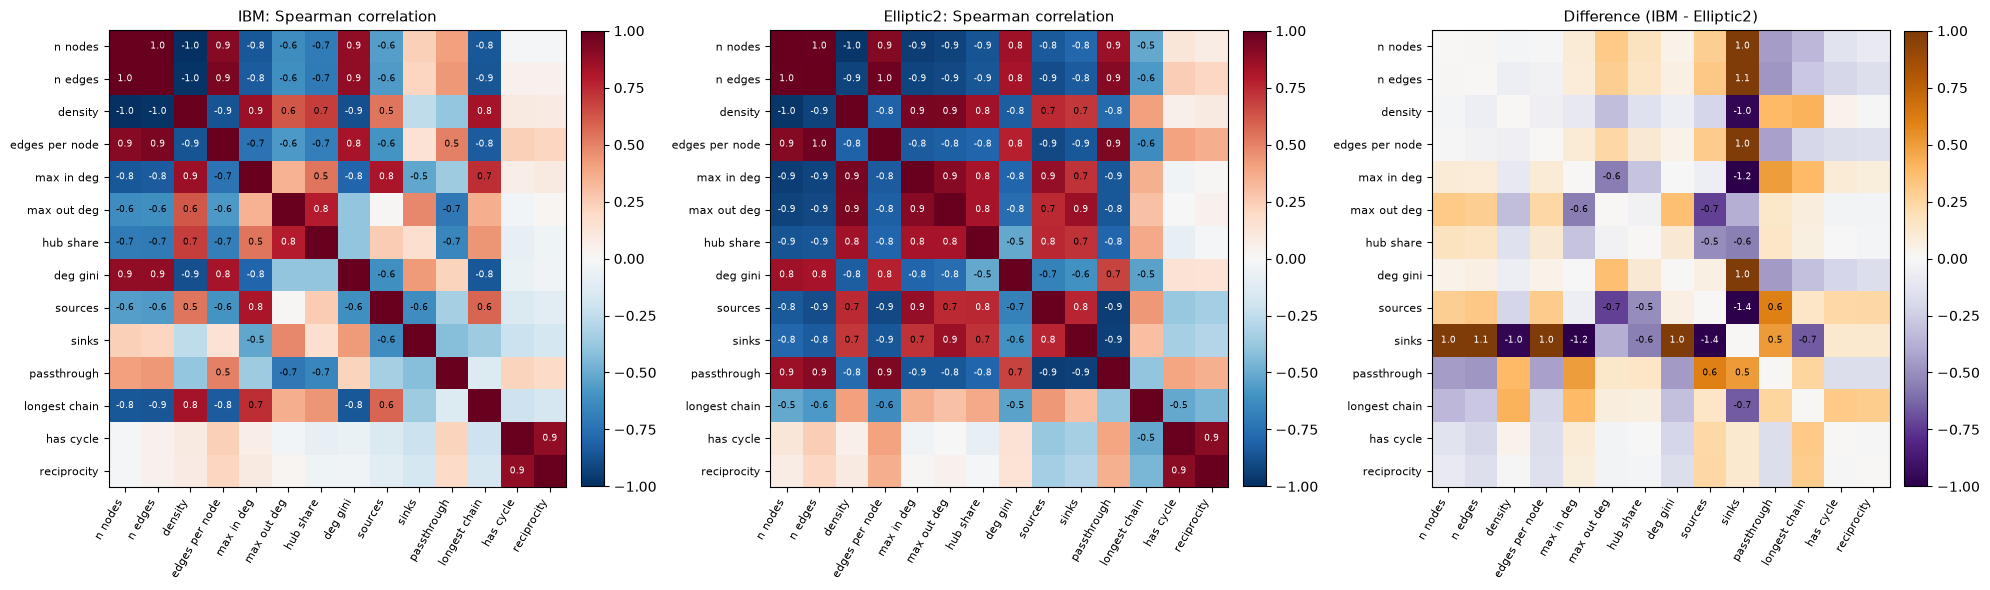

Highly correlated pairs (|rho| >= 0.85 in at least one dataset):


,feature_a,feature_b,rho_ibm,rho_elliptic2
0,n_nodes,n_edges,0.99,0.98
1,n_nodes,density,-0.99,-0.97
2,n_nodes,edges_per_node,0.91,0.92
3,n_nodes,max_in_deg_norm,-0.84,-0.94
4,n_nodes,max_out_deg_norm,-0.62,-0.93
5,n_nodes,hub_share,-0.70,-0.87
6,n_nodes,deg_gini,0.89,0.85
7,n_nodes,frac_passthrough,0.41,0.86
8,n_edges,density,-0.98,-0.92
9,n_edges,edges_per_node,0.94,0.97


correlation_structure_similarity_ibm_vs_elliptic2 0.816   <- 1 = features relate identically in both domains

Feature-label association (AUC: 0.5 = no signal, >0.5 higher in suspicious, <0.5 lower):


,feature,rho_label_IBM,auc_IBM,rho_label_Elliptic2,auc_Elliptic2,same_direction
9,frac_sinks,-0.209,0.220,-0.012,0.479,True
11,longest_chain_norm,-0.169,0.273,-0.003,0.496,True
12,has_cycle,0.424,0.647,-0.006,0.495,False
10,frac_passthrough,0.112,0.646,0.015,0.527,True
7,deg_gini,-0.098,0.368,0.011,0.519,False
3,edges_per_node,0.087,0.618,0.013,0.524,True
13,reciprocity,0.317,0.598,-0.006,0.496,False
8,frac_sources,-0.071,0.404,-0.016,0.471,True
4,max_in_deg_norm,0.054,0.573,-0.020,0.465,False
2,density,0.043,0.558,-0.018,0.468,False


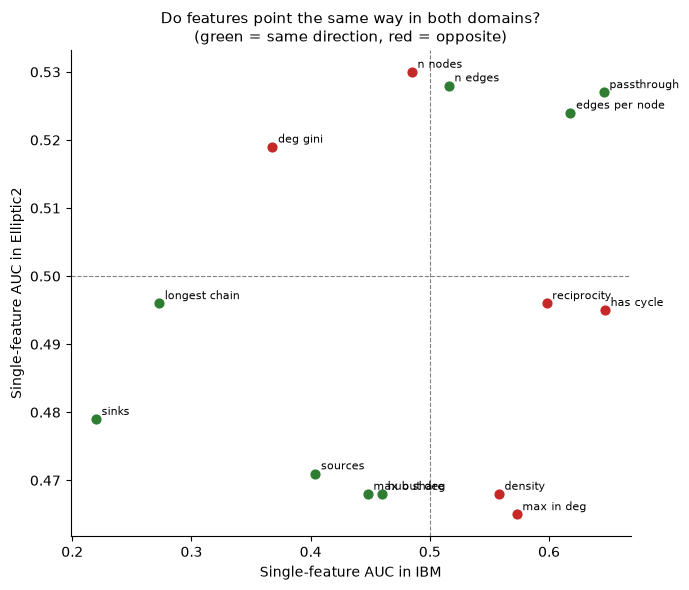

features_same_direction_in_both               8


In [14]:
# ============================================================
# Step 12 - Correlation analysis (exploratory)
# ============================================================
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

DATA = {"IBM": ibm_feat, "Elliptic2": ell_feat}
short = {f: f.replace("_norm", "").replace("max_", "max ").replace("frac_", "").replace("_", " ") for f in FEATURES}

# ---- 1. Feature-feature correlation, one heatmap per dataset + their difference
corr = {name: df[FEATURES].corr(method="spearman") for name, df in DATA.items()}
diff = corr["IBM"] - corr["Elliptic2"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (title, m, cmap) in zip(axes, [("IBM: Spearman correlation", corr["IBM"], "RdBu_r"),
                                       ("Elliptic2: Spearman correlation", corr["Elliptic2"], "RdBu_r"),
                                       ("Difference (IBM - Elliptic2)", diff, "PuOr_r")]):
    im = ax.imshow(m.values, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(FEATURES)), [short[f] for f in FEATURES], rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(FEATURES)), [short[f] for f in FEATURES], fontsize=8)
    ax.set_title(title, fontsize=11)
    for i in range(len(FEATURES)):
        for j in range(len(FEATURES)):
            v = m.values[i, j]
            if i != j and abs(v) >= 0.5:
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                        color="white" if abs(v) > 0.75 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
plt.tight_layout(); plt.savefig(OUT / "correlation_heatmaps.png", dpi=150); plt.show()

# ---- 2. Redundant feature pairs (|rho| >= 0.85 in either dataset)
pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        ri, re_ = corr["IBM"].loc[a, b], corr["Elliptic2"].loc[a, b]
        if max(abs(ri), abs(re_)) >= 0.85:
            pairs.append({"feature_a": a, "feature_b": b, "rho_ibm": round(ri, 2), "rho_elliptic2": round(re_, 2)})
redundant = pd.DataFrame(pairs)
print("Highly correlated pairs (|rho| >= 0.85 in at least one dataset):")
display(redundant if len(redundant) else "none")

# How similar is the overall correlation structure? (correlate the upper triangles)
iu = np.triu_indices(len(FEATURES), k=1)
a_, b_ = corr["IBM"].values[iu], corr["Elliptic2"].values[iu]
ok = np.isfinite(a_) & np.isfinite(b_)          # skip pairs involving a constant feature
struct_sim = spearmanr(a_[ok], b_[ok]).statistic
note("subgraphs", "correlation_structure_similarity_ibm_vs_elliptic2", round(float(struct_sim), 3),
     "1 = features relate identically in both domains")

# ---- 3. Feature-label association in each dataset
rows = []
for f in FEATURES:
    r = {"feature": f}
    for name, df in DATA.items():
        x, y = df[f], df["label"]
        r[f"rho_label_{name}"] = round(spearmanr(x, y).statistic, 3) if x.nunique() > 1 else 0.0
        r[f"auc_{name}"] = round(roc_auc_score(y, x), 3) if x.nunique() > 1 else 0.5
    r["same_direction"] = (r["auc_IBM"] - 0.5) * (r["auc_Elliptic2"] - 0.5) > 0
    rows.append(r)
label_assoc = pd.DataFrame(rows).sort_values("auc_IBM", key=lambda s: (s - 0.5).abs(), ascending=False)
label_assoc.to_csv(OUT / "feature_label_association.csv", index=False)
print("\nFeature-label association (AUC: 0.5 = no signal, >0.5 higher in suspicious, <0.5 lower):")
display(label_assoc)

fig, ax = plt.subplots(figsize=(7, 6))
ax.axhline(0.5, color="grey", lw=0.8, ls="--"); ax.axvline(0.5, color="grey", lw=0.8, ls="--")
for _, r in label_assoc.iterrows():
    c = "#2E7D32" if r.same_direction else "#C62828"
    ax.scatter(r.auc_IBM, r.auc_Elliptic2, color=c, s=40)
    ax.annotate(short[r.feature], (r.auc_IBM, r.auc_Elliptic2), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Single-feature AUC in IBM"); ax.set_ylabel("Single-feature AUC in Elliptic2")
ax.set_title("Do features point the same way in both domains?\n(green = same direction, red = opposite)", fontsize=11)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "feature_label_direction.png", dpi=150); plt.show()

note("subgraphs", "features_same_direction_in_both", int(label_assoc.same_direction.sum()))
json.dump(LOG, open(OUT / "prep_log.json", "w"), indent=2, default=str)

## 16. Construct temporal, stratified, and overlap-purged splits

**Description:** Define how training and test observations are separated and how an inner validation set is constructed to choose classification thresholds without consulting outer-test labels.

**Important code explained:**

1. `sets = pickle.load(fh)` reads the saved node and edge membership sets from Cell 13.
2. `DATA = {"ibm": ibm_feat, "elliptic2": ell_feat}` makes dataset selection convenient.
3. `purged_split(df, purge_sets, node_sets, temporal, seed, test_size=0.3)` makes the outer split.
4. For IBM, `df["t_start"].rank(method="first")` orders examples by start time; roughly the first 70% are training and the later 30% are candidate test observations. Ties are resolved in original row order.
5. For Elliptic2, `train_test_split(..., stratify=df.label, random_state=seed)` makes an approximately label-proportion-preserving random split.
6. `seen_items.update(...)` gathers transaction-row IDs (IBM) or cluster IDs (Elliptic2) already present in training.
7. `seen_items.isdisjoint(...)` checks that a held-out subgraph does **not** share those items with training; overlapping held-out graphs are **purged** (removed from evaluation).
8. The code separately reports the fraction of retained test graphs sharing **nodes** with training.
9. `validation_indices()` repeats an analogous overlap-aware split inside source training, reserving a validation set for threshold choice.

**Why this matters:** If the same original transaction or cluster appears in training and testing, the model evaluation may overstate performance.

**Important limitations:** For IBM, *transaction-disjoint* does not mean *account-disjoint*—accounts can recur with different transactions. The split does not guarantee independence among all retained examples. Because Elliptic2's supplied files lack comparable timing, the two datasets do not share an identical split protocol.

In [15]:
from sklearn.model_selection import train_test_split

with open(OUT / "subgraph_sets.pkl", "rb") as fh:
    sets = pickle.load(fh)
DATA = {"ibm": ibm_feat, "elliptic2": ell_feat}

def purged_split(df, purge_sets, node_sets, temporal, seed, test_size=0.3):
    """Hold out a fraction of subgraphs; purge holdout members that overlap train.

    IBM overlap is measured by transaction-row IDs; Elliptic2 overlap by cluster ID.
    IBM uses chronological order, Elliptic2 a stratified random split.
    """
    if temporal:
        r = df["t_start"].rank(method="first").to_numpy()
        cut = (1 - test_size) * len(df)
        tr, te = np.where(r <= cut)[0], np.where(r > cut)[0]
    else:
        tr, te = train_test_split(np.arange(len(df)), test_size=test_size,
                                  stratify=df.label, random_state=seed)

    seen_items, seen_nodes = set(), set()
    for sg in df.sg_id.iloc[tr]:
        seen_items.update(purge_sets[sg].tolist())
        seen_nodes.update(node_sets[sg].tolist())
    keep = np.asarray([seen_items.isdisjoint(purge_sets[sg].tolist())
                       for sg in df.sg_id.iloc[te]], dtype=bool)
    retained = te[keep]
    recurring = [not seen_nodes.isdisjoint(node_sets[sg].tolist())
                 for sg in df.sg_id.iloc[retained]]
    info = {"train": len(tr), "test_before": len(te),
            "purged": int((~keep).sum()), "test_final": len(retained),
            "test_positives": int(df.label.iloc[retained].sum()),
            "test_with_recurring_node": round(float(np.mean(recurring)), 3) if recurring else None}
    return tr, retained, info

def make_splits(seed):
    return {"ibm": purged_split(ibm_feat, sets["ibm_edges"], sets["ibm_nodes"], True, seed),
            "elliptic2": purged_split(ell_feat, sets["ell_nodes"], sets["ell_nodes"], False, seed)}

def validation_indices(ds, train_indices, seed, validation_fraction=0.2):
    """Construct a held-out inner validation split and purge overlaps with fitting rows.

    Crucially, neither the threshold nor model weights are fitted on outer test labels.
    """
    train_indices = np.asarray(train_indices)
    sub_df = DATA[ds].iloc[train_indices].reset_index(drop=True)
    overlap = sets["ibm_edges"] if ds == "ibm" else sets["ell_nodes"]
    nodes_for_overlap = sets["ibm_nodes"] if ds == "ibm" else sets["ell_nodes"]
    fit_local, val_local, info = purged_split(
        sub_df, overlap, nodes_for_overlap, temporal=(ds == "ibm"),
        seed=seed, test_size=validation_fraction)
    return train_indices[fit_local], train_indices[val_local], info

for ds, (tr, te, info) in make_splits(0).items():
    fit, val, inner_info = validation_indices(ds, tr, 0)
    print(f"{ds}: outer={info}; inner_validation={inner_info}")


ibm: outer={'train': 5439, 'test_before': 2331, 'purged': 645, 'test_final': 1686, 'test_positives': 84, 'test_with_recurring_node': 0.633}; inner_validation={'train': 4351, 'test_before': 1088, 'purged': 315, 'test_final': 773, 'test_positives': 30, 'test_with_recurring_node': 0.563}
elliptic2: outer={'train': 85267, 'test_before': 36543, 'purged': 0, 'test_final': 36543, 'test_positives': 829, 'test_with_recurring_node': 0.0}; inner_validation={'train': 68213, 'test_before': 17054, 'purged': 0, 'test_final': 17054, 'test_positives': 387, 'test_with_recurring_node': 0.0}


## 17. Train models, select thresholds, evaluate and save results

**Description:** This is the central experiment: train four classifiers, choose a decision threshold on *source validation data*, and test within the source dataset and across the other dataset.

**Four model configurations:**

- **`SizeOnly`**: Logistic Regression using only `n_nodes` and `n_edges`. This baseline tests whether apparent detection depends mainly on size.
- **`LogReg`**: Logistic Regression on all 14 features. It runs `log1p` then `StandardScaler` inside a scikit-learn pipeline.
- **`RandomForest`**: an ensemble of 400 decision trees (`min_samples_leaf=2`) with balanced bootstrap class weights.
- **`GradBoosting`**: histogram-based gradient boosting with up to 300 iterations and a learning rate of 0.05.

**Important code explained:**

- `make_pipeline(...)` packages preprocessing together with the estimator. Fitting a pipeline on training observations estimates the scaler only from those observations.
- `model.fit(X_fit, y_fit)` learns model parameters.
- `model.predict_proba(X_val)[:, 1]` extracts the predicted probability assigned to class `1`.
- `precision_recall_curve(y_val, p_val)` calculates precision and recall at candidate thresholds.
- `best_thr(y_val, p_val)` selects the validation threshold maximizing F1. **It does not use test labels.**
- `yh = (p >= thr).astype(int)` turns test probabilities into test predictions with the fixed validation threshold.
- `average_precision_score(y, p)` calculates **average precision (AP)**, written as `pr_auc` in this notebook. It is a ranking metric often described loosely as PR-AUC, but it is not exactly trapezoidal area under the precision-recall curve.
- `lift = AP / prevalence` compares AP to the positive rate in that particular test set. A random ranking has expected AP near that rate; lift near `1` indicates little improvement over random ranking.
- `roc_auc_score()` measures ranking across positive-negative pairs. `precision`, `recall` and `f1` describe thresholded predictions.
- `run(seed, size_restricted=False, max_nodes=10)` evaluates both all graphs and, when restricted, only graphs with **at most 10 nodes**. This is a **size restriction, not full distribution matching**.
- `SEEDS = [0, 1, 2]` repeats the experiment with three seed settings; the same underlying IBM time-ordered split is not three independent time periods.
- The results are written to `results_raw.csv` and `results_summary.csv` with mean and standard deviation summaries.

**Metric mini-example:** Suppose a held-out test set has 2 positives among 100 observations (prevalence 0.02), and AP is 0.10. Then `lift = 0.10 / 0.02 = 5`. This is a fivefold improvement relative to the AP baseline **in that sampled test set**, not a fivefold increase in detection effectiveness in a real deployment.

**Critical limitations:** A threshold selected for one domain may not transfer well to a domain with different prevalence. The models are *not guaranteed calibrated*. Results must be rerun after notebook revisions; cleared outputs are not evidence of a successful full experiment.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score)

SIZE_COLS = ["n_nodes", "n_edges"]
def models(seed):
    return {
        "SizeOnly":     ("size", make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                               LogisticRegression(max_iter=2000, class_weight="balanced"))),
        "LogReg":       ("all",  make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                                               LogisticRegression(max_iter=2000, class_weight="balanced"))),
        "RandomForest": ("all",  RandomForestClassifier(400, min_samples_leaf=2, class_weight="balanced_subsample",
                                                        n_jobs=-1, random_state=seed)),
        "GradBoosting": ("all",  HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                                class_weight="balanced", random_state=seed)),
    }

def best_thr(y, p):
    """Choose F1-maximizing threshold from validation data ONLY."""
    pr, rc, th = precision_recall_curve(y, p)
    f = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[np.nanargmax(f[:-1])]) if len(th) else 0.5

def score(y, p, thr):
    """Evaluate once using a threshold selected on independent source validation."""
    y = np.asarray(y)
    p = np.asarray(p)
    if len(y) == 0 or np.unique(y).size != 2:
        raise ValueError("Evaluation requires both positive and negative test labels.")
    yh = (p >= thr).astype(int)
    prev = float(y.mean())
    ap = float(average_precision_score(y, p))
    return {"prevalence": prev, "pr_auc": ap, "lift": ap / prev,
            "roc_auc": float(roc_auc_score(y, p)),
            "precision": float(precision_score(y, yh, zero_division=0)),
            "recall": float(recall_score(y, yh, zero_division=0)),
            "f1": float(f1_score(y, yh, zero_division=0))}

def run(seed, size_restricted=False, max_nodes=10):
    """Run within-domain and cross-domain testing for each model.

    size_restricted=True means keeping graphs <= max_nodes; it does NOT match
    the graph-size distributions across datasets.
    """
    res, splits = [], make_splits(seed)
    if size_restricted:
        splits = {ds: (tr[DATA[ds].n_nodes.iloc[tr].to_numpy() <= max_nodes],
                       te[DATA[ds].n_nodes.iloc[te].to_numpy() <= max_nodes], info)
                  for ds, (tr, te, info) in splits.items()}
    for src in DATA:
        tr = splits[src][0]
        fit_ids, val_ids, vinfo = validation_indices(src, tr, seed)
        if vinfo["purged"]:
            print(f"  {src}, seed {seed}, size_restricted={size_restricted}: "
                  f"purged {vinfo['purged']} overlapping validation subgraphs")
        y_fit = DATA[src].label.iloc[fit_ids]
        y_val = DATA[src].label.iloc[val_ids]
        if y_fit.nunique() < 2 or y_val.nunique() < 2:
            raise ValueError(f"{src}: inner fit/validation lacks both classes after purging. "
                             "Adjust the split or inspect dataset construction.")
        for name, (cols, model) in models(seed).items():
            feats = SIZE_COLS if cols == "size" else FEATURES
            model.fit(DATA[src][feats].iloc[fit_ids], y_fit)
            p_val = model.predict_proba(DATA[src][feats].iloc[val_ids])[:, 1]
            thr = best_thr(y_val.to_numpy(), p_val)  # source validation only
            for tgt in DATA:
                te = splits[tgt][1]
                yt = DATA[tgt].label.iloc[te].to_numpy()
                if len(yt) == 0 or len(np.unique(yt)) < 2:
                    print(f"WARNING: {src} -> {tgt} test fold lacks both classes; skipping")
                    continue
                p = model.predict_proba(DATA[tgt][feats].iloc[te])[:, 1]
                res.append({"seed": seed, "size_restricted": size_restricted,
                            "train_on": src, "test_on": tgt,
                            "setting": "within" if src == tgt else (
                                "synthetic->real" if src == "ibm" else "real->synthetic"),
                            "model": name, "n_fit": len(fit_ids), "n_validation": len(val_ids),
                            "n_test": len(yt), "validation_threshold": thr,
                            **score(yt, p, thr)})
    return res

SEEDS = [0, 1, 2]
results = []
for s in SEEDS:
    for restricted in (False, True):
        t0 = time.time()
        results += run(s, size_restricted=restricted)
        print(f"seed {s}, size_restricted={restricted}: {time.time()-t0:.0f}s", flush=True)
results = pd.DataFrame(results)
if results.empty:
    raise RuntimeError("No valid evaluation folds were produced.")
results.to_csv(OUT / "results_raw.csv", index=False)
summary = (results.groupby(["size_restricted", "train_on", "test_on", "model"])
           [["prevalence", "pr_auc", "lift", "roc_auc", "precision", "recall", "f1"]]
           .agg(["mean", "std"]).round(3))
summary.to_csv(OUT / "results_summary.csv")
display(results.groupby(["size_restricted", "train_on", "test_on", "model"])
        [["prevalence", "pr_auc", "lift", "f1"]].mean().round(3))


  ibm, seed 0, size_restricted=False: purged 315 overlapping validation subgraphs
seed 0, size_restricted=False: 7s
  ibm, seed 0, size_restricted=True: purged 24 overlapping validation subgraphs
seed 0, size_restricted=True: 7s
  ibm, seed 1, size_restricted=False: purged 315 overlapping validation subgraphs
seed 1, size_restricted=False: 8s
  ibm, seed 1, size_restricted=True: purged 24 overlapping validation subgraphs
seed 1, size_restricted=True: 8s
  ibm, seed 2, size_restricted=False: purged 315 overlapping validation subgraphs
seed 2, size_restricted=False: 11s
  ibm, seed 2, size_restricted=True: purged 24 overlapping validation subgraphs
seed 2, size_restricted=True: 7s


prevalence  pr_auc    lift  \
size_restricted train_on  test_on   model                                      
False           elliptic2 elliptic2 GradBoosting       0.023   0.025   1.111   
                                    LogReg             0.023   0.025   1.121   
                                    RandomForest       0.023   0.024   1.059   
                                    SizeOnly           0.023   0.024   1.060   
                          ibm       GradBoosting       0.050   0.045   0.894   
                                    LogReg             0.050   0.083   1.675   
                                    RandomForest       0.050   0.047   0.941   
                                    SizeOnly           0.050   0.088   1.759   
                ibm       elliptic2 GradBoosting       0.023   0.022   0.991   
                                    LogReg             0.023   0.022   0.987   
                                    RandomForest       0.023   0.023   0.998   
                                    SizeOnly           0.023   0.023   1.022   
                          ibm       GradBoosting       0.050   0.613  12.312   
                                    LogReg             0.050   0.562  11.282   
                                    RandomForest       0.050   0.579  11.619   
                                    SizeOnly           0.050   0.253   5.070   
True            elliptic2 elliptic2 GradBoosting       0.023   0.025   1.087   
                                    LogReg             0.023   0.025   1.109   
                                    RandomForest       0.023   0.024   1.059   
                                    SizeOnly           0.023   0.024   1.071   
                          ibm       GradBoosting       0.043   0.048   1.111   
                                    LogReg             0.043   0.033   0.764   
                                    RandomForest       0.043   0.043   0.995   
                                    SizeOnly           0.043   0.037   0.863   
                ibm       elliptic2 GradBoosting       0.023   0.022   0.989   
                                    LogReg             0.023   0.023   1.006   
                                    RandomForest       0.023   0.023   1.001   
                                    SizeOnly           0.023   0.023   1.033   
                          ibm       GradBoosting       0.043   0.516  11.917   
                                    LogReg             0.043   0.514  11.883   
                                    RandomForest       0.043   0.499  11.535   
                                    SizeOnly           0.043   0.326   7.530   

                                                     f1  
size_restricted train_on  test_on   model                
False           elliptic2 elliptic2 GradBoosting  0.049  
                                    LogReg        0.050  
                                    RandomForest  0.046  
                                    SizeOnly      0.047  
                          ibm       GradBoosting  0.048  
                                    LogReg        0.055  
                                    RandomForest  0.012  
                                    SizeOnly      0.094  
                ibm       elliptic2 GradBoosting  0.024  
                                    LogReg        0.031  
                                    RandomForest  0.040  
                                    SizeOnly      0.033  
                          ibm       GradBoosting  0.600  
                                    LogReg        0.486  
                                    RandomForest  0.573  
                                    SizeOnly      0.365  
True            elliptic2 elliptic2 GradBoosting  0.049  
                                    LogReg        0.050  
                                    RandomForest  0.048  
                                    SizeOnly      0.049  
                          ibm       GradBoosting  0.0

## 18. Visualize performance across the four transfer directions

**Description:** Create bar charts comparing models' average-precision lift for all four train → test settings, separately for unrestricted and size-restricted test regimes.

**Important code explained:**

- `order = [...]` fixes the four comparisons: IBM → IBM, Elliptic2 → Elliptic2, IBM → Elliptic2, and Elliptic2 → IBM.
- `mnames = list(models(0))` gets the four model names.
- `plt.subplots(1, 2, ..., sharey=True)` creates two side-by-side panels with the same y-axis.
- `.groupby(["train_on", "test_on", "model"])["lift"].agg(["mean", "std"])` aggregates performance across seeds.
- `ax.bar(..., yerr=errs)` draws the bars with standard-deviation error bars.
- `ax.axhline(1, ...)` adds the lift = 1 reference, approximately the random-ranking baseline.
- The left panel uses all subgraphs, while the right panel uses only those with `n_nodes <= 10`.
- `plt.savefig(...)` writes `results_lift.png` to the output directory.

**How to read it:** Within-dataset bars assess performance on held-out examples from the source domain. Cross-dataset bars assess whether that source-trained ranking transfers to the different target domain.

**Caution:** Error bars across three seeds do not capture all sources of uncertainty, and the size-restricted panel is **not** a true distribution-matched experiment.

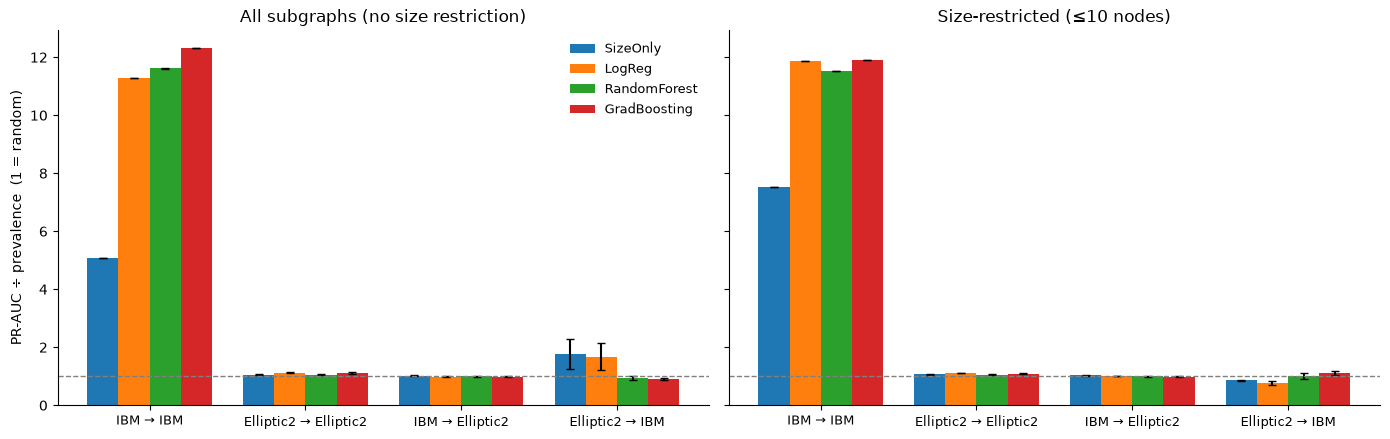

In [17]:
order = [("ibm", "ibm", "IBM → IBM"), ("elliptic2", "elliptic2", "Elliptic2 → Elliptic2"),
         ("ibm", "elliptic2", "IBM → Elliptic2"), ("elliptic2", "ibm", "Elliptic2 → IBM")]
mnames = list(models(0))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, sm in zip(axes, (False, True)):
    agg = results[results.size_restricted == sm].groupby(["train_on", "test_on", "model"])["lift"].agg(["mean", "std"])
    w = 0.8 / len(mnames)
    for j, m in enumerate(mnames):
        vals = [agg.loc[(s, t, m), "mean"] if (s, t, m) in agg.index else np.nan for s, t, _ in order]
        errs = [agg.loc[(s, t, m), "std"] if (s, t, m) in agg.index else 0 for s, t, _ in order]
        ax.bar(np.arange(4) + j*w - 0.4 + w/2, vals, w, yerr=errs, capsize=3, label=m)
    ax.axhline(1, color="grey", ls="--", lw=1)
    ax.set_xticks(range(4), [o[2] for o in order], fontsize=9)
    ax.set_title("Size-restricted (≤10 nodes)" if sm else "All subgraphs (no size restriction)")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylabel("PR-AUC ÷ prevalence  (1 = random)")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "results_lift.png", dpi=160); plt.show()


## Exploratory Data Analysis 1 — Transaction-level overview (raw IBM data)

## 20. Transaction-level EDA: trends, formats, amounts, and account activity

**Description:** Produce four visualizations of **raw IBM transactions** and summarize payment-format rates and concentration of account activity.

**Panel (a) — Daily transaction volume:**

- `ibm.set_index("timestamp").resample("D")["is_laundering"].agg(["size", "sum"])` groups transactions by calendar day.
- `size` counts all transactions; `sum` counts transactions labeled laundering.
- Two y-axes display overall volume and positive transaction counts. They have different scales, so avoid visually equating their heights.

**Panel (b) — Payment format:**

- `groupby("payment_format")["is_laundering"].agg(["mean", "size"])` computes the transaction-level fraction labeled laundering per format.
- A horizontal line marks the overall transaction-level rate.

**Panel (c) — Amounts:**

- Select transactions with `payment_currency == "US Dollar"`.
- `np.logspace(-2, 8, 60)` creates logarithmically spaced histogram bins.
- `ax.set_xscale("log")` shows orders of magnitude clearly; `density=True` normalizes each histogram.
- These amounts are used for **EDA**, not for model training.

**Panel (d) — Account activity:**

- Source and destination IDs are concatenated to count how often accounts appear as endpoints.
- `ax.loglog(...)` draws the frequency distribution on log-log axes. This is transaction-endpoint activity, not exactly the unique-neighbor degree used by `DiGraph`.

**Caution:** Raw rates are descriptive rather than causal. Currency, account activity, and transaction amount distributions can differ for many legitimate reasons.

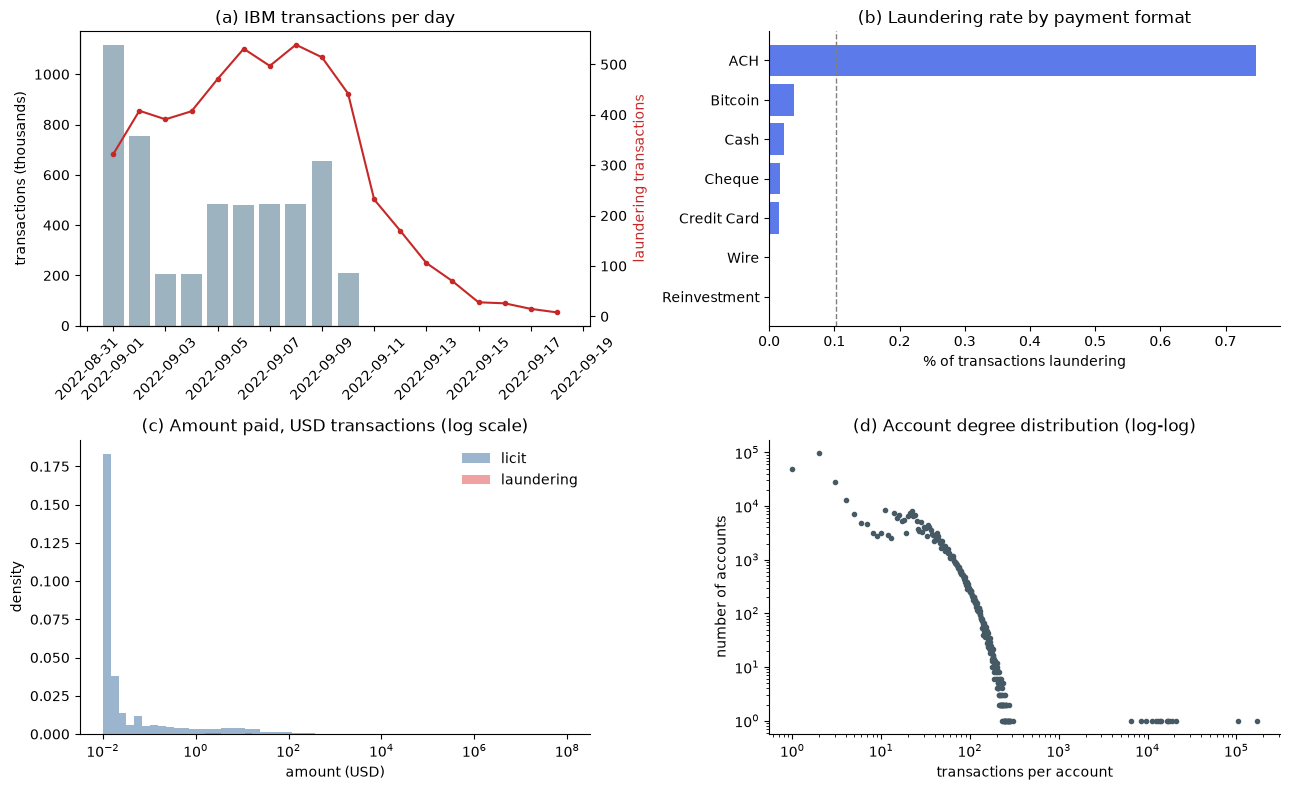

Laundering rate by payment format (%):


,size,rate_pct
payment_format,,
ACH,600797,0.746
Bitcoin,146091,0.038
Cash,490891,0.022
Cheque,1864331,0.017
Credit Card,1323324,0.016
Reinvestment,481056,0.000
Wire,171855,0.000


Account degree: median 10 | mean 21.2 | max 169756 | top 1% of accounts hold 11.8% of edges


In [18]:
from scipy.stats import mannwhitneyu, skew

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# (a) transactions and laundering per day
daily = ibm.set_index("timestamp").resample("D")["is_laundering"].agg(["size", "sum"])
ax = axes[0, 0]
ax.bar(daily.index, daily["size"] / 1e3, color="#9DB4C0")
ax2 = ax.twinx()
ax2.plot(daily.index, daily["sum"], color="#C62828", marker="o", ms=3)
ax.set_title("(a) IBM transactions per day"); ax.set_ylabel("transactions (thousands)")
ax2.set_ylabel("laundering transactions", color="#C62828")
ax.tick_params(axis="x", rotation=45)

# (b) laundering rate by payment format
fmt = ibm.groupby("payment_format")["is_laundering"].agg(["mean", "size"]).sort_values("mean")
ax = axes[0, 1]
ax.barh(fmt.index, fmt["mean"] * 100, color="#5C7AEA")
ax.axvline(ibm.is_laundering.mean() * 100, color="grey", ls="--", lw=1)
ax.set_title("(b) Laundering rate by payment format"); ax.set_xlabel("% of transactions laundering")

# (c) amount distribution, licit vs laundering (USD only, log scale)
usd = ibm[ibm.payment_currency == "US Dollar"]
ax = axes[1, 0]
bins = np.logspace(-2, 8, 60)
for lab, c, name in [(0, "#4C78A8", "licit"), (1, "#E45756", "laundering")]:
    ax.hist(usd.loc[usd.is_laundering == lab, "amount_paid"].clip(lower=0.01), bins=bins,
            density=True, alpha=0.55, color=c, label=name)
ax.set_xscale("log"); ax.set_title("(c) Amount paid, USD transactions (log scale)")
ax.set_xlabel("amount (USD)"); ax.set_ylabel("density"); ax.legend(frameon=False)

# (d) account degree distribution (log-log)
deg = pd.concat([ibm.loc[ibm.s != ibm.d, "s"], ibm.loc[ibm.s != ibm.d, "d"]]).value_counts()
cnt = deg.value_counts().sort_index()
ax = axes[1, 1]
ax.loglog(cnt.index, cnt.values, ".", color="#455A64")
ax.set_title("(d) Account degree distribution (log-log)")
ax.set_xlabel("transactions per account"); ax.set_ylabel("number of accounts")

for a in axes.flat:
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "eda_ibm_transactions.png", dpi=150); plt.show()

print("Laundering rate by payment format (%):")
display(fmt.assign(rate_pct=fmt["mean"] * 100)[["size", "rate_pct"]].sort_values("rate_pct", ascending=False).round(3))
print("Account degree: median", int(deg.median()), "| mean", round(deg.mean(), 1), "| max", int(deg.max()),
      "| top 1% of accounts hold",
      f"{deg.sort_values(ascending=False).head(max(1, len(deg)//100)).sum() / deg.sum():.1%} of edges")

## 21. Descriptive statistics and two-class comparisons

**Description:** Describe all 14 graph features separately for suspicious and licit subgraphs in each dataset, then test whether their distributions differ.

**Important code explained:**

- `describe(df, name)` loops through labels `0` and `1`, then each feature in `FEATURES`.
- `x.quantile(.25)` and `x.quantile(.75)` compute the first and third quartiles, **Q1** and **Q3**.
- It records sample size, mean, median, standard deviation, minimum, Q1, Q3, maximum, and skewness.
- `pd.pivot_table(...)` rearranges the statistics into a readable table comparing dataset/class combinations.
- `mannwhitneyu(a, b, alternative="two-sided")` is a nonparametric test comparing ranked values from the suspicious and licit groups.
- `r = 2*u/(len(a)*len(b)) - 1` calculates the **rank-biserial effect size**; positive/negative signs here reflect the direction implied by the sample order.
- `significant_0.001` marks comparisons where raw `p < 0.001`.

**Example:** A higher median `max_in_deg_norm` among positive subgraphs would indicate that positive examples tend to have more concentrated incoming connections. It would **not** prove that concentration causes laundering.

**Caution:** Many tests are performed (14 features across two datasets). The code does **not** apply a multiple-comparison correction, and graphs may not be independent due to shared network structure. Small p-values do not imply practical importance.

In [19]:
def describe(df, name):
    rows = []
    for lab in (0, 1):
        x = df.loc[df.label == lab, FEATURES]
        q1, q3 = x.quantile(.25), x.quantile(.75)
        for f in FEATURES:
            rows.append({"dataset": name, "class": "suspicious" if lab else "licit", "feature": f,
                         "n": len(x), "mean": x[f].mean(), "median": x[f].median(), "std": x[f].std(),
                         "min": x[f].min(), "q1": q1[f], "q3": q3[f], "max": x[f].max(),
                         "skew": skew(x[f]) if x[f].nunique() > 1 else 0.0})
    return rows

desc = pd.DataFrame(describe(ibm_feat, "IBM") + describe(ell_feat, "Elliptic2")).round(3)
desc.to_csv(OUT / "eda_descriptive_statistics.csv", index=False)

compact = desc.assign(cell=lambda d: d["mean"].map("{:.3f}".format) + " (" + d["median"].map("{:.3f}".format)
                      + ") [" + d["std"].map("{:.3f}".format) + "]")
compact = compact.pivot_table(index="feature", columns=["dataset", "class"], values="cell", aggfunc="first").reindex(FEATURES)
print("Mean (median) [std] by dataset and class:")
display(compact)

# Do the classes differ? Mann-Whitney U test + rank-biserial effect size
tests = []
for name, df in [("IBM", ibm_feat), ("Elliptic2", ell_feat)]:
    for f in FEATURES:
        a, b = df.loc[df.label == 1, f], df.loc[df.label == 0, f]
        if a.nunique() + b.nunique() > 2:
            u, p = mannwhitneyu(a, b, alternative="two-sided")
            r = 2 * u / (len(a) * len(b)) - 1          # -1..1, 0 = no difference
        else:
            p, r = 1.0, 0.0
        tests.append({"dataset": name, "feature": f, "rank_biserial_r": round(r, 3), "p_value": p})
tests = pd.DataFrame(tests)
tests["significant_0.001"] = tests.p_value < 0.001
tests.to_csv(OUT / "eda_class_differences.csv", index=False)
print("\nEffect size, suspicious vs licit (rank-biserial r: >0 higher in suspicious; |r|>0.3 moderate, >0.5 large):")
display(tests.pivot(index="feature", columns="dataset", values="rank_biserial_r").reindex(FEATURES))

Mean (median) [std] by dataset and class:


dataset                         Elliptic2                         \
class                               licit             suspicious   
feature                                                            
n_nodes             3.646 (3.000) [3.254]  3.788 (3.000) [2.581]   
n_edges             2.815 (2.000) [3.850]  2.911 (2.000) [2.829]   
density             0.379 (0.500) [0.164]  0.361 (0.333) [0.166]   
edges_per_node      0.666 (0.667) [0.196]  0.677 (0.667) [0.185]   
max_in_deg_norm     0.694 (1.000) [0.337]  0.650 (0.500) [0.346]   
max_out_deg_norm    0.706 (1.000) [0.329]  0.667 (0.667) [0.336]   
hub_share           0.420 (0.500) [0.123]  0.405 (0.500) [0.129]   
deg_gini            0.087 (0.000) [0.093]  0.093 (0.133) [0.091]   
frac_sources        0.368 (0.500) [0.161]  0.352 (0.333) [0.158]   
frac_sinks          0.382 (0.500) [0.150]  0.372 (0.400) [0.149]   
frac_passthrough    0.250 (0.000) [0.289]  0.276 (0.333) [0.287]   
longest_chain_norm  0.892 (1.000) [0.230]  0.895 (1.000) [0.216]   
has_cycle           0.056 (0.000) [0.229]  0.046 (0.000) [0.210]   
reciprocity         0.029 (0.000) [0.151]  0.025 (0.000) [0.139]   

dataset                                IBM                         
class                                licit             suspicious  
feature                                                            
n_nodes             10.060 (8.000) [8.380]  9.719 (8.000) [8.409]  
n_edges              9.236 (7.000) [8.662]  9.151 (7.500) [7.920]  
density              0.213 (0.125) [0.174]  0.325 (0.143) [0.328]  
edges_per_node       0.799 (0.889) [0.190]  0.971 (0.929) [0.458]  
max_in_deg_norm      0.441 (0.300) [0.353]  0.594 (0.655) [0.400]  
max_out_deg_norm     0.657 (0.663) [0.309]  0.599 (0.750) [0.403]  
hub_share            0.385 (0.500) [0.134]  0.351 (0.500) [0.173]  
deg_gini             0.256 (0.311) [0.156]  0.162 (0.099) [0.175]  
frac_sources         0.326 (0.333) [0.177]  0.279 (0.200) [0.275]  
frac_sinks           0.550 (0.500) [0.188]  0.283 (0.218) [0.278]  
frac_passthrough     0.124 (0.100) [0.129]  0.437 (0.333) [0.439]  
longest_chain_norm   0.469 (0.333) [0.345]  0.288 (0.100) [0.381]  
has_cycle            0.008 (0.000) [0.091]  0.303 (0.000) [0.460]  
reciprocity          0.001 (0.000) [0.018]  0.177 (0.000) [0.368]


Effect size, suspicious vs licit (rank-biserial r: >0 higher in suspicious; |r|>0.3 moderate, >0.5 large):


dataset,Elliptic2,IBM
feature,,
n_nodes,0.059,-0.031
n_edges,0.056,0.032
density,-0.064,0.116
edges_per_node,0.048,0.235
max_in_deg_norm,-0.070,0.146
max_out_deg_norm,-0.063,-0.104
hub_share,-0.063,-0.080
deg_gini,0.038,-0.264
frac_sources,-0.059,-0.192


## 22. Compare all graph-feature distributions with boxplots

**Description:** Draw one panel per graph feature, showing licit and suspicious subgraphs in IBM and Elliptic2 side by side.

**Important code explained:**

- `n = len(FEATURES)` counts how many plots are needed (14).
- `cols = 4` creates a four-column layout; `np.ceil(n / cols)` determines the necessary number of rows.
- `axes.flat` lets a nested grid of matplotlib axes be iterated like a one-dimensional sequence.
- The nested loops filter the dataset and label combination and collect a feature's values.
- For `n_nodes` and `n_edges`, `np.log1p(v)` compresses the size range so variation is easier to see.
- `ax.boxplot(...)` displays the median and quartiles; with the usual setting, whiskers extend to the most extreme points within 1.5 IQR of the quartiles.
- `showfliers=False` hides outlier markers **without removing data from the calculation**.
- Extra grid panels are turned off and the figure is saved as `eda_feature_boxplots.png`.

**How to interpret:** Compare (1) licit vs suspicious *within each dataset*, and (2) IBM vs Elliptic2 *for the same feature*. If two domains have very different feature ranges, a classifier may struggle to transfer.

**Caution:** Visual differences do not by themselves establish predictive relevance; some features may largely reflect differences in candidate generation or graph size.

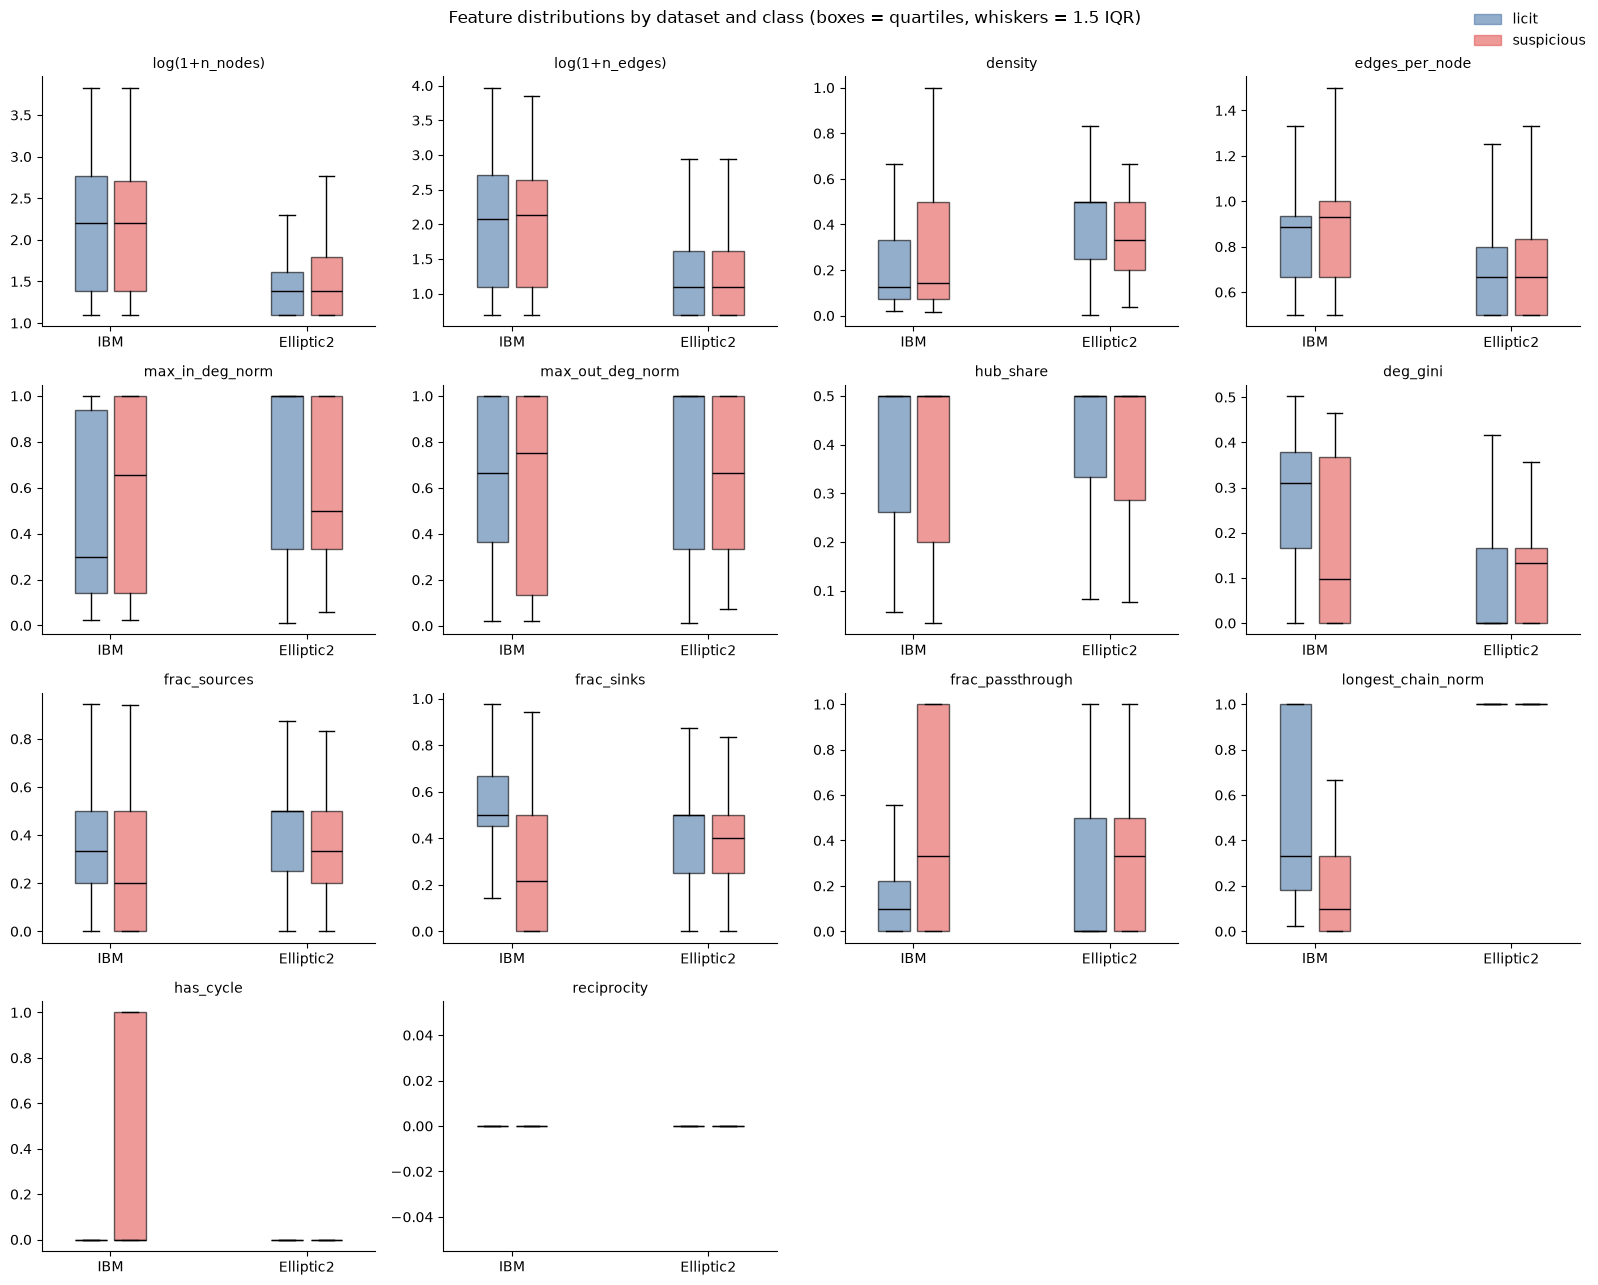

In [20]:
n = len(FEATURES); cols = 4; rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(16, 3.2 * rows_))
pos = {("IBM", 0): 0.8, ("IBM", 1): 1.2, ("Elliptic2", 0): 2.8, ("Elliptic2", 1): 3.2}
for ax, f in zip(axes.flat, FEATURES):
    for name, df in [("IBM", ibm_feat), ("Elliptic2", ell_feat)]:
        for lab, c in [(0, "#4C78A8"), (1, "#E45756")]:
            v = df.loc[df.label == lab, f].to_numpy()
            if f in ("n_nodes", "n_edges"):
                v = np.log1p(v)
            ax.boxplot(v, positions=[pos[(name, lab)]], widths=0.32, patch_artist=True, showfliers=False,
                       boxprops=dict(facecolor=c, alpha=0.6), medianprops=dict(color="black"))
    ax.set_xticks([1, 3], ["IBM", "Elliptic2"])
    ax.set_title(f"log(1+{f})" if f in ("n_nodes", "n_edges") else f, fontsize=10)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in ("#4C78A8", "#E45756")]
fig.legend(handles, ["licit", "suspicious"], loc="upper right", frameon=False)
fig.suptitle("Feature distributions by dataset and class (boxes = quartiles, whiskers = 1.5 IQR)", y=1.0)
plt.tight_layout(); plt.savefig(OUT / "eda_feature_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

## 23. Compare IBM laundering-pattern typologies

**Description:** Group IBM's documented positive examples by their laundering-pattern names and compare typical structural signatures; include the sampled licit negatives as a reference row.

**Important code explained:**

- `pos_feat = ibm_feat[ibm_feat.label == 1]` selects only positive subgraphs.
- `show = [...]` selects eight structural features for a more focused typology comparison.
- `pos_feat.groupby("pattern")[show].median()` computes median feature values for each documented pattern.
- `by_pattern.loc["(licit negatives)"] = ...` adds the negative-sample reference medians.
- `counts = pos_feat.groupby("pattern").size()` counts observations of each typology.
- The min-max expression rescales each column separately to the range 0–1 for **heatmap coloring**. It does *not* change the original feature values printed inside the cells.
- `ax.imshow(norm.values, cmap="viridis", ...)` creates the heatmap and `ax.text(...)` writes numerical median values into each cell.

**How to interpret:** This figure asks whether, for example, cycle-related laundering templates have different median reciprocity or longest-chain values from fan-in or fan-out templates.

**Caution:** These classes are generated from synthetic templates. Typology differences may reflect simulator rules and should not be treated as verified real-world AML signatures. Color intensity is scaled per feature, so raw colors are not directly comparable across columns.

Median feature value per laundering typology (IBM):


,n_nodes,density,max_in_deg_norm,max_out_deg_norm,frac_passthrough,longest_chain_norm,has_cycle,reciprocity,count
pattern,,,,,,,,,
BIPARTITE,8.0,0.071,0.143,0.143,0.000,0.143,0.0,0.0,49
CYCLE,4.0,0.333,0.333,0.333,1.000,0.000,1.0,0.0,54
FAN-IN,9.0,0.111,1.000,0.125,0.000,0.100,0.0,0.0,40
FAN-OUT,8.0,0.125,0.155,1.000,0.000,0.143,0.0,0.0,48
GATHER-SCATTER,15.0,0.071,0.636,0.556,0.056,0.091,0.0,0.0,51
RANDOM,4.0,0.250,0.333,0.333,0.667,1.000,0.0,0.0,41
SCATTER-GATHER,9.0,0.194,0.929,0.929,0.867,0.143,0.0,0.0,44
STACK,15.0,0.048,0.091,0.091,0.333,0.069,0.0,0.0,43
(licit negatives),8.0,0.125,0.300,0.663,0.100,0.333,0.0,0.0,7400


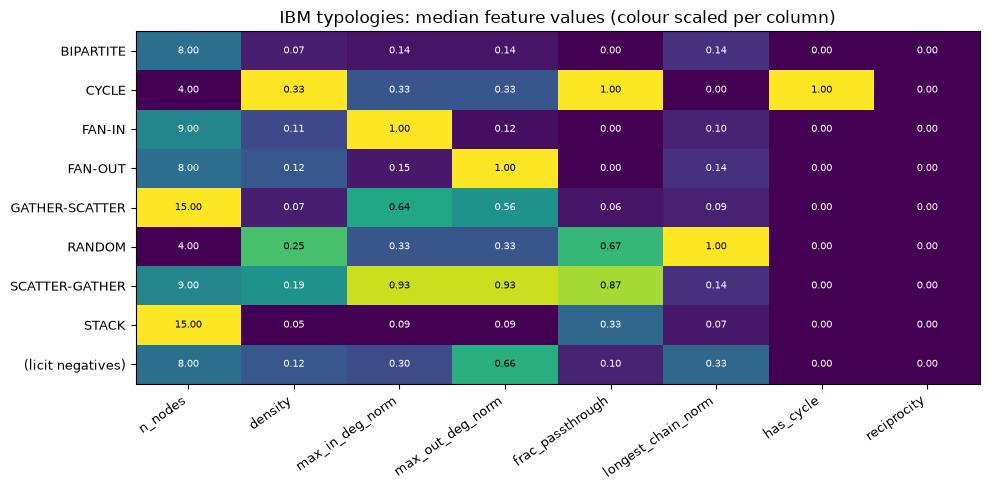

In [21]:
pos_feat = ibm_feat[ibm_feat.label == 1]
show = ["n_nodes", "density", "max_in_deg_norm", "max_out_deg_norm", "frac_passthrough",
        "longest_chain_norm", "has_cycle", "reciprocity"]
by_pattern = pos_feat.groupby("pattern")[show].median()
by_pattern.loc["(licit negatives)"] = ibm_feat.loc[ibm_feat.label == 0, show].median()
counts = pos_feat.groupby("pattern").size()
by_pattern["count"] = [counts.get(i, (ibm_feat.label == 0).sum()) for i in by_pattern.index]
print("Median feature value per laundering typology (IBM):")
display(by_pattern.round(3))

norm = (by_pattern[show] - by_pattern[show].min()) / (by_pattern[show].max() - by_pattern[show].min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(norm.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(show)), show, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(len(norm)), norm.index, fontsize=9)
for i in range(norm.shape[0]):
    for j in range(norm.shape[1]):
        ax.text(j, i, f"{by_pattern[show].values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if norm.values[i, j] < 0.6 else "black")
ax.set_title("IBM typologies: median feature values (colour scaled per column)")
plt.tight_layout(); plt.savefig(OUT / "eda_ibm_typologies.png", dpi=150); plt.show()

## 24. Limitations and proposed follow-up experiments

**Description:** This final Markdown cell documents what the project cannot yet establish and identifies improvements that would make the findings more credible.

**The seven limitations in the original notebook, in plain English:**

1. **Sampling bias:** Positive examples come from documented patterns; negatives come from BFS. The construction process itself can create differences.
2. **Residual account overlap:** IBM removes shared *transaction IDs* across the relevant split, not all shared account IDs. This is not a guarantee of entirely unseen accounts.
3. **Different datasets:** IBM account graphs and Elliptic2 cluster graphs may represent very different phenomena, so transfer failure needs careful interpretation.
4. **Time and seeds:** IBM uses a time-ordered split; Elliptic2 uses a stratified random one. Three random seeds are not three separate time periods.
5. **EDA touching labels:** Exploratory plots use full-dataset labels. Do not select the final model or features based on test labels and then claim the test remained untouched.
6. **Artificial prevalence:** IBM's positive frequency reflects sampled candidate graphs, not real deployment prevalence. Interpret average precision and lift relative to the evaluated sample.
7. **Single temporal split:** IBM evaluation uses one chronological train/test split, so the bootstrap confidence intervals capture test-sample uncertainty only, not variation across time periods.

**Bottom line:** It is scientifically stronger to describe the findings as **evidence of a transfer/generalization problem in this experimental setup**, not as proof that graph-based AML detection is ineffective.

# Unit 4 — Bounded hyperparameter tuning on source validation

**Description:** Define a reproducible, bounded hyperparameter search space for `LogReg`, `RandomForest`, `GradBoosting`, and `ExtraTrees`, plus a lightweight **Platt probability calibrator** fitted strictly on source validation data.

**Why this matters:**
- Uncalibrated tree/boosting models with `class_weight="balanced"` can push predicted probabilities toward 0 or 1, producing extreme F1 thresholds (e.g., `0.997`) and poor Brier scores.
- Separating **ranking quality** (Average Precision, ROC-AUC) from **probability calibration** (Brier score) and **threshold selection** (validation-only F1) prevents test-set leakage while making operating thresholds more stable.

In [22]:
# Unit 4 | Construct a reproducible, bounded set of tuning candidates + Platt calibration.
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import confusion_matrix, brier_score_loss

TUNING_SEED = 0
TUNING_DOMAINS = ("ibm", "elliptic2")
TUNING_MODELS = ("LogReg", "RandomForest", "GradBoosting", "ExtraTrees")


def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1.0 - 1e-6)
    return np.log(p / (1.0 - p))


class ValidationPlattCalibrator:
    """Fit 1D logistic calibration on validation log-odds ONLY (never touches test)."""
    def __init__(self, base_estimator):
        self.base_estimator = base_estimator
        self.calibrator = LogisticRegression(C=1.0, max_iter=1000)

    def fit_calibrator(self, X_val, y_val):
        p_raw = self.base_estimator.predict_proba(X_val)[:, 1]
        self.calibrator.fit(_logit(p_raw).reshape(-1, 1), np.asarray(y_val, dtype=int))
        return self

    def predict_proba(self, X):
        p_raw = self.base_estimator.predict_proba(X)[:, 1]
        return self.calibrator.predict_proba(_logit(p_raw).reshape(-1, 1))


def bootstrap_ci(y, p, metric_fn, n_boot=400, seed=TUNING_SEED):
    """Stratified-safe percentile bootstrap 95% CI on outer test predictions."""
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    b_rng = np.random.default_rng(seed)
    vals = []
    n = len(y)
    for _ in range(n_boot):
        idx_b = b_rng.integers(0, n, size=n)
        yb = y[idx_b]
        if np.unique(yb).size < 2:
            continue
        vals.append(float(metric_fn(yb, p[idx_b])))
    if not vals:
        return (float("nan"), float("nan"))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return (float(lo), float(hi))


def tuned_candidates(seed=TUNING_SEED):
    """Bounded, intentional search space; each tuple contains (name, estimator, params)."""
    pool = {m: [] for m in TUNING_MODELS}

    for Cval in (0.01, 0.1, 1.0, 10.0):
        model = make_pipeline(
            FunctionTransformer(np.log1p),
            StandardScaler(),
            LogisticRegression(C=Cval, max_iter=2000,
                               class_weight="balanced", random_state=seed),
        )
        pool["LogReg"].append((f"C={Cval:g}", model, {"C": float(Cval)}))

    rf_grid = [
        (300, None, 2, "sqrt"),
        (300, 12, 5, "sqrt"),
        (400, 10, 5, 0.5),
        (400, 16, 2, 0.5),
    ]
    for n_trees, depth, leaf, max_feat in rf_grid:
        model = RandomForestClassifier(
            n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf,
            max_features=max_feat, class_weight="balanced_subsample",
            n_jobs=-1, random_state=seed,
        )
        name = f"trees={n_trees}; depth={depth}; leaf={leaf}; feat={max_feat}"
        pool["RandomForest"].append(
            (name, model, {"n_estimators": n_trees, "max_depth": depth,
                           "min_samples_leaf": leaf, "max_features": max_feat})
        )

    gb_grid = [
        (0.03, 300, 15, 20, 0.0),
        (0.03, 300, 15, 50, 1.0),
        (0.05, 300, 31, 20, 1.0),
        (0.05, 200, 15, 30, 5.0),
        (0.08, 250, 31, 20, 1.0),
    ]
    for lr, rounds, leaves, min_leaf, reg in gb_grid:
        model = HistGradientBoostingClassifier(
            max_iter=rounds, learning_rate=lr, max_leaf_nodes=leaves,
            min_samples_leaf=min_leaf, l2_regularization=reg,
            class_weight="balanced", random_state=seed,
        )
        name = f"lr={lr}; rounds={rounds}; leaves={leaves}; min_leaf={min_leaf}; L2={reg}"
        pool["GradBoosting"].append(
            (name, model, {"learning_rate": lr, "max_iter": rounds,
                           "max_leaf_nodes": leaves, "min_samples_leaf": min_leaf,
                           "l2_regularization": reg})
        )

    et_grid = [
        (300, None, 2, "sqrt"),
        (300, 14, 3, 0.5),
        (400, 10, 5, "sqrt"),
    ]
    for n_trees, depth, leaf, max_feat in et_grid:
        model = ExtraTreesClassifier(
            n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf,
            max_features=max_feat, class_weight="balanced_subsample",
            n_jobs=-1, random_state=seed,
        )
        name = f"trees={n_trees}; depth={depth}; leaf={leaf}; feat={max_feat}"
        pool["ExtraTrees"].append(
            (name, model, {"n_estimators": n_trees, "max_depth": depth,
                           "min_samples_leaf": leaf, "max_features": max_feat})
        )
    return pool


def labeled_metrics(y, prob, thr):
    """Score with a preselected validation threshold; never tune on these labels."""
    y_arr = np.asarray(y, dtype=int)
    p_arr = np.asarray(prob, dtype=float)
    d = score(y_arr, p_arr, float(thr))
    tn, fp, fn, tp = confusion_matrix(
        y_arr, (p_arr >= thr).astype(int), labels=[0, 1]
    ).ravel()
    ap_lo, ap_hi = bootstrap_ci(y_arr, p_arr, average_precision_score)
    auc_lo, auc_hi = bootstrap_ci(y_arr, p_arr, roc_auc_score)
    d.update(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
             false_positive_rate=float(fp / max(1, fp + tn)),
             brier=float(brier_score_loss(y_arr, p_arr)),
             pr_auc_ci95_lo=ap_lo, pr_auc_ci95_hi=ap_hi,
             roc_auc_ci95_lo=auc_lo, roc_auc_ci95_hi=auc_hi)
    return d


print("Unit 4 candidate counts:",
      {name: len(rows) for name, rows in tuned_candidates().items()})


Unit 4 candidate counts: {'LogReg': 4, 'RandomForest': 4, 'GradBoosting': 5, 'ExtraTrees': 3}


# Unit 4 + Unit 5 — Validation tuning, Platt calibration, and held-out evaluation

**Description:** Fit every candidate on `fit_idx`, select the best hyperparameter configuration per model family using **source validation Average Precision (`validation_ap`)**, calibrate probabilities on `val_idx` (`ValidationPlattCalibrator`), choose the F1-maximizing threshold on calibrated validation probabilities, and evaluate once on the held-out within-domain and cross-domain test sets with 95% bootstrap confidence intervals.

In [23]:
# Unit 4 + Unit 5 | Tune on validation; calibrate on validation; evaluate on outer test.
selection_rows, candidate_rows, eval_rows, prediction_frames = [], [], [], []
chosen_models = {}     # (source, model): (fitted raw estimator, feats, raw_threshold)
chosen_calibrated = {} # (source, model): (calibrated estimator, feats, cal_threshold)

for source_ds in TUNING_DOMAINS:
    outer_train, _, outer_info = make_splits(TUNING_SEED)[source_ds]
    fit_idx, val_idx, inner_info = validation_indices(
        source_ds, outer_train, TUNING_SEED)
    source_df = DATA[source_ds]
    y_fit = source_df.label.iloc[fit_idx].to_numpy()
    y_val = source_df.label.iloc[val_idx].to_numpy()
    if np.unique(y_fit).size < 2 or np.unique(y_val).size < 2:
        raise RuntimeError(f"{source_ds}: fit/validation needs both classes")

    base_models = models(TUNING_SEED)
    for model_name in TUNING_MODELS:
        feats = list(FEATURES)
        X_fit = source_df[feats].iloc[fit_idx]
        X_val = source_df[feats].iloc[val_idx]
        all_candidates = tuned_candidates(TUNING_SEED)[model_name]
        winning = None
        for candidate_name, candidate, params in all_candidates:
            fitted = clone(candidate).fit(X_fit, y_fit)
            val_prob = fitted.predict_proba(X_val)[:, 1]
            validation_ap = float(average_precision_score(y_val, val_prob))
            candidate_rows.append({
                "source": source_ds, "model": model_name,
                "candidate": candidate_name, "parameters": json.dumps(params),
                "n_fit": len(fit_idx), "n_validation": len(val_idx),
                "n_validation_positive": int(y_val.sum()),
                "validation_ap": validation_ap,
            })
            if winning is None or validation_ap > winning["validation_ap"]:
                winning = dict(validation_ap=validation_ap, fitted=fitted,
                               threshold=best_thr(y_val, val_prob),
                               candidate=candidate_name, params=params,
                               raw_val_brier=float(brier_score_loss(y_val, val_prob)))

        # Fit Platt calibration strictly on validation predictions
        cal_model = ValidationPlattCalibrator(winning["fitted"]).fit_calibrator(X_val, y_val)
        cal_val_prob = cal_model.predict_proba(X_val)[:, 1]
        cal_thr = best_thr(y_val, cal_val_prob)
        cal_val_brier = float(brier_score_loss(y_val, cal_val_prob))

        selection_rows.append({
            "source": source_ds, "model": model_name,
            "selected_candidate": winning["candidate"],
            "selected_params": json.dumps(winning["params"]),
            "validation_ap_selected_on": winning["validation_ap"],
            "validation_F1_threshold": winning["threshold"],
            "validation_F1_threshold_calibrated": cal_thr,
            "validation_brier_raw": winning["raw_val_brier"],
            "validation_brier_calibrated": cal_val_brier,
            "fit_n": len(fit_idx), "validation_n": len(val_idx),
            "outer_test_purged_n": outer_info["test_final"],
            "inner_validation_purged_n": inner_info["test_final"],
        })
        chosen_models[(source_ds, model_name)] = (
            winning["fitted"], feats, winning["threshold"])
        chosen_calibrated[(source_ds, model_name)] = (
            cal_model, feats, cal_thr)

        variants = [("tuned", winning["fitted"], winning["threshold"]),
                    ("tuned_calibrated", cal_model, cal_thr)]
        if model_name in base_models:
            _, original_model = base_models[model_name]
            original_fit = clone(original_model).fit(X_fit, y_fit)
            original_val_prob = original_fit.predict_proba(X_val)[:, 1]
            original_threshold = best_thr(y_val, original_val_prob)
            variants.insert(0, ("baseline_same_split", original_fit, original_threshold))

        for variant, classifier, thr in variants:
            for target_ds in TUNING_DOMAINS:
                target_test = make_splits(TUNING_SEED)[target_ds][1]
                target_df = DATA[target_ds].iloc[target_test]
                y_test = target_df.label.to_numpy()
                if np.unique(y_test).size < 2:
                    raise RuntimeError(f"{target_ds}: outer test lacks both classes")
                prob = classifier.predict_proba(target_df[feats])[:, 1]
                eval_rows.append({
                    "source": source_ds, "target": target_ds,
                    "model": model_name, "variant": variant,
                    "seed": TUNING_SEED, "n_test": len(y_test),
                    "threshold_from_source_validation": float(thr),
                    **labeled_metrics(y_test, prob, thr),
                })
                if variant == "tuned":
                    prediction_frames.append(pd.DataFrame({
                        "source": source_ds, "target": target_ds,
                        "model": model_name,
                        "sg_id": target_df.sg_id.to_numpy(),
                        "y_true": y_test, "probability": prob,
                        "threshold": float(thr),
                        "predicted_class": (prob >= thr).astype(int),
                    }))
        print(f"{source_ds}: {model_name:13s} -> {winning['candidate']}; "
              f"val AP={winning['validation_ap']:.4f}; "
              f"val Brier {winning['raw_val_brier']:.4f} -> {cal_val_brier:.4f} (calibrated)")

candidate_results = pd.DataFrame(candidate_rows)
selected_hyperparams = pd.DataFrame(selection_rows)
tuned_evaluation = pd.DataFrame(eval_rows)
tuned_predictions = pd.concat(prediction_frames, ignore_index=True)

candidate_results.to_csv(OUT / "unit4_tuning_candidates.csv", index=False)
selected_hyperparams.to_csv(OUT / "unit4_selected_hyperparameters.csv", index=False)
tuned_evaluation.to_csv(OUT / "unit5_holdout_comparison.csv", index=False)
tuned_predictions.to_csv(OUT / "unit5_test_predictions.csv", index=False)

print("\nUnit 4 selected hyperparameters & calibration:")
display(selected_hyperparams[["source", "model", "selected_candidate",
                              "validation_ap_selected_on", "validation_F1_threshold",
                              "validation_F1_threshold_calibrated",
                              "validation_brier_raw", "validation_brier_calibrated"]].round(4))
print("\nUnit 5 test results (same-split baseline vs tuned vs calibrated):")
display(tuned_evaluation[["source", "target", "model", "variant", "prevalence",
                          "pr_auc", "pr_auc_ci95_lo", "pr_auc_ci95_hi",
                          "lift", "roc_auc", "precision", "recall", "f1",
                          "brier", "fp", "fn"]].round(4))


ibm: LogReg        -> C=10; val AP=0.7692; val Brier 0.0648 -> 0.0151 (calibrated)
ibm: RandomForest  -> trees=300; depth=12; leaf=5; feat=sqrt; val AP=0.7045; val Brier 0.0547 -> 0.0172 (calibrated)
ibm: GradBoosting  -> lr=0.03; rounds=300; leaves=15; min_leaf=50; L2=1.0; val AP=0.7492; val Brier 0.0558 -> 0.0163 (calibrated)
ibm: ExtraTrees    -> trees=400; depth=10; leaf=5; feat=sqrt; val AP=0.7607; val Brier 0.0600 -> 0.0164 (calibrated)
elliptic2: LogReg        -> C=10; val AP=0.0243; val Brier 0.2476 -> 0.0222 (calibrated)
elliptic2: RandomForest  -> trees=300; depth=12; leaf=5; feat=sqrt; val AP=0.0245; val Brier 0.2318 -> 0.0222 (calibrated)
elliptic2: GradBoosting  -> lr=0.05; rounds=200; leaves=15; min_leaf=30; L2=5.0; val AP=0.0261; val Brier 0.2468 -> 0.0222 (calibrated)
elliptic2: ExtraTrees    -> trees=300; depth=14; leaf=3; feat=0.5; val AP=0.0258; val Brier 0.2365 -> 0.0222 (calibrated)

Unit 4 selected hyperparameters & calibration:


,source,model,selected_candidate,validation_ap_selected_on,validation_F1_threshold,validation_F1_threshold_calibrated,validation_brier_raw,validation_brier_calibrated
0,ibm,LogReg,C=10,0.7692,0.7726,0.1656,0.0648,0.0151
1,ibm,RandomForest,trees=300; depth=12; leaf=5; feat=sqrt,0.7045,0.8877,0.3933,0.0547,0.0172
2,ibm,GradBoosting,lr=0.03; rounds=300; leaves=15; min_leaf=50; L...,0.7492,0.9864,0.7492,0.0558,0.0163
3,ibm,ExtraTrees,trees=400; depth=10; leaf=5; feat=sqrt,0.7607,0.8605,0.5641,0.0600,0.0164
4,elliptic2,LogReg,C=10,0.0243,0.5342,0.0241,0.2476,0.0222
5,elliptic2,RandomForest,trees=300; depth=12; leaf=5; feat=sqrt,0.0245,0.4825,0.0228,0.2318,0.0222
6,elliptic2,GradBoosting,lr=0.05; rounds=200; leaves=15; min_leaf=30; L...,0.0261,0.4931,0.0227,0.2468,0.0222
7,elliptic2,ExtraTrees,trees=300; depth=14; leaf=3; feat=0.5,0.0258,0.4928,0.0227,0.2365,0.0222



Unit 5 test results (same-split baseline vs tuned vs calibrated):


,source,target,model,variant,prevalence,pr_auc,pr_auc_ci95_lo,pr_auc_ci95_hi,lift,roc_auc,precision,recall,f1,brier,fp,fn
0,ibm,ibm,LogReg,baseline_same_split,0.0498,0.5621,0.4543,0.6637,11.2819,0.8815,0.4624,0.5119,0.4859,0.1153,50,41
1,ibm,elliptic2,LogReg,baseline_same_split,0.0227,0.0224,0.0205,0.0244,0.9882,0.4944,0.0194,0.0627,0.0296,0.2065,2631,777
2,ibm,ibm,LogReg,tuned,0.0498,0.5677,0.4643,0.6677,11.3944,0.8769,0.4211,0.5714,0.4848,0.1159,66,36
3,ibm,elliptic2,LogReg,tuned,0.0227,0.0223,0.0204,0.0243,0.9851,0.4919,0.0233,0.1809,0.0413,0.2270,6286,679
4,ibm,ibm,LogReg,tuned_calibrated,0.0498,0.5677,0.4643,0.6677,11.3944,0.8769,0.4211,0.5714,0.4848,0.0315,66,36
5,ibm,elliptic2,LogReg,tuned_calibrated,0.0227,0.0223,0.0203,0.0242,0.9824,0.4919,0.0233,0.1809,0.0413,0.0922,6286,679
6,ibm,ibm,RandomForest,baseline_same_split,0.0498,0.5786,0.4723,0.6833,11.6127,0.8761,0.7308,0.4524,0.5588,0.0837,14,46
7,ibm,elliptic2,RandomForest,baseline_same_split,0.0227,0.0231,0.0211,0.0252,1.0201,0.4999,0.0247,0.1122,0.0405,0.2128,3672,736
8,ibm,ibm,RandomForest,tuned,0.0498,0.5638,0.4581,0.6712,11.3159,0.8751,0.6462,0.5000,0.5638,0.0880,23,42
9,ibm,elliptic2,RandomForest,tuned,0.0227,0.0230,0.0210,0.0251,1.0148,0.4981,0.0242,0.1134,0.0399,0.2150,3791,735


# Unit 5 (Archival) — Three-seed baseline comparison

**Description:** Re-plot the archival 3-seed unrestricted means from Cell 17 (`results_raw.csv`) for reference alongside the single-seed tuned comparison.

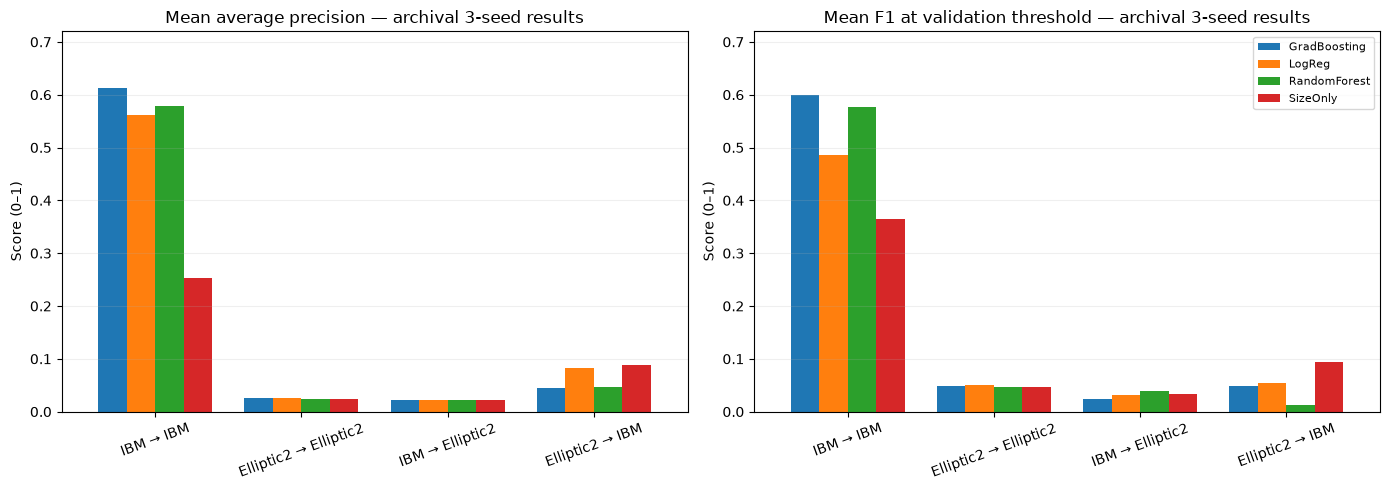

In [24]:
# Unit 5 | Recreate a concise plot directly from the previous notebook's
# saved UNRESTRICTED three-seed outputs. These are archival, not newly rerun.
archival = pd.DataFrame([
    ["IBM → IBM", "SizeOnly", 0.253, 0.365],
    ["IBM → IBM", "LogReg", 0.562, 0.486],
    ["IBM → IBM", "RandomForest", 0.579, 0.576],
    ["IBM → IBM", "GradBoosting", 0.613, 0.600],
    ["Elliptic2 → Elliptic2", "SizeOnly", 0.024, 0.047],
    ["Elliptic2 → Elliptic2", "LogReg", 0.025, 0.050],
    ["Elliptic2 → Elliptic2", "RandomForest", 0.024, 0.047],
    ["Elliptic2 → Elliptic2", "GradBoosting", 0.025, 0.049],
    ["IBM → Elliptic2", "SizeOnly", 0.023, 0.033],
    ["IBM → Elliptic2", "LogReg", 0.022, 0.031],
    ["IBM → Elliptic2", "RandomForest", 0.023, 0.040],
    ["IBM → Elliptic2", "GradBoosting", 0.022, 0.024],
    ["Elliptic2 → IBM", "SizeOnly", 0.088, 0.094],
    ["Elliptic2 → IBM", "LogReg", 0.083, 0.055],
    ["Elliptic2 → IBM", "RandomForest", 0.047, 0.012],
    ["Elliptic2 → IBM", "GradBoosting", 0.045, 0.048],
], columns=["experiment", "model", "archival_mean_AP", "archival_mean_F1"])
archival.to_csv(OUT / "unit5_archival_published_means.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, measure, title in ((axes[0], "archival_mean_AP", "Mean average precision"),
                           (axes[1], "archival_mean_F1", "Mean F1 at validation threshold")):
    pivot = archival.pivot(index="experiment", columns="model", values=measure)
    pivot = pivot.reindex(["IBM → IBM", "Elliptic2 → Elliptic2",
                           "IBM → Elliptic2", "Elliptic2 → IBM"])
    pivot.plot(kind="bar", ax=ax, rot=20, width=0.78, legend=False)
    ax.set_title(title + " — archival 3-seed results")
    ax.set_xlabel("")
    ax.set_ylabel("Score (0–1)")
    ax.set_ylim(0, 0.72)
    ax.grid(axis="y", alpha=0.2)
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "unit5_archival_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

# Unit 5 (Diagnostics) — Held-out PR curves, confusion matrices, and AP changes

**Description:** Visualize precision–recall curves, confusion matrices at the validation-selected thresholds, and the outer-test AP delta between `baseline_same_split` and `tuned` models.

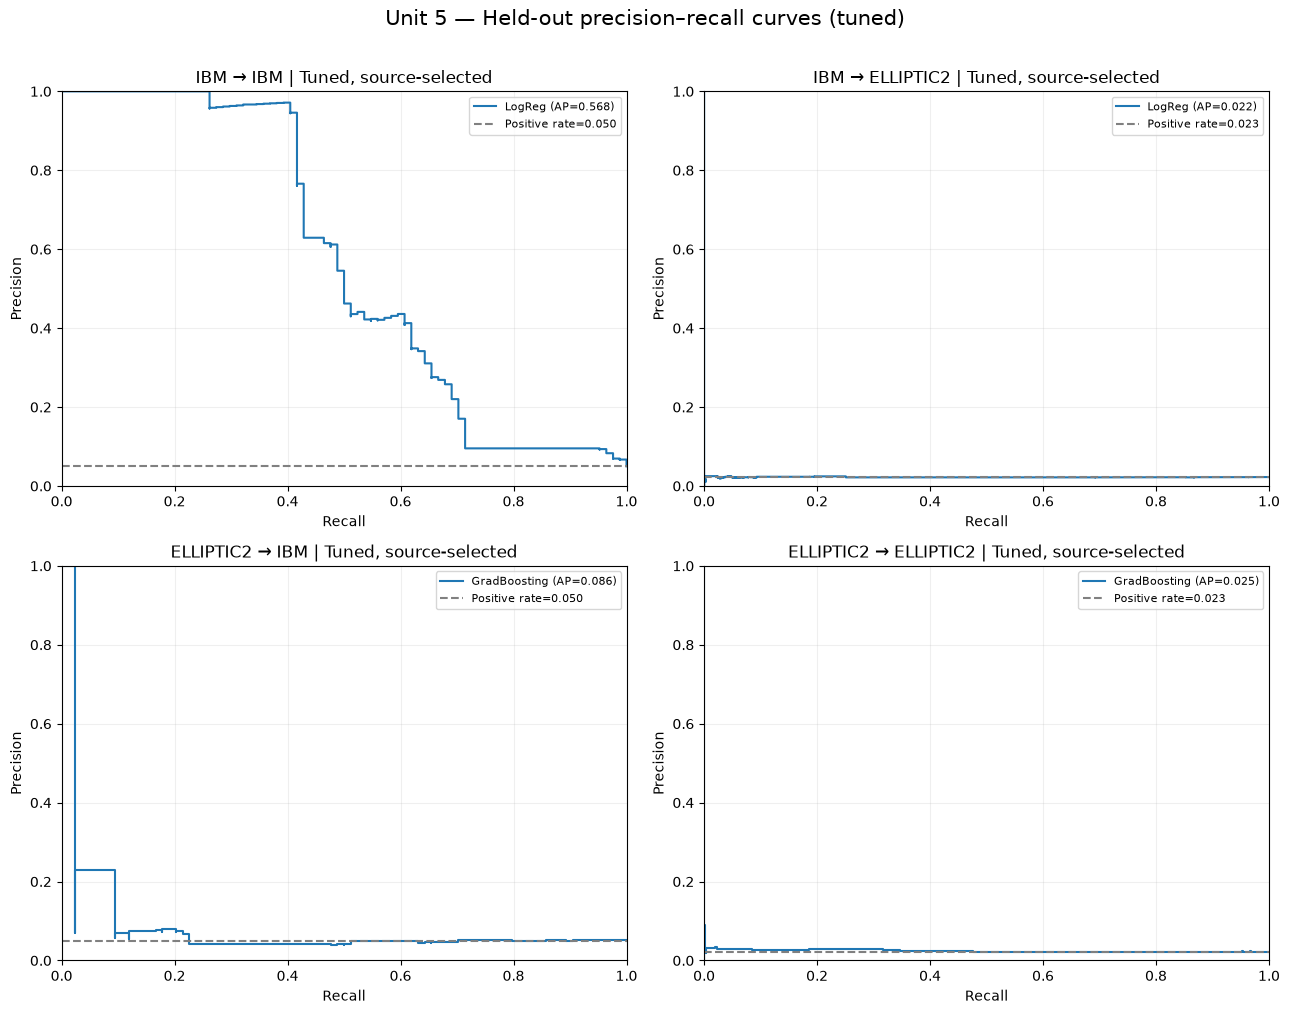

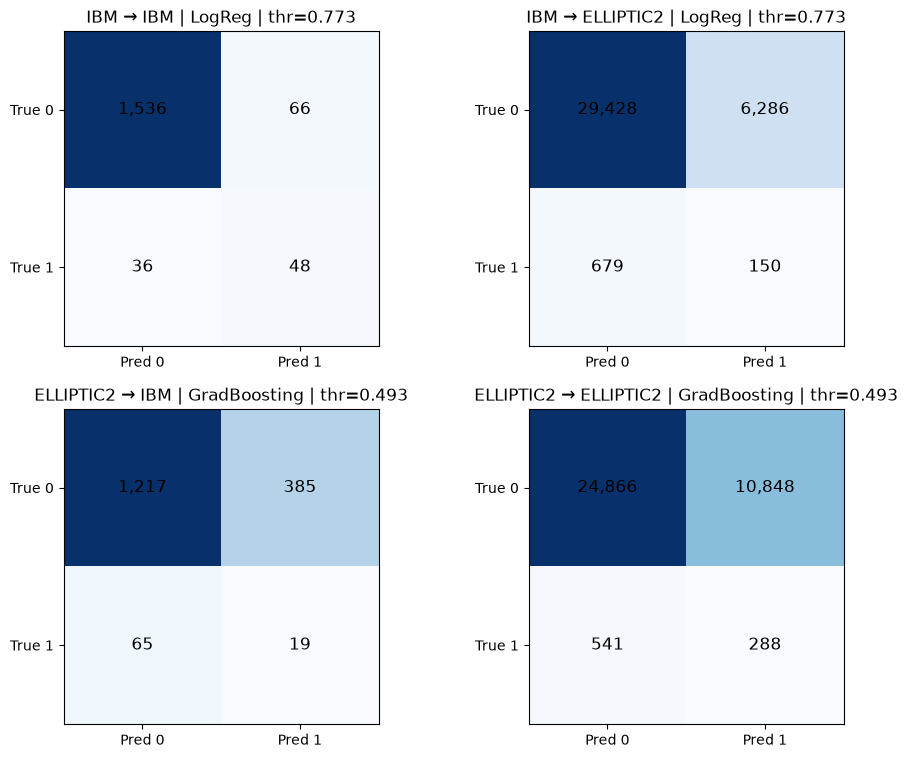

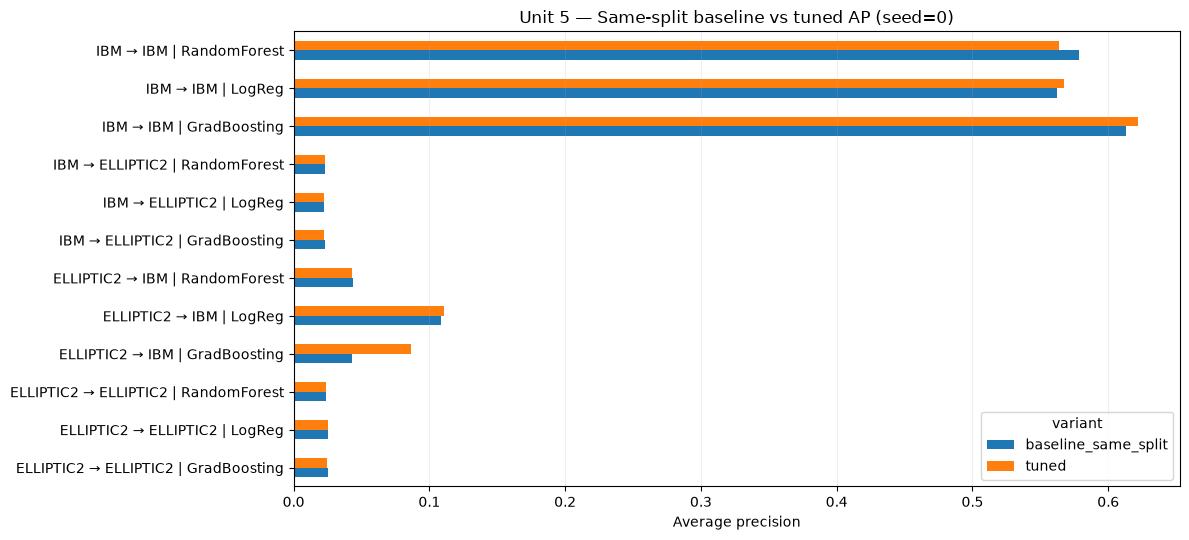

Changes in OUTER-TEST AP after validation-based tuning (not guaranteed positive):


variant,baseline_same_split,tuned,tuned_calibrated,AP_change
setting,,,,
ELLIPTIC2 → ELLIPTIC2 | GradBoosting,0.0256,0.0248,0.0248,-0.0008
ELLIPTIC2 → ELLIPTIC2 | LogReg,0.0256,0.0256,0.0256,-0.0000
ELLIPTIC2 → ELLIPTIC2 | RandomForest,0.0238,0.0241,0.0241,0.0003
ELLIPTIC2 → IBM | GradBoosting,0.0432,0.0863,0.0863,0.0431
ELLIPTIC2 → IBM | LogReg,0.1089,0.1105,0.1105,0.0017
ELLIPTIC2 → IBM | RandomForest,0.0438,0.0429,0.0429,-0.0009
IBM → ELLIPTIC2 | GradBoosting,0.0230,0.0227,0.0227,-0.0003
IBM → ELLIPTIC2 | LogReg,0.0224,0.0223,0.0223,-0.0001
IBM → ELLIPTIC2 | RandomForest,0.0231,0.0230,0.0230,-0.0001


In [25]:
# Unit 5 | Evaluation plots, AP-lift comparison, error counts, and audit notes.
from sklearn.metrics import precision_recall_curve

chosen_by_validation = (selected_hyperparams.sort_values(
    "validation_ap_selected_on", ascending=False
).drop_duplicates("source").set_index("source"))

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig_cm, axes_cm = plt.subplots(2, 2, figsize=(11, 9))
plot_records = []
for i, src in enumerate(TUNING_DOMAINS):
    best_name = chosen_by_validation.loc[src, "model"]
    for j, tgt in enumerate(TUNING_DOMAINS):
        pred = tuned_predictions.query(
            "source == @src and target == @tgt and model == @best_name"
        )
        y = pred.y_true.to_numpy()
        p = pred.probability.to_numpy()
        threshold = float(pred.threshold.iloc[0])
        prec, rec, _ = precision_recall_curve(y, p)
        ax = axes[i, j]
        ax.step(rec, prec, where="post", label=f"{best_name} (AP={average_precision_score(y,p):.3f})")
        ax.axhline(y.mean(), color="gray", linestyle="--", label=f"Positive rate={y.mean():.3f}")
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
               title=f"{src.upper()} → {tgt.upper()} | Tuned, source-selected")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)

        cm = confusion_matrix(y, pred.predicted_class.to_numpy(), labels=[0, 1])
        im = axes_cm[i,j].imshow(cm, cmap="Blues")
        axes_cm[i,j].set_title(f"{src.upper()} → {tgt.upper()} | {best_name} | thr={threshold:.3f}")
        axes_cm[i,j].set_xticks([0, 1], ["Pred 0", "Pred 1"])
        axes_cm[i,j].set_yticks([0, 1], ["True 0", "True 1"])
        for row in range(2):
            for col in range(2):
                axes_cm[i,j].text(col, row, f"{cm[row,col]:,}",
                                  va="center", ha="center", fontsize=12)
        plot_records.append({"source": src, "target": tgt, "model": best_name,
                             "threshold": threshold, "tn": int(cm[0,0]),
                             "fp": int(cm[0,1]), "fn": int(cm[1,0]),
                             "tp": int(cm[1,1]), "positive_rate": float(y.mean())})
fig.suptitle("Unit 5 — Held-out precision–recall curves (tuned)", y=1.01, fontsize=15)
fig.tight_layout()
fig.savefig(OUT / "unit5_tuned_precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show()
fig_cm.suptitle("Unit 5 — Held-out confusion matrices", y=1.01, fontsize=15)
fig_cm.tight_layout()
fig_cm.savefig(OUT / "unit5_tuned_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

pd.DataFrame(plot_records).to_csv(OUT / "unit5_selected_error_counts.csv", index=False)
fig2, ax = plt.subplots(figsize=(12, 5.5))
labels = (tuned_evaluation.source.str.upper() + " → " +
          tuned_evaluation.target.str.upper() + " | " + tuned_evaluation.model)
plot_data = tuned_evaluation.assign(setting=labels).pivot_table(
    index="setting", columns="variant", values="pr_auc")
cols_avail = [c for c in ("baseline_same_split", "tuned") if c in plot_data.columns]
plot_data[cols_avail].dropna().plot(kind="barh", ax=ax)
ax.set_title("Unit 5 — Same-split baseline vs tuned AP (seed=0)")
ax.set_xlabel("Average precision"); ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
fig2.tight_layout()
fig2.savefig(OUT / "unit5_tuned_vs_baseline_same_split.png", dpi=160, bbox_inches="tight")
plt.show()

comparison = plot_data.assign(
    AP_change=lambda x: x["tuned"] - x["baseline_same_split"]).dropna()
print("Changes in OUTER-TEST AP after validation-based tuning (not guaranteed positive):")
display(comparison.round(4))


# Unit 6 — Illustrative base-rate sensitivity (Bayes' rule PPV)

**Description:** Demonstrate why a classifier's Positive Predictive Value (precision) depends strongly on the true laundering prevalence in deployment, even at fixed sensitivity (80% TPR) and specificity (2% FPR).

Illustration only: TPR=80%, FPR=2%; not derived from the notebook's models


,hypothetical_positive_rate,hypothetical_precision_PPV,hypothetical_false_alerts_per_10000
0,0.001,0.0385,199.8
1,0.005,0.1674,199.0
2,0.010,0.2878,198.0
3,0.023,0.4850,195.4
4,0.050,0.6780,190.0
5,0.100,0.8163,180.0


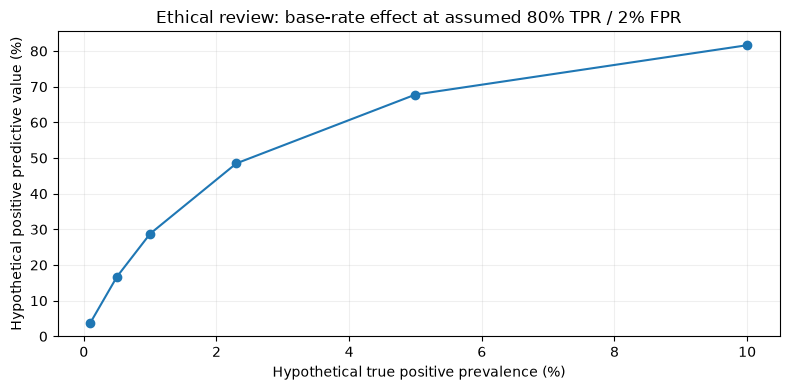

In [26]:
# Unit 6 | Hypothetical base-rate sensitivity — not real-world AML performance.
# Formula is Bayes' rule for PPV, using explicit illustrative rates.
illustrative_tpr = 0.80   # hypothetical true-positive rate (not fitted here)
illustrative_fpr = 0.02   # hypothetical false-positive rate (not fitted here)
possible_prevalences = np.array([0.001, 0.005, 0.01, 0.023, 0.05, 0.10])
ppv = (illustrative_tpr * possible_prevalences /
       (illustrative_tpr * possible_prevalences +
        illustrative_fpr * (1.0 - possible_prevalences)))
illustrative = pd.DataFrame({
    "hypothetical_positive_rate": possible_prevalences,
    "hypothetical_precision_PPV": ppv,
    "hypothetical_false_alerts_per_10000":
        10000 * (1.0 - possible_prevalences) * illustrative_fpr,
})
print("Illustration only: TPR=80%, FPR=2%; not derived from the notebook's models")
display(illustrative.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(100 * possible_prevalences, 100 * ppv, marker="o")
ax.set(xlabel="Hypothetical true positive prevalence (%)",
       ylabel="Hypothetical positive predictive value (%)",
       title="Ethical review: base-rate effect at assumed 80% TPR / 2% FPR")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "unit6_hypothetical_base_rate_sensitivity.png", dpi=160)
plt.show()

# Research extension — stronger validation and sensitivity experiments

**Purpose:** Improve the scientific validity of the original AML analysis without rewriting or overwriting the historical results above. The earlier results and tuning experiments remain an **archived benchmark**. New results are computed only when these new cells are executed on the actual source datasets.

**Questions addressed:**

1. **Candidate-generation bias:** Does a classifier still discriminate when both classes use the **same BFS subgraph-construction procedure**?
2. **Leakage/dependence:** How many held-out examples share edges, accounts, or transaction time windows with training?
3. **Feature attribution:** Which of the 14 structural measurements actually provide information beyond graph size?
4. **Decision thresholds:** What recall can be obtained under a minimum validation precision requirement?
5. **Domain shift:** Do feature distributions differ between IBM and Elliptic2, even within the same labeled class?

**Honest interpretation:** The alternative sampler uses a class-enriched seed mixture to obtain enough positives, then assigns the label *after* graph construction. This is a **sensitivity analysis**, not an unbiased estimate of real-world laundering prevalence or a perfect correction for selection bias. An enriched seed strategy may still influence the sample. Its labels mean *at least one annotated laundering transaction in the sampled graph*, which is not identical to the documented-attempt labels used in the main experiment. Thus, do not interpret a raw AP difference between the two datasets as an apples-to-apples improvement.

**Dependencies:** Execute the original notebook from the top, including the Unit 4/5 tuning cells. This extension uses their in-memory `idx`, `ibm`, `DATA`, `FEATURES`, `make_splits`, `chosen_models` and other objects. Downloads require access to the listed dataset URLs. New outputs are stored under `outputs/research_extension/` and never overwrite `results_raw.csv` or the previously saved figures.

## Extension 1 — Configuration and reproducibility

**What this cell does:** Defines the number of new examples, common BFS graph sizes and durations, a dedicated random-number generator, output paths, and a utility that handles test folds with only one class. This run generates **2,500 candidates** so the sensitivity estimate is more stable than a smaller pilot sample while remaining fast to compute. This cell does not alter the original `rng` used in the core analysis.

In [27]:
from collections import deque
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
                             precision_score, recall_score, f1_score, precision_recall_curve)
from sklearn.inspection import permutation_importance
from scipy.stats import ks_2samp

EXT = OUT / "research_extension"
EXT.mkdir(parents=True, exist_ok=True)
EXT_SEED = 2026
EXT_RNG = np.random.default_rng(EXT_SEED)
N_COMMON_CANDIDATES = 2500
POSITIVE_SEED_PROBABILITY = 0.40  # intentional enrichment, not population prevalence
COMMON_NODE_SIZES = (3, 4, 5, 6, 8, 10)
COMMON_WINDOWS_MIN = (60, 180, 360)
EMBARGO_MIN = 120
MIN_PREDICTED_POSITIVES_FOR_PRECISION = 5


def safe_ap(y, p):
    y = np.asarray(y, dtype=int)
    if len(y) == 0 or np.unique(y).size < 2:
        return float('nan')
    return float(average_precision_score(y, p))


def measure(y, prob, threshold):
    """All classification metrics use the PRESELECTED threshold."""
    y = np.asarray(y, dtype=int)
    prob = np.asarray(prob, dtype=float)
    if y.size == 0 or np.unique(y).size < 2:
        return {"status": "not_estimable_both_labels_required", "n": int(y.size),
                "positives": int(y.sum()), "AP": np.nan, "ROC_AUC": np.nan,
                "precision": np.nan, "recall": np.nan, "F1": np.nan,
                "FP": np.nan, "FN": np.nan}
    pred = (prob >= float(threshold)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prev = float(y.mean())
    return {"status": "ok", "n": int(y.size), "positives": int(y.sum()),
            "prevalence": prev, "AP": safe_ap(y, prob),
            "AP_lift": safe_ap(y, prob) / prev,
            "ROC_AUC": float(roc_auc_score(y, prob)),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "F1": float(f1_score(y, pred, zero_division=0)),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

print("Research-extension output directory:", EXT)
print("Candidates:", N_COMMON_CANDIDATES, "seed enrichment:", POSITIVE_SEED_PROBABILITY)


Research-extension output directory: <PROJECT_DIR>/outputs/research_extension
Candidates: 2500 seed enrichment: 0.4


## Extension 2 — Common construction method for positive and negative graphs

**What changes?** The original IBM benchmark constructs positive subgraphs from annotated **attempts** but negative subgraphs with BFS. Here both candidate types are constructed by **the exact same time-restricted BFS**; the BFS does not look at laundering labels. The sampler starts either from a uniform random transaction or, for enrichment, an annotated transaction. **Only after the candidate graph has been formed** do we define the target as `any(is_laundering == 1)` among its induced transactions.

**Why enrichment?** A naive uniform transaction-seed sampler may contain almost no positive examples; the mixed seed pool improves the feasibility of comparing two classes. However, the seed pool is still class-dependent and could produce biases. The results are therefore an exploratory **sampling-control/sensitivity** experiment, *not* evidence that every source of sampling bias has been removed.

**Other safeguards:** fixed graph-size/window-length choices independent of the candidate label, no label-based filtering during BFS, duplicate-graph signatures removed, and all parameters recorded.

In [28]:
def common_bfs_candidate(seed_edge, n_target, duration_min, generator):
    """Construct a candidate using BFS over ALL transactions (no label filtering).

    The graph's eventual label is computed only AFTER the induced edges are chosen.
    """
    seed_edge = int(seed_edge)
    t_seed = int(idx.t[seed_edge])
    # Every seed transaction remains inside its own sampled time window.
    before = int(generator.integers(0, duration_min + 1))
    t0 = t_seed - before
    t1 = t0 + int(duration_min)
    s0, d0 = int(idx.s[seed_edge]), int(idx.d[seed_edge])
    seen = {s0, d0}
    queue = deque([s0, d0])
    while queue and len(seen) < n_target:
        u = queue.popleft()
        adjacent = np.concatenate([idx.out_e(u), idx.in_e(u)])
        if adjacent.size == 0:
            continue
        valid = adjacent[(idx.t[adjacent] >= t0) & (idx.t[adjacent] <= t1)]
        if valid.size == 0:
            continue
        neighbors = np.unique(np.concatenate([idx.s[valid], idx.d[valid]]))
        generator.shuffle(neighbors)
        for v in neighbors:
            vv = int(v)
            if vv not in seen:
                seen.add(vv)
                queue.append(vv)
                if len(seen) >= n_target:
                    break
    if len(seen) < 2:
        return None
    edges_found = idx.induced(seen, t0, t1)
    if edges_found.size == 0:
        return None
    return {"nodes": seen, "edges": np.asarray(edges_found, dtype=np.int64),
            "t0": t0, "t1": t1}


def generate_common_candidates(n=N_COMMON_CANDIDATES, generator=EXT_RNG):
    positive_seed_indices = np.flatnonzero(np.asarray(idx.y) == 1)
    if positive_seed_indices.size == 0:
        raise RuntimeError("No annotated laundering transactions found in IBM data")
    rows, nodes_by_id, edges_by_id, windows_by_id = [], {}, {}, {}
    signatures = set()
    attempts = 0
    source_counts = {"uniform": 0, "positive_enriched": 0}
    max_tries = max(20 * int(n), 1000)
    while len(rows) < n and attempts < max_tries:
        attempts += 1
        mode = "positive_enriched" if generator.random() < POSITIVE_SEED_PROBABILITY else "uniform"
        if mode == "positive_enriched":
            seed_edge = int(generator.choice(positive_seed_indices))
        else:
            seed_edge = int(generator.integers(0, len(idx.y)))
        n_target = int(generator.choice(COMMON_NODE_SIZES))
        duration = int(generator.choice(COMMON_WINDOWS_MIN))
        graph = common_bfs_candidate(seed_edge, n_target, duration, generator)
        if graph is None:
            continue
        # Dedupe identical node groups + time windows across seed sampling modes.
        signature = (graph["t0"], graph["t1"], tuple(sorted(graph["nodes"])))
        if signature in signatures:
            continue
        signatures.add(signature)
        edges_idx = graph["edges"]
        label = int(np.any(np.asarray(idx.y)[edges_idx] == 1))
        sg_id = f"common_{len(rows):05d}"
        features = graph_features(graph["nodes"], zip(idx.s[edges_idx], idx.d[edges_idx]))
        rows.append({"sg_id": sg_id, "label": label, "t_start": graph["t0"],
                     "t_end": graph["t1"], "seed_source": mode,
                     "target_nodes": n_target, "window_minutes": duration, **features})
        nodes_by_id[sg_id] = np.asarray(sorted(graph["nodes"]), dtype=np.int64)
        edges_by_id[sg_id] = np.unique(edges_idx)
        windows_by_id[sg_id] = (graph["t0"], graph["t1"])
        source_counts[mode] += 1
    df = pd.DataFrame(rows)
    if len(df) < n:
        print(f"WARNING: requested {n} unique candidates, obtained {len(df)}")
    if df.empty or df.label.nunique() < 2:
        raise RuntimeError("Common sampler lacks both labels. Increase N_COMMON_CANDIDATES or review source annotations.")
    return df, nodes_by_id, edges_by_id, windows_by_id, {"attempts": attempts, "seed_counts": source_counts}

common_df, common_nodes, common_edges, common_windows, common_info = generate_common_candidates()
common_df.to_csv(EXT / "common_bfs_candidates.csv", index=False)
print("Common-construction candidate count:", len(common_df))
print("Class balance:", common_df.label.value_counts().sort_index().to_dict())
print("Seed sources:", common_info["seed_counts"])
display(common_df.groupby(["seed_source", "label"]).agg(
    graphs=("sg_id", "count"), mean_nodes=("n_nodes", "mean"),
    mean_edges=("n_edges", "mean")).round(3))

Common-construction candidate count: 2500
Class balance: {0: 1460, 1: 1040}
Seed sources: {'uniform': 1463, 'positive_enriched': 1037}


graphs  mean_nodes  mean_edges
seed_source       label                                
positive_enriched 1        1037       3.311       2.324
uniform           0        1460       3.203       2.203
                  1           3       4.667       3.667

## Extension 3 — Chronological split, time embargo and edge-overlap purge

**Why it matters:** A model should not train and test on the same transaction events. We sort candidates by start time, initially allocate **60% train / 20% validation / 20% test**, then **drop later candidates** whose time windows fall within an embargo from the preceding partition or whose transaction IDs occur in earlier partitions. We log how many examples remain and whether every partition contains both classes.

A time embargo changes the effective sample sizes, and repeated accounts may still occur in different time periods. An additional **account-disjoint stress test** appears later. Nothing from the test labels is used to choose hyperparameters or thresholds.

In [29]:
def chronological_embargo_split(df, edge_map, embargo_minutes=EMBARGO_MIN):
    ordered = df.sort_values(["t_start", "sg_id"]).reset_index(drop=True)
    n = len(ordered)
    first = ordered.iloc[:int(0.60 * n)]
    second = ordered.iloc[int(0.60 * n):int(0.80 * n)]
    third = ordered.iloc[int(0.80 * n):]
    train_ids = first.sg_id.tolist()
    train_latest_end = int(first.t_end.max())
    val_after_time = second[second.t_start > train_latest_end + embargo_minutes]
    seen_train_edges = set()
    for ident in train_ids:
        seen_train_edges.update(edge_map[ident].tolist())
    val_ids = [ident for ident in val_after_time.sg_id
               if seen_train_edges.isdisjoint(edge_map[ident].tolist())]
    if not val_ids:
        raise RuntimeError("Embargo removed all validation graphs. Reduce EMBARGO_MIN or increase candidate count.")
    val_max_end = int(ordered.set_index("sg_id").loc[val_ids, "t_end"].max())
    test_after_time = third[third.t_start > val_max_end + embargo_minutes]
    seen_previous_edges = set(seen_train_edges)
    for ident in val_ids:
        seen_previous_edges.update(edge_map[ident].tolist())
    test_ids = [ident for ident in test_after_time.sg_id
                if seen_previous_edges.isdisjoint(edge_map[ident].tolist())]
    groups = {"train": train_ids, "validation": val_ids, "test": test_ids}
    audit = []
    lookup = df.set_index("sg_id")
    for name, ids in groups.items():
        labels = lookup.loc[ids, "label"].to_numpy(dtype=int) if ids else np.array([], dtype=int)
        audit.append({"partition": name, "n": len(ids), "positive": int(labels.sum()),
                      "negative": int((labels == 0).sum()),
                      "positive_rate": float(labels.mean()) if labels.size else np.nan})
    return groups, pd.DataFrame(audit)

common_splits, common_audit = chronological_embargo_split(common_df, common_edges)
common_audit.to_csv(EXT / "common_split_audit.csv", index=False)
print("The split below is computed AFTER the time embargo and edge purge:")
display(common_audit)
if any(row["positive"] == 0 or row["negative"] == 0 for _, row in common_audit.iterrows()):
    raise RuntimeError("A common-sampler split has only one class. Increase N_COMMON_CANDIDATES, check time coverage, and rerun. Do NOT use a random fallback silently.")

# Confirm pairwise transaction ID disjointness.
for x, y in (("train", "validation"), ("train", "test"), ("validation", "test")):
    ex = set().union(*(set(common_edges[i]) for i in common_splits[x]))
    ey = set().union(*(set(common_edges[i]) for i in common_splits[y]))
    assert ex.isdisjoint(ey), f"Transaction-edge overlap between {x} and {y}"
print("PASS: no transaction-row ID occurs in two different candidate partitions.")

The split below is computed AFTER the time embargo and edge purge:


,partition,n,positive,negative,positive_rate
0,train,1500,542,958,0.361333
1,validation,437,178,259,0.407323
2,test,382,253,129,0.662304


PASS: no transaction-row ID occurs in two different candidate partitions.


## Extension 4 — Train and evaluate on the common-construction sample

**What is being tested?** Whether the original four classification strategies are still informative on graphs generated using the same BFS rule for both labels. Use the **fixed original model configurations** (no test-driven retuning). Choose the operating threshold on the validation set, pick the single validation-AP winner, and evaluate all models once on the untouched test set. Compare **AP to the baseline equal to test positive prevalence**, rather than comparing raw AP across datasets with different prevalence.

**Important:** This changes the labeling task from *documented attempt* to *contains at least one annotated suspicious transaction*. A lower AP may reflect this change, not just sampling bias. A high AP can still reflect enriched seed selection, so neither outcome fully resolves causality.

Validation-selected model: GradBoosting


,experiment,model,validation_AP,threshold_from_validation,n_train,n_validation,status,n,positives,prevalence,AP,AP_lift,ROC_AUC,precision,recall,F1,TN,FP,FN,TP,selected_by_validation
3,common_BFS_sensitivity,GradBoosting,0.5380,0.3969,1500,437,ok,382,253,0.6623,0.7258,1.0959,0.6061,0.6786,0.9763,0.8006,12,117,6,247,True
1,common_BFS_sensitivity,LogReg,0.5323,0.2433,1500,437,ok,382,253,0.6623,0.7158,1.0808,0.5795,0.6623,1.0000,0.7969,0,129,0,253,False
2,common_BFS_sensitivity,RandomForest,0.5267,0.3974,1500,437,ok,382,253,0.6623,0.7219,1.0900,0.6062,0.6749,0.9763,0.7981,10,119,6,247,False
0,common_BFS_sensitivity,SizeOnly,0.4220,0.4468,1500,437,ok,382,253,0.6623,0.6499,0.9812,0.4782,0.6623,1.0000,0.7969,0,129,0,253,False


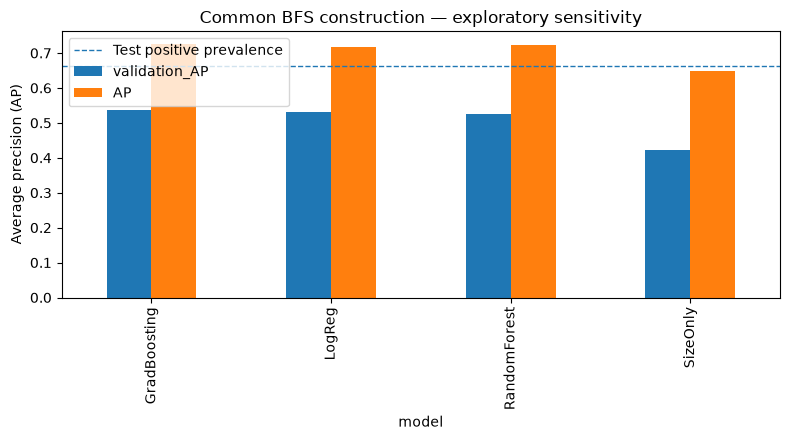

In [30]:
lookup_common = common_df.set_index("sg_id")
train_common = lookup_common.loc[common_splits["train"]]
val_common = lookup_common.loc[common_splits["validation"]]
test_common = lookup_common.loc[common_splits["test"]]

common_models = {}
common_rows = []
for model_name, (which, base_estimator) in models(EXT_SEED).items():
    columns = SIZE_COLS if which == "size" else FEATURES
    fitted = clone(base_estimator).fit(train_common[columns], train_common.label)
    val_prob = fitted.predict_proba(val_common[columns])[:, 1]
    val_ap = safe_ap(val_common.label.to_numpy(), val_prob)
    val_threshold = best_thr(val_common.label.to_numpy(), val_prob)
    p_test = fitted.predict_proba(test_common[columns])[:, 1]
    metric = measure(test_common.label.to_numpy(), p_test, val_threshold)
    common_rows.append({"experiment": "common_BFS_sensitivity", "model": model_name,
                        "validation_AP": val_ap, "threshold_from_validation": val_threshold,
                        "n_train": len(train_common), "n_validation": len(val_common),
                        **metric})
    common_models[model_name] = (fitted, list(columns), val_threshold)
common_results = pd.DataFrame(common_rows).sort_values("validation_AP", ascending=False)
common_winner = str(common_results.iloc[0]["model"])  # VALIDATION only
common_results["selected_by_validation"] = common_results.model.eq(common_winner)
common_results.to_csv(EXT / "common_bfs_model_results.csv", index=False)
print("Validation-selected model:", common_winner)
display(common_results.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
common_results.set_index("model")[["validation_AP", "AP"]].plot.bar(ax=ax)
ax.axhline(float(test_common.label.mean()), linestyle="--", linewidth=1,
           label="Test positive prevalence")
ax.set_ylabel("Average precision (AP)")
ax.set_title("Common BFS construction — exploratory sensitivity")
ax.legend()
fig.tight_layout()
fig.savefig(EXT / "common_BFS_AP.png", dpi=160)
plt.show()

## Extension 5 — Audit baseline independence and evaluate account-disjoint holdout

**Purpose:** The existing benchmark purges test graphs that reuse the *same transaction IDs*. It does not require accounts to be disjoint. This cell reports the exact fraction of held-out IBM subgraphs sharing any account with training, and creates two **stricter sensitivity subsets**:

- **Account-disjoint test:** remove every IBM test graph containing an account seen in training **or inner validation**.
- **Time-embargo test:** keep only IBM test windows that begin after all fitting/validation graph windows end, plus an additional embargo.

We evaluate the **model chosen on IBM validation AP**, not the model with the best test score. If either subset is tiny or lacks both labels, we clearly mark the result as not estimable instead of pretending that it is valid. The original training/validation split remains edge-purged rather than account-disjoint, so this is a *stronger holdout stress test*, not a fully account-disjoint retraining pipeline.

In [31]:
ibm_training_idx, ibm_test_idx, ibm_split_info = make_splits(TUNING_SEED)["ibm"]
ibm_fit_idx, ibm_val_idx, ibm_val_info = validation_indices("ibm", ibm_training_idx, TUNING_SEED)
seen_train_nodes = set()
seen_train_edges = set()
for ident in ibm_feat.sg_id.iloc[np.asarray(ibm_training_idx, dtype=int)]:
    seen_train_nodes.update(sets["ibm_nodes"][ident].tolist())
    seen_train_edges.update(sets["ibm_edges"][ident].tolist())

stress_records = []
identifiers = ibm_feat.sg_id.iloc[ibm_test_idx].tolist()
node_shared = [not seen_train_nodes.isdisjoint(sets["ibm_nodes"][ident].tolist())
               for ident in identifiers]
edge_shared = [not seen_train_edges.isdisjoint(sets["ibm_edges"][ident].tolist())
               for ident in identifiers]
if any(edge_shared):
    raise AssertionError("Unexpected overlap of transaction IDs in outer test split")
print(f"Original IBM test: {len(identifiers)} graphs; account-sharing fraction: "
      f"{np.mean(node_shared):.1%}; transaction-sharing fraction: {np.mean(edge_shared):.1%}")

account_disjoint_test = ibm_test_idx[np.logical_not(np.asarray(node_shared))]
# Original positive/negative graph windows are available in the source experiment.
original_end = {g["sg_id"]: int(g["t1"]) for g in positives + negatives}
all_train_val_ids = ibm_feat.sg_id.iloc[ibm_training_idx]
latest_train_end = max(original_end[ident] for ident in all_train_val_ids)
time_disjoint_test = np.asarray([
    pos for pos in ibm_test_idx if int(ibm_feat.t_start.iloc[pos]) > latest_train_end + EMBARGO_MIN
], dtype=int)

# The tuned model name is selected using source validation results ONLY.
selection_ibm = (selected_hyperparams[selected_hyperparams.source == "ibm"]
                 .sort_values("validation_ap_selected_on", ascending=False))
selected_name = str(selection_ibm.iloc[0].model)
selected_estimator, selected_columns, selected_threshold = chosen_models[("ibm", selected_name)]
for label, ids in (("original_edge_purged", ibm_test_idx),
                   ("account_disjoint_stress", account_disjoint_test),
                   ("time_embargo_stress", time_disjoint_test)):
    fragment = ibm_feat.iloc[np.asarray(ids, dtype=int)]
    if fragment.empty:
        metrics = measure(np.array([], dtype=int), np.array([], dtype=float), selected_threshold)
    else:
        p = selected_estimator.predict_proba(fragment[selected_columns])[:, 1]
        metrics = measure(fragment.label.to_numpy(), p, selected_threshold)
    stress_records.append({"subset": label, "selected_on_validation": selected_name,
                           "threshold_from_validation": selected_threshold,
                           "retention_fraction_of_original_test": len(ids) / max(1, len(ibm_test_idx)),
                           **metrics})
stress_table = pd.DataFrame(stress_records)
stress_table.to_csv(EXT / "original_split_dependence_stress.csv", index=False)
display(stress_table.round(4))
# --- Additional sensitivity: true account-disjoint retrain (zero shared accounts across fit/val/test) ---
def account_disjoint_partition(df, node_map, train_frac=0.60, val_frac=0.20, seed=EXT_SEED):
    """Greedily assign subgraphs so zero accounts overlap between fit, val, and test."""
    ordered = df.sort_values(["t_start", "sg_id"]).reset_index()
    fit_i, val_i, test_i = [], [], []
    seen_fit, seen_val, seen_test = set(), set(), set()
    n = len(ordered)
    n_fit_target = int(train_frac * n)
    n_val_target = int((train_frac + val_frac) * n)
    for k, row in ordered.iterrows():
        orig_idx = int(row["index"])
        nodes_k = set(node_map[row["sg_id"]].tolist())
        # Assign to earliest split that has no account conflict with later/other splits
        in_fit = not seen_fit.isdisjoint(nodes_k)
        in_val = not seen_val.isdisjoint(nodes_k)
        in_test = not seen_test.isdisjoint(nodes_k)
        if (in_fit and in_val) or (in_fit and in_test) or (in_val and in_test):
            continue  # drop bridge graphs that would couple partitions
        if in_fit or (not in_val and not in_test and len(fit_i) < n_fit_target):
            fit_i.append(orig_idx); seen_fit.update(nodes_k)
        elif in_val or (not in_test and len(fit_i) + len(val_i) < n_val_target):
            val_i.append(orig_idx); seen_val.update(nodes_k)
        else:
            test_i.append(orig_idx); seen_test.update(nodes_k)
    return np.asarray(fit_i, dtype=int), np.asarray(val_i, dtype=int), np.asarray(test_i, dtype=int)

ad_fit, ad_val, ad_test = account_disjoint_partition(ibm_feat, sets["ibm_nodes"])
ad_fit_df, ad_val_df, ad_test_df = ibm_feat.iloc[ad_fit], ibm_feat.iloc[ad_val], ibm_feat.iloc[ad_test]
if ad_fit_df.label.nunique() == 2 and ad_val_df.label.nunique() == 2 and ad_test_df.label.nunique() == 2:
    ad_est = clone(selected_estimator).fit(ad_fit_df[selected_columns], ad_fit_df.label)
    ad_pv = ad_est.predict_proba(ad_val_df[selected_columns])[:, 1]
    ad_thr = best_thr(ad_val_df.label.to_numpy(), ad_pv)
    ad_pt = ad_est.predict_proba(ad_test_df[selected_columns])[:, 1]
    ad_metrics = measure(ad_test_df.label.to_numpy(), ad_pt, ad_thr)
    print(f"\nTrue account-disjoint retrain: fit={len(ad_fit)}, val={len(ad_val)}, test={len(ad_test)} "
          f"| test AP={ad_metrics['AP']:.4f}, ROC-AUC={ad_metrics['ROC_AUC']:.4f}, F1={ad_metrics['F1']:.4f}")
    pd.DataFrame([{"split": "account_disjoint_retrain", "fit_n": len(ad_fit), "val_n": len(ad_val), **ad_metrics}]).to_csv(
        EXT / "account_disjoint_retrain.csv", index=False)
else:
    print("\nTrue account-disjoint retrain: skipped (one partition lacked both classes)")


Original IBM test: 1686 graphs; account-sharing fraction: 63.3%; transaction-sharing fraction: 0.0%


,subset,selected_on_validation,threshold_from_validation,retention_fraction_of_original_test,status,n,positives,prevalence,AP,AP_lift,ROC_AUC,precision,recall,F1,TN,FP,FN,TP
0,original_edge_purged,LogReg,0.7726,1.0000,ok,1686,84,0.0498,0.5677,11.3944,0.8769,0.4211,0.5714,0.4848,1536.0,66.0,36.0,48.0
1,account_disjoint_stress,LogReg,0.7726,0.3665,ok,618,15,0.0243,0.6099,25.1285,0.9133,0.1639,0.6667,0.2632,552.0,51.0,5.0,10.0
2,time_embargo_stress,LogReg,0.7726,0.0000,not_estimable_both_labels_required,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



True account-disjoint retrain: fit=6877, val=437, test=365 | test AP=0.6735, ROC-AUC=0.7611, F1=0.8000


## Extension 6 — Feature-group ablation on the original IBM benchmark

**Goal:** Identify whether size alone, topology without size, directional degree features, cycle features, or all 14 features carry predictive information. Every ablation uses the **same train/validation/test partitions** and the same estimator family/configuration selected from IBM **validation** in Unit 4. Only the feature subset changes, so we can study incremental value. The threshold is reselected on validation for each subset.

Ablation test metrics are **exploratory**. If these results inform a new feature-selection decision, you must use a subsequent untouched confirmatory test set; do not keep selecting from the same held-out test results.

,group,n_features,validation_AP,AP,AP_lift,F1
0,size_only,2,0.3301,0.2526,5.0693,0.3652
1,topology_excluding_size,12,0.7731,0.5657,11.3549,0.4589
2,degree_direction_only,7,0.5976,0.4257,8.5441,0.3846
3,cycle_related_only,3,0.4424,0.3100,6.2219,0.2945
4,all_excluding_cycle,12,0.7695,0.5712,11.4652,0.4859
5,all_14,14,0.7692,0.5677,11.3944,0.4848


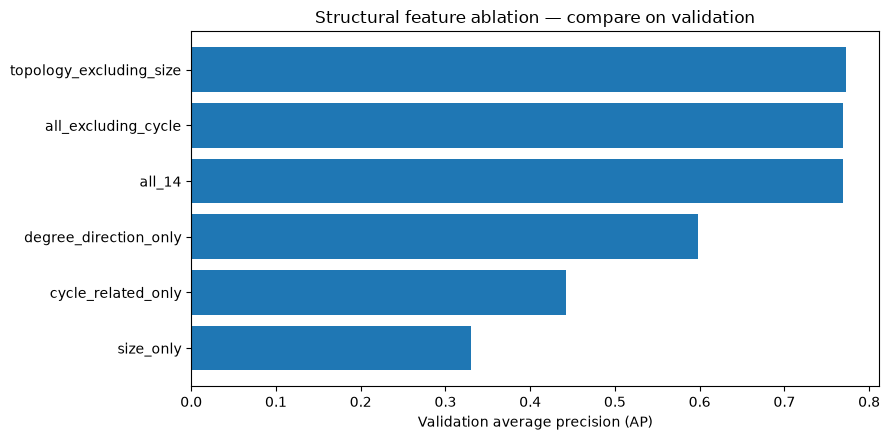

In [32]:
ABLATION_GROUPS = {
    "size_only": ["n_nodes", "n_edges"],
    "topology_excluding_size": [f for f in FEATURES if f not in ("n_nodes", "n_edges")],
    "degree_direction_only": ["max_in_deg_norm", "max_out_deg_norm", "hub_share", "deg_gini",
                              "frac_sources", "frac_sinks", "frac_passthrough"],
    "cycle_related_only": ["has_cycle", "reciprocity", "longest_chain_norm"],
    "all_excluding_cycle": [f for f in FEATURES if f not in ("has_cycle", "reciprocity")],
    "all_14": list(FEATURES),
}
selected_estimator, _, _ = chosen_models[("ibm", selected_name)]
fit_df = ibm_feat.iloc[ibm_fit_idx]
val_df = ibm_feat.iloc[ibm_val_idx]
test_df = ibm_feat.iloc[ibm_test_idx]
ablation_rows = []
for group, columns in ABLATION_GROUPS.items():
    estimator = clone(selected_estimator).fit(fit_df[columns], fit_df.label)
    pv = estimator.predict_proba(val_df[columns])[:, 1]
    pt = estimator.predict_proba(test_df[columns])[:, 1]
    threshold = best_thr(val_df.label.to_numpy(), pv)
    ablation_rows.append({"group": group, "model": selected_name, "features": ", ".join(columns),
                          "n_features": len(columns), "validation_AP": safe_ap(val_df.label, pv),
                          "validation_threshold": threshold,
                          **measure(test_df.label, pt, threshold)})
ablation_results = pd.DataFrame(ablation_rows)
ablation_results.to_csv(EXT / "feature_ablation.csv", index=False)
display(ablation_results[["group", "n_features", "validation_AP", "AP", "AP_lift", "F1"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_ablate = ablation_results.sort_values("validation_AP")
ax.barh(plot_ablate.group, plot_ablate.validation_AP)
ax.set_xlabel("Validation average precision (AP)")
ax.set_title("Structural feature ablation — compare on validation")
fig.tight_layout()
fig.savefig(EXT / "ablation_validation_AP.png", dpi=160)
plt.show()

## Extension 7 — Permutation importance without peeking at test labels

**Method:** For the fitted model selected on validation, shuffle each graph feature in the **validation** data and measure the decrease in average precision. We use multiple shuffles and report a mean and standard deviation. This is more interpretable than simply inspecting raw tree feature counts, but it is still **associational**, not causal, and correlated graph features may split importance across each other.

The validation set is relatively small for the positive class, so the rankings may be noisy. We do not use the test set to rank features.

,feature,AP_drop_mean,AP_drop_std
7,deg_gini,0.6480,0.0458
2,density,0.4946,0.0295
11,longest_chain_norm,0.4399,0.0250
10,frac_passthrough,0.3323,0.0306
6,hub_share,0.2594,0.0325
3,edges_per_node,0.2308,0.0200
0,n_nodes,0.0292,0.0141
1,n_edges,0.0119,0.0284
13,reciprocity,0.0064,0.0073
8,frac_sources,0.0040,0.0015


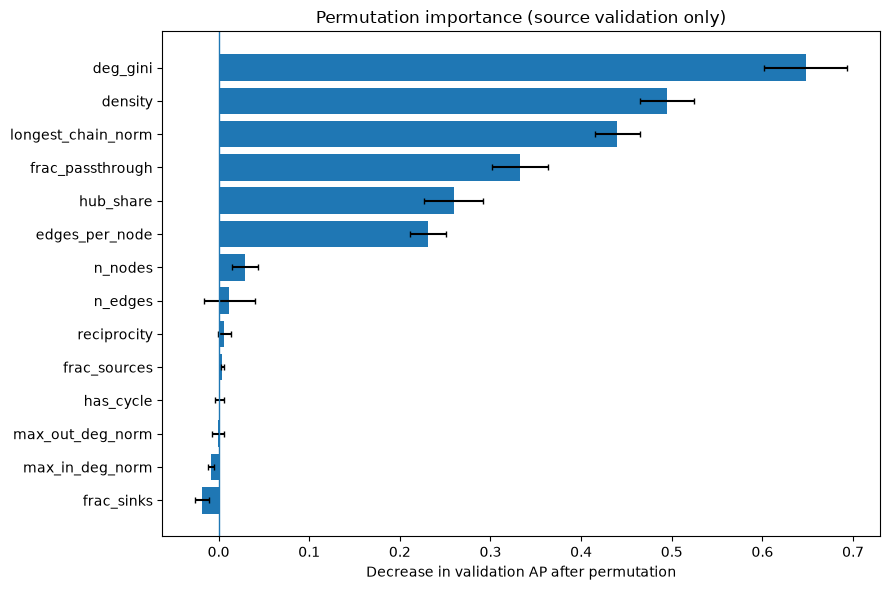

In [33]:
selected_estimator, selected_columns, _ = chosen_models[("ibm", selected_name)]
perm = permutation_importance(
    selected_estimator, val_df[selected_columns], val_df.label,
    scoring="average_precision", n_repeats=8,
    random_state=EXT_SEED, n_jobs=1
)
feature_importance = pd.DataFrame({
    "feature": selected_columns,
    "AP_drop_mean": perm.importances_mean,
    "AP_drop_std": perm.importances_std,
}).sort_values("AP_drop_mean", ascending=False)
feature_importance.to_csv(EXT / "permutation_importance_validation.csv", index=False)
display(feature_importance.round(4))
fig, ax = plt.subplots(figsize=(9, 6))
pdata = feature_importance.sort_values("AP_drop_mean")
ax.barh(pdata.feature, pdata.AP_drop_mean, xerr=pdata.AP_drop_std, capsize=2)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Decrease in validation AP after permutation")
ax.set_title("Permutation importance (source validation only)")
fig.tight_layout()
fig.savefig(EXT / "permutation_importance_validation.png", dpi=160)
plt.show()

## Extension 8 — Choose thresholds using validation precision/recall requirements

**Problem with the old operating point:** The historical tuned classifier had near-perfect precision but missed many suspicious graphs. Here we compare two **validation-defined** policies on the same fitted model: (a) maximize validation F1, and (b) maximize validation recall subject to validation precision of at least **80%**, with at least **five predicted positives**. If the precision requirement is infeasible, report it openly and do **not** claim that the requirement was met.

The test set is evaluated **once at each preselected threshold**. This is an analytical sensitivity curve, *not* a claim of true banking-world operating performance. The prevalence of suspicious graphs in this constructed sample is not representative of deployment prevalence.

,policy,status,threshold,validation_precision,validation_recall,n,positives,prevalence,AP,AP_lift,ROC_AUC,precision,recall,F1,TN,FP,FN,TP
0,validation_max_F1,ok,0.7726,0.8077,0.7,1686,84,0.0498,0.5677,11.3944,0.8769,0.4211,0.5714,0.4848,1536,66,36,48
1,validation_precision_at_least_80pct,ok,0.7726,0.8077,0.7,1686,84,0.0498,0.5677,11.3944,0.8769,0.4211,0.5714,0.4848,1536,66,36,48


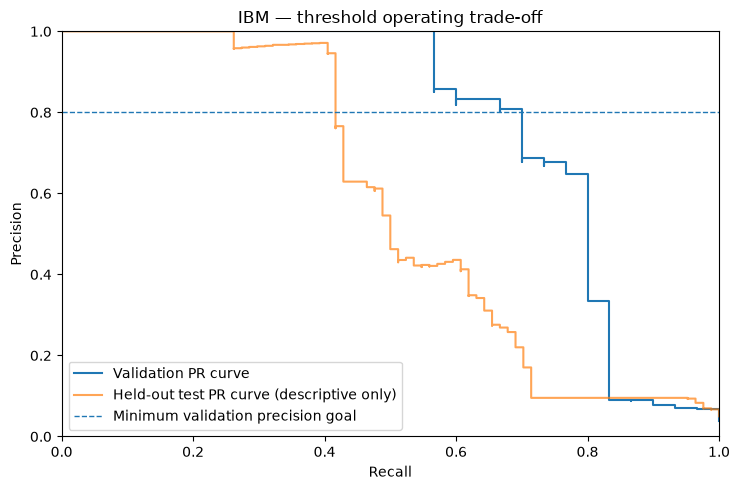

In [34]:
def threshold_for_min_precision(y, prob, min_precision=0.80, min_alerts=MIN_PREDICTED_POSITIVES_FOR_PRECISION):
    """Choose threshold by validation data only; maximize recall under constraints."""
    y = np.asarray(y, dtype=int)
    prob = np.asarray(prob, dtype=float)
    thresholds = np.unique(prob)
    candidates = []
    for threshold in thresholds:
        predicted = prob >= threshold
        alerts = int(predicted.sum())
        if alerts < min_alerts:
            continue
        prec = precision_score(y, predicted, zero_division=0)
        rec = recall_score(y, predicted, zero_division=0)
        if prec >= min_precision:
            candidates.append((rec, prec, -float(threshold), float(threshold), alerts))
    if not candidates:
        return None
    return max(candidates)[3]

fitted_final, chosen_features, _ = chosen_models[("ibm", selected_name)]
p_val = fitted_final.predict_proba(val_df[chosen_features])[:, 1]
p_test = fitted_final.predict_proba(test_df[chosen_features])[:, 1]
thresholds = {"validation_max_F1": best_thr(val_df.label.to_numpy(), p_val),
              "validation_precision_at_least_80pct": threshold_for_min_precision(
                  val_df.label.to_numpy(), p_val, min_precision=0.80)}
threshold_rows = []
for name, threshold in thresholds.items():
    if threshold is None:
        threshold_rows.append({"policy": name, "status": "not_feasible_on_validation",
                               "threshold": np.nan})
        continue
    val_results = measure(val_df.label.to_numpy(), p_val, threshold)
    test_results = measure(test_df.label.to_numpy(), p_test, threshold)
    threshold_rows.append({"policy": name, "status": "evaluated",
                           "threshold": threshold,
                           "validation_precision": val_results["precision"],
                           "validation_recall": val_results["recall"],
                           **test_results})
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(EXT / "threshold_tradeoff.csv", index=False)
display(threshold_table.round(4))

precision_v, recall_v, _ = precision_recall_curve(val_df.label, p_val)
precision_t, recall_t, _ = precision_recall_curve(test_df.label, p_test)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.step(recall_v, precision_v, where="post", label="Validation PR curve")
ax.step(recall_t, precision_t, where="post", alpha=0.7,
        label="Held-out test PR curve (descriptive only)")
ax.axhline(0.80, linestyle="--", linewidth=1, label="Minimum validation precision goal")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
       title="IBM — threshold operating trade-off")
ax.legend()
fig.tight_layout()
fig.savefig(EXT / "threshold_PR_tradeoff.png", dpi=160)
plt.show()

## Extension 9 — Diagnose IBM-to-Elliptic2 domain shift

**Purpose:** Compare the distribution of each shared graph feature between the IBM and Elliptic2 **outer-training partitions** (not the target test labels). We calculate the **two-sample KS statistic** for each feature overall and within the labeled classes. A high KS statistic means the distributions differ. We also display prevalence and size differences: even when AP is comparable, the sample constructions and class definitions differ.

**Interpretation warning:** KS statistics do not establish the *cause* of transfer failure, and many correlated comparisons are descriptive rather than formal multiple-testing-adjusted hypothesis tests. No domain labels are used to fit the classifier here.

,group,feature,ibm_n,elliptic2_n,ibm_mean,elliptic2_mean,KS_statistic
7,overall,deg_gini,5439,85267,0.252,0.087,0.595
11,overall,longest_chain_norm,5439,85267,0.462,0.892,0.577
2,overall,density,5439,85267,0.217,0.379,0.486
0,overall,n_nodes,5439,85267,10.199,3.652,0.484
1,overall,n_edges,5439,85267,9.411,2.821,0.476
3,overall,edges_per_node,5439,85267,0.811,0.666,0.425
9,overall,frac_sinks,5439,85267,0.528,0.382,0.385
10,overall,frac_passthrough,5439,85267,0.146,0.250,0.336
4,overall,max_in_deg_norm,5439,85267,0.446,0.693,0.335
8,overall,frac_sources,5439,85267,0.326,0.368,0.213


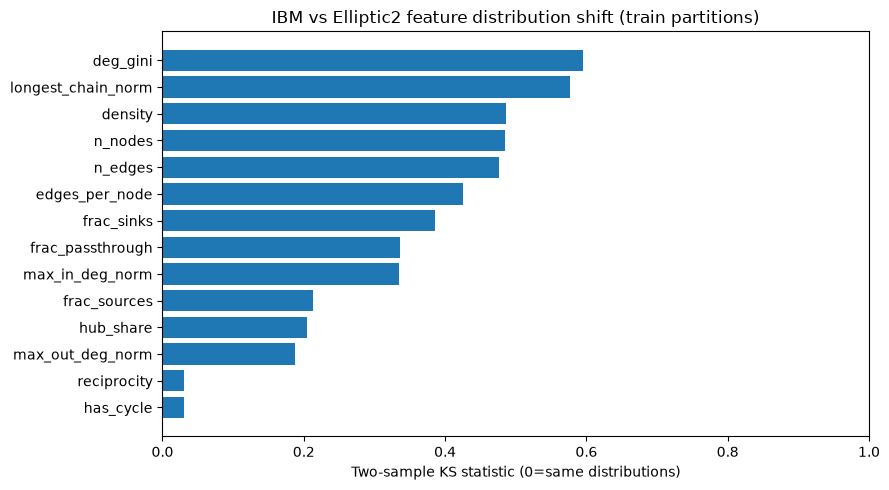

In [35]:
domain_records = []
original_splits = make_splits(TUNING_SEED)
ibm_train_full = ibm_feat.iloc[original_splits["ibm"][0]]
ell_train_full = ell_feat.iloc[original_splits["elliptic2"][0]]
for group_label, subset_label in ((None, "overall"), (0, "licit_only"), (1, "suspicious_only")):
    left = ibm_train_full if group_label is None else ibm_train_full[ibm_train_full.label == group_label]
    right = ell_train_full if group_label is None else ell_train_full[ell_train_full.label == group_label]
    for feature in FEATURES:
        x = left[feature].dropna().to_numpy(dtype=float)
        y = right[feature].dropna().to_numpy(dtype=float)
        if not len(x) or not len(y):
            continue
        ks = float(ks_2samp(x, y).statistic)
        domain_records.append({"group": subset_label, "feature": feature,
                               "ibm_n": len(x), "elliptic2_n": len(y),
                               "ibm_mean": float(np.mean(x)),
                               "elliptic2_mean": float(np.mean(y)),
                               "KS_statistic": ks})
domain_shift = pd.DataFrame(domain_records)
domain_shift.to_csv(EXT / "domain_shift_train_only.csv", index=False)
display(domain_shift[domain_shift.group == "overall"].sort_values(
    "KS_statistic", ascending=False).round(3))
fig, ax = plt.subplots(figsize=(9, 5))
shift_plot = domain_shift[domain_shift.group == "overall"].sort_values("KS_statistic")
ax.barh(shift_plot.feature, shift_plot.KS_statistic)
ax.set(xlim=(0, 1), xlabel="Two-sample KS statistic (0=same distributions)",
       title="IBM vs Elliptic2 feature distribution shift (train partitions)")
fig.tight_layout()
fig.savefig(EXT / "domain_shift_KS.png", dpi=160)
plt.show()

## Extension 10 — IBM-only transaction activity features and an additional model

**Why this matters:** The original 14 features summarize unique edges and nodes, discarding repeated transfers and transaction timing. In this *IBM-only exploratory experiment*, calculate six extra behavioral features for each pre-existing IBM subgraph: transaction count, transfers/hour over its declared time window, share of repeated directed pairs, maximum pair concentration, active span, and median transaction gap. These features use only the transaction rows already associated with each graph; they **never use `is_laundering`** during feature calculation.

Then compare the original 14 features with the expanded 20-feature representation using (a) the model selected by IBM validation in Unit 4 and (b) an additional **ExtraTrees** classifier. Choose the preferred configuration by **validation AP**. Display test results for transparency, but do not treat a test-selected winner as an independently confirmed improvement. To confirm any apparent gain, collect a new untouched test period.

**Scope limitation:** These features cannot be transferred directly to Elliptic2 because the source datasets do not have an equivalent transaction-time and account-edge representation. This experiment is **not part of the cross-domain comparison**. Further, a feature such as the count of transfers can reflect the method used to construct the labeled subgraph rather than a genuine AML signal.

,family,features,n_features,validation_AP,AP,AP_lift,F1,selected_by_validation
1,validation_selected_original_family,augmented_20,20,0.9530,0.8602,17.2645,0.7972,True
3,ExtraTrees,augmented_20,20,0.8841,0.7952,15.9613,0.7463,False
0,validation_selected_original_family,original_14,14,0.7692,0.5677,11.3944,0.4848,False
2,ExtraTrees,original_14,14,0.6942,0.5993,12.0290,0.5763,False


Model/feature-set winner selected on VALIDATION AP, not test AP: {'family': 'validation_selected_original_family', 'features': 'augmented_20'}


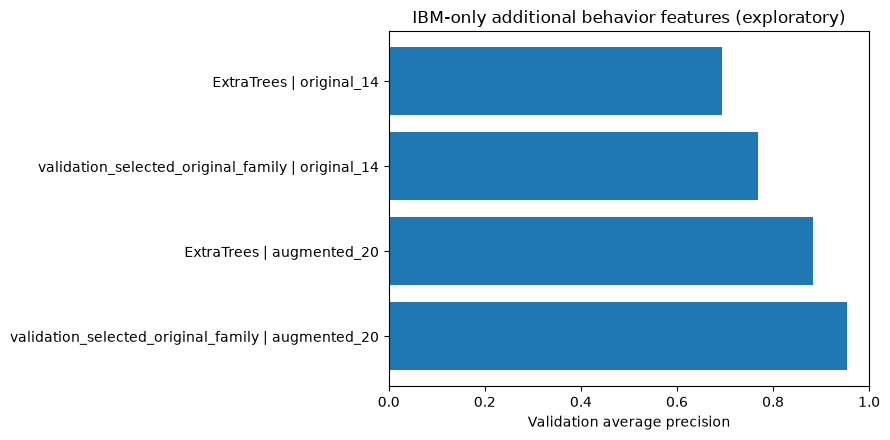

Augmented (validation_selected_original_family | augmented_20) on account-disjoint stress (n=618, pos=15): AP=0.9665, ROC-AUC=0.9991, F1=0.8276


In [36]:
from sklearn.ensemble import ExtraTreesClassifier


# Precompute the sg_id lookup once: avoids repeated DataFrame scans for 7,000+ subgraphs.
ibm_start_by_id = ibm_feat.set_index("sg_id")["t_start"].to_dict()

def transaction_activity_features(sg_id):
    """IBM-only features calculated without consulting laundering labels."""
    e = np.asarray(sets["ibm_edges"][sg_id], dtype=np.int64)
    n_transactions = int(e.size)
    if not n_transactions:
        return {"sg_id": sg_id, "n_transactions": 0,
                "transactions_per_hour": 0.0, "repeat_pair_fraction": 0.0,
                "dominant_pair_fraction": 0.0, "active_span_minutes": 0.0,
                "median_interarrival_minutes": 0.0}
    pairs = np.column_stack((idx.s[e], idx.d[e]))
    _, counts = np.unique(pairs, axis=0, return_counts=True)
    times = np.sort(idx.t[e])
    duration = max(1, int(original_end[sg_id] - ibm_start_by_id[sg_id]))
    return {"sg_id": sg_id,
            "n_transactions": n_transactions,
            "transactions_per_hour": float(60 * n_transactions / duration),
            "repeat_pair_fraction": float(1 - len(counts) / n_transactions),
            "dominant_pair_fraction": float(counts.max() / n_transactions),
            "active_span_minutes": float(times[-1] - times[0]),
            "median_interarrival_minutes": float(np.median(np.diff(times)))
            if n_transactions > 1 else 0.0}

activity = pd.DataFrame([transaction_activity_features(i) for i in ibm_feat.sg_id])
assert len(activity) == len(ibm_feat) and activity.sg_id.is_unique
extra_columns = [x for x in activity.columns if x != "sg_id"]
ibm_augmented = ibm_feat.merge(activity, on="sg_id", validate="one_to_one")
ibm_augmented.to_csv(EXT / "ibm_activity_feature_table.csv", index=False)

activity_results = []
activity_models = {
    "validation_selected_original_family": clone(selected_estimator),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=250, min_samples_leaf=2,
                                      class_weight="balanced", n_jobs=-1,
                                      random_state=EXT_SEED),
}
for family, base in activity_models.items():
    for feature_set, cols in (("original_14", list(FEATURES)),
                              ("augmented_20", list(FEATURES) + extra_columns)):
        fitted = clone(base).fit(ibm_augmented.iloc[ibm_fit_idx][cols],
                                 ibm_augmented.label.iloc[ibm_fit_idx])
        pv = fitted.predict_proba(ibm_augmented.iloc[ibm_val_idx][cols])[:, 1]
        threshold = best_thr(ibm_augmented.label.iloc[ibm_val_idx], pv)
        pt = fitted.predict_proba(ibm_augmented.iloc[ibm_test_idx][cols])[:, 1]
        activity_results.append({"family": family, "features": feature_set,
                                 "n_features": len(cols), "validation_AP": safe_ap(
                                     ibm_augmented.label.iloc[ibm_val_idx], pv),
                                 "threshold_from_validation": threshold,
                                 **measure(ibm_augmented.label.iloc[ibm_test_idx], pt, threshold)})
activity_table = pd.DataFrame(activity_results).sort_values("validation_AP", ascending=False)
activity_table["selected_by_validation"] = False
activity_table.loc[activity_table.index[0], "selected_by_validation"] = True
activity_table.to_csv(EXT / "IBM_activity_feature_experiment.csv", index=False)
display(activity_table[["family", "features", "n_features", "validation_AP", "AP", "AP_lift", "F1", "selected_by_validation"]].round(4))
print("Model/feature-set winner selected on VALIDATION AP, not test AP:",
      activity_table.iloc[0][["family", "features"]].to_dict())
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = activity_table.family + " | " + activity_table.features
ax.barh(labels, activity_table.validation_AP)
ax.set_xlabel("Validation average precision")
ax.set_title("IBM-only additional behavior features (exploratory)")
fig.tight_layout()
fig.savefig(EXT / "IBM_activity_validation_AP.png", dpi=160)
plt.show()
# Also evaluate the validation-winning augmented_20 model on the account-disjoint stress subset
win_fam = str(activity_table.iloc[0]["family"])
win_feat = str(activity_table.iloc[0]["features"])
win_cols = list(FEATURES) if win_feat == "original_14" else list(FEATURES) + extra_columns
win_model = clone(activity_models[win_fam]).fit(ibm_augmented.iloc[ibm_fit_idx][win_cols], ibm_augmented.label.iloc[ibm_fit_idx])
win_pv = win_model.predict_proba(ibm_augmented.iloc[ibm_val_idx][win_cols])[:, 1]
win_thr = best_thr(ibm_augmented.label.iloc[ibm_val_idx], win_pv)
ad_aug_df = ibm_augmented.iloc[account_disjoint_test]
if not ad_aug_df.empty and ad_aug_df.label.nunique() == 2:
    ad_aug_p = win_model.predict_proba(ad_aug_df[win_cols])[:, 1]
    ad_aug_m = measure(ad_aug_df.label.to_numpy(), ad_aug_p, win_thr)
    print(f"Augmented ({win_fam} | {win_feat}) on account-disjoint stress (n={len(ad_aug_df)}, pos={int(ad_aug_df.label.sum())}): "
          f"AP={ad_aug_m['AP']:.4f}, ROC-AUC={ad_aug_m['ROC_AUC']:.4f}, F1={ad_aug_m['F1']:.4f}")


## Extension 11 — Reproducibility and interpretation checklist

**Report these as separate findings:**

- **Original attempt-based benchmark** — historical metrics above; positive/negative construction differs and can inflate apparent performance.
- **Common-BFS sensitivity** — both classes grown with the same algorithm, with intentionally enriched positive seeds and a different target-label definition. AP cannot be compared directly without accounting for prevalence and task differences.
- **Account-disjoint and time-embargo stress tests** — compare sample retention first; tiny subsets should not support strong conclusions.
- **Ablation + permutation importance** — useful for interpreting predictive associations, not causal laundering indicators. Avoid choosing the final feature set on test results.
- **Threshold policies** — validation-only selection; report recall, precision, false positives and false negatives on test, not just AP or accuracy.
- **Domain-shift diagnosis** — differences across datasets are consistent with generalization difficulties, but do not uniquely identify a cause.

**Remaining work for a stronger paper:** use truly label-independent candidate generation with adequate coverage, external datasets with more comparable node/label semantics, multiple non-overlapping temporal test periods, calibrated probabilities and confidence intervals, a pre-registered primary metric, and evaluation under realistic base rates. Before suggesting deployment, obtain a privacy, fairness and human-oversight review. These results are educational research, not a deployable AML alert system.

In [37]:
# Machine-readable summary; values come ONLY from executed cells.
research_summary = {
    "seed": EXT_SEED,
    "data_inputs": ["IBM AML HI-Small", "Elliptic2"],
    "common_candidate_count": int(len(common_df)),
    "common_candidate_positive_rate": float(common_df.label.mean()),
    "common_seed_enrichment_fraction_requested": POSITIVE_SEED_PROBABILITY,
    "common_split_audit": common_audit.to_dict(orient="records"),
    "common_model_selected_by_validation": common_winner,
    "ibm_activity_candidate_selected_by_validation": activity_table.iloc[0][["family", "features"]].to_dict(),
    "original_model_selected_by_validation": selected_name,
    "selected_threshold_policies": {
        k: (None if v is None else float(v)) for k, v in thresholds.items()
    },
    "important_limitations": [
        "Positive seed enrichment changes candidate distribution and prevalence",
        "Common-sampler labels differ from original attempt-level labels",
        "Original benchmark accounts recur across fit/validation/test",
        "Account-disjoint stress tests may retain too few examples",
        "Feature ablations on the same held-out test are exploratory",
        "IBM and Elliptic2 node semantics/labels are not the same",
    ],
}
with open(EXT / "research_extension_summary.json", "w", encoding="utf-8") as fh:
    json.dump(research_summary, fh, indent=2, default=str)
print("Saved all new tables, figures, and research_extension_summary.json to:", EXT)
print("New data-driven scores have been calculated by the preceding cells, not prefilled.")

Saved all new tables, figures, and research_extension_summary.json to: <PROJECT_DIR>/outputs/research_extension
New data-driven scores have been calculated by the preceding cells, not prefilled.


## Extension 12 — Laundering typology recall & error analysis

**Purpose:** Break down outer-test detection recall across the 8 documented IBM laundering typologies (`CYCLE`, `BIPARTITE`, `FAN-IN`, `FAN-OUT`, `GATHER-SCATTER`, `SCATTER-GATHER`, `STACK`, `RANDOM`) for both the 14-feature structural model and the 20-feature activity-augmented model. This reveals which laundering structures are easily captured by topology alone and which require behavioral/temporal features.

IBM outer-test recall by laundering typology:


,test_count,median_nodes,recall_14feat,recall_20feat
pattern,,,,
CYCLE,8,8.0,1.000,1.000
SCATTER-GATHER,11,8.0,0.909,0.909
STACK,8,2.5,0.875,1.000
FAN-IN,12,10.0,0.750,0.750
GATHER-SCATTER,12,13.5,0.500,0.833
RANDOM,11,4.0,0.455,0.455
BIPARTITE,14,2.0,0.214,0.214
FAN-OUT,8,11.5,0.000,0.500


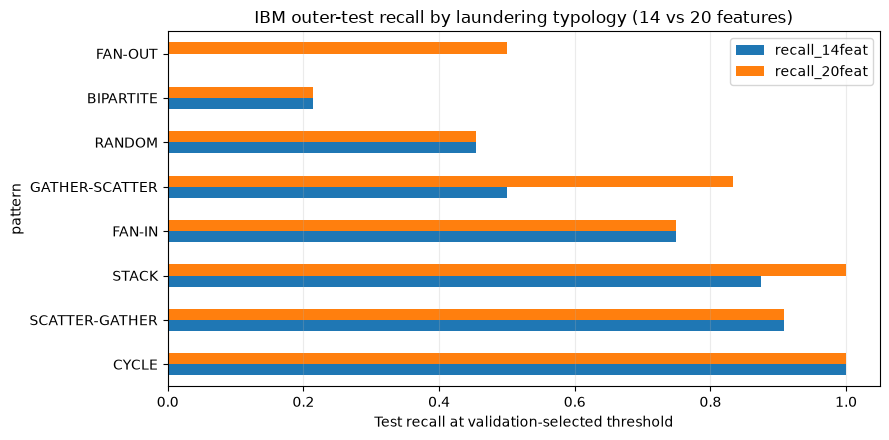

In [38]:
# Extension 12 | Typology-level recall breakdown on IBM outer test
test_meta = ibm_augmented.iloc[ibm_test_idx][["sg_id", "label", "pattern", "n_nodes", "n_edges"]].copy()
p_orig = selected_estimator.predict_proba(ibm_augmented.iloc[ibm_test_idx][selected_columns])[:, 1]
p_aug = win_model.predict_proba(ibm_augmented.iloc[ibm_test_idx][win_cols])[:, 1]

test_meta["pred_14feat"] = (p_orig >= selected_threshold).astype(int)
test_meta["pred_20feat"] = (p_aug >= win_thr).astype(int)

pos_test = test_meta[test_meta.label == 1]
if not pos_test.empty:
    typology_summary = pos_test.groupby("pattern").agg(
        test_count=("sg_id", "count"),
        median_nodes=("n_nodes", "median"),
        recall_14feat=("pred_14feat", "mean"),
        recall_20feat=("pred_20feat", "mean"),
    ).sort_values("recall_14feat", ascending=False)
    typology_summary.to_csv(EXT / "typology_recall_breakdown.csv")
    print("IBM outer-test recall by laundering typology:")
    display(typology_summary.round(3))

    fig, ax = plt.subplots(figsize=(9, 4.5))
    typology_summary[["recall_14feat", "recall_20feat"]].plot(kind="barh", ax=ax)
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Test recall at validation-selected threshold")
    ax.set_title("IBM outer-test recall by laundering typology (14 vs 20 features)")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(EXT / "typology_recall_breakdown.png", dpi=160)
    plt.show()
else:
    print("No positive test examples available for typology breakdown.")


# Final Summary & Conclusions

**Research question:** Can structural features of directed transaction subgraphs identify suspicious activity, and do models trained on synthetic bank data (IBM AML HI-Small) transfer to real cryptocurrency graphs (Elliptic2)?

### Main findings
1. **Within IBM, graph structure is strongly informative.** Tuned Gradient Boosting reaches outer-test AP 0.622 (95% CI 0.523–0.720) against a 0.050 positive rate (≈12× lift; ROC-AUC 0.888). The size-only baseline reaches only AP ≈0.25, and topology without size (AP 0.566) performs about as well as all 14 features (AP 0.568). So the signal is structural, not just graph size.
2. **The signal does not transfer.** IBM → Elliptic2 AP is 0.022–0.023 at a 0.023 positive rate (lift ≈1.0). Within-Elliptic2 performance is also near random (AP ≈0.025, lift ≈1.1), and Elliptic2 → IBM stays weak (AP 0.04–0.11 against 0.050). Domain-shift diagnostics show large distribution gaps in degree inequality (KS 0.60), normalised longest chain (KS 0.58), density (KS 0.49) and size (KS 0.48).
3. **Within IBM, hyperparameter tuning barely changed ranking quality.** Within-IBM tuned and default models differ by less than ±0.015 AP, well inside the confidence intervals (cross-domain Elliptic2 → IBM Gradient Boosting rose from 0.043 to 0.086, still weak). Validation-only Platt calibration made the probabilities much more reliable (e.g. IBM Gradient Boosting test Brier 0.099 → 0.026) without changing the ranking.
4. **Part of the IBM separation comes from how the subgraphs were constructed.** When both classes are grown by the same label-blind BFS, models still beat the size-only baseline (AP 0.726 vs 0.650; ROC-AUC 0.61 vs 0.48), but the lift over prevalence is small (≈1.1×).
5. **The signal is not just recurring accounts, but it gets weaker.** A fully account-disjoint retrain gives test AP 0.674 and ROC-AUC 0.761, below the main split's ROC-AUC 0.875–0.888.
6. **Transaction-activity features are the largest gain (IBM only).** Adding six label-free activity features (transaction count, rate, repeated-pair share, dominant-pair share, active span, median gap) raises IBM test AP from 0.568 to 0.860 and F1 from 0.48 to 0.80.
7. **Detection varies by typology.** Recall is high for CYCLE, SCATTER-GATHER and STACK, but low for BIPARTITE (0.21) and FAN-OUT (0.00 with 14 features → 0.50 with 20).

### Limitations
Positive and negative IBM subgraphs are produced by different mechanisms. IBM and Elliptic2 differ in node semantics and label definitions. IBM is evaluated on a single chronological split. Positive rates in the constructed samples do not reflect real deployment base rates.

### Outputs
Core results are in `outputs/`; research-extension tables and figures are in `outputs/research_extension/`.